# Эксперимент 4 — плотность против топологии

## Что здесь происходит

Эксперимент 1 установил, что нейрон-свидетель появляется тогда, когда особенность **нужна задаче**:
одна и та же окружность дала свидетеля у 49 моделей из 50 там, где она разделяет классы, и у 0 из 50
там, где не разделяет. Эксперимент 2 показал, что это не артефакт архитектуры.

Оба оставили открытым одно конкурирующее объяснение. В обоих датасетах task-relevant окружность была
**заодно и местом, где точки лежат плотнее всего**, а `RESEARCH_PROGRAMME.md` держит в списке
конфаундов гипотезу «линии уровня липнут к сгущениям точек». Пока эти два обстоятельства совпадают,
вывод «свидетель появляется из-за релевантности» держится не крепче, чем «свидетель появляется из-за
плотности».

## Главная цель

**Развести два объяснения появления нейрона-свидетеля — «задача вынуждает замкнутую границу в этом
месте» и «в этом месте точки лежат плотнее» — и измерить, что из этого на самом деле управляет
качеством свидетеля.**

## Задачи

| | вопрос | чем отвечаем |
|---|---|---|
| **D** | относительно чего вообще считать скор — что есть мишень, что есть пол, где порог? | четыре мишени и их нули в каждой конфигурации по отдельности |
| **A** | может ли одна плотность изготовить свидетеля там, где задача особенности не видит? | 9 task-irrelevant ячеек: ширина кольца × баланс классов |
| **B** | что определяет качество свидетеля там, где особенность задаче нужна? | 18 task-relevant ячеек: ширина × радиус диска × баланс |
| **C** | это про плотность или про число точек? | те же ячейки при впятеро большей выборке |
| **F** | что говорит о тех же данных второй критерий? | гомологический `persistence_margin` на тех же нейронах |
| **E** | что говорит сама обучаемость ячейки? | доля инициализаций, дошедших до 100 % accuracy — вынесена в приложение |

**Задача D стоит первой намеренно.** Без неё непонятно, относительно чего считаются скоры в A–C:
там, где особенность стала кольцом, мишень перестаёт задаваться однозначно, и выбор между
кандидатами надо сделать и обосновать до того, как читать вердикты. Буквенная нумерация оставлена
исторической — она отражает порядок, в котором задачи задумывались, а не порядок изложения.

Дизайн и его обоснование — в `exp4_design_walkthrough.ipynb`. Здесь исполнение: 40 ячеек × 50 моделей
`tanh w5 d5`, 551 250 оценённых строк, ~26 часов оценки на 32 ядрах.

In [1]:
import os, sys, math
os.environ.setdefault("OMP_NUM_THREADS", "1")
from pathlib import Path

root = Path.cwd()
while not (root / "src" / "analysis").is_dir():
    assert root != root.parent, "корень репозитория не найден"
    root = root.parent
os.chdir(root)
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220)

import analysis.density_sweep as dsw
from visualization import density_sweep_plots as dplt

df    = dsw.load_neuron_stats()   # строка = (ячейка, модель, НЕЙРОН, фича) — 551 250 штук
best  = dsw.best_by_model(df)     # строка = (ячейка, модель, фича), её ЛУЧШИЙ нейрон
cells = dsw.cell_table(best)      # строка = (ячейка, мишень): порог, доля, интервалы

GRID_STEP = 15.0 / (222 - 1)      # шаг сетки, на которой считались линии уровня

def C(**kw):
    # имена ячеек, отобранные по координатам
    return [n for n in sorted(cells.cell.unique())
            if all(dsw.cell_of(n)[k] == v for k, v in kw.items())]

ANCHOR = "d4_rel_w00_R100_r100_T1000"
W3, RHO3 = (0.0, 0.5, 1.0), (0.25, 1.0, 4.0)

IRR = [n for w in W3 for rho in RHO3 for n in C(task="irrelevant", w=w, rho=rho, T=1000)]
REL = [n for w in W3 for R in (0.25, 0.5) for rho in RHO3
       for n in C(task="relevant", w=w, R=R, rho=rho, T=1000)]
BIG = ([n for w in (0.5, 1.0) for rho in RHO3 for n in C(task="irrelevant", w=w, rho=rho, T=5000)]
     + [n for w in (0.5, 1.0) for rho in RHO3 for n in C(task="relevant", w=w, rho=rho, T=5000)])

print(f"оценённых строк     {len(df):>8,}")
print(f"пар (модель, фича)  {len(best):>8,}")
print(f"ячеек               {cells.cell.nunique():>8}   "
      f"= A {len(IRR)} + B {len(REL)} + C {len(BIG)} + якорь 1")

def FAM(w):
    # мишень вердикта (§2.6) — внутренний край кольца; при w = 0 кольцо
    # вырождается в окружность, и её внутренний край есть она сама
    return "t_inner" if w > 0 else "t_mid"

EDGE = dsw.inner_edge(cells)      # строки cells для мишени вердикта


def label(name):
    # шапки строк и столбцов несут w, R и rho; на панели остаются числа точек
    c = dsw.cell_of(name)
    nr = dsw.n_ring_of(c["rho"], c["T"])
    return f"{nr}:{c['T'] - nr}"

def ratio_label(rho):
    # баланс как отношение: 0.25 -> "1:4", 1 -> "1:1", 4 -> "4:1"
    return f"1:{int(round(1/rho))}" if rho < 1 else f"{int(round(rho))}:1"

def row_label(name):
    c = dsw.cell_of(name)
    return f"R={c['R']}\n{ratio_label(c['rho'])}\nT={c['T']}"

оценённых строк      551,250
пар (модель, фича)    22,050
ячеек                     40   = A 9 + B 18 + C 12 + якорь 1


---

# 1. Устройство датасета: плотность меняется геометрией при постоянном числе точек

Окружность экспериментов 1 и 2 заменена **кольцом ширины `w`**: точки равномерны по площади полосы
`[1.5 − w/2, 1.5 + w/2]`. Внутренность — **диск радиуса `R`** противоположного класса.

**Идея приёма проста.** У каждого объекта фиксированное число точек. Расширяя кольцо, мы **не
добавляем и не убираем точек** — мы раскладываем ту же самую массу по большей площади, и она лежит
реже. Сужая до нуля, собираем всё обратно на кривую, где она лежит настолько плотно, насколько
вообще возможно при этом числе точек. Это и есть ось плотности: смотреть на неё надо как на «те же
точки, разложенные теснее или свободнее», и на картинке ниже это видно прямо.

Что при этом **не** меняется вместе с плотностью:

* **баланс классов** — он вынесен в отдельную ось `ρ = n_кольца / n_диска`;
* **суммарное число точек** — оно третья ось, `T`;
* **бокс, сетка, критерий, архитектура** — они одни и те же во всех ячейках.

`w = 0` — это ровно окружность эксперимента 1, самый плотный конец оси. Ничего исключительного в этой
точке нет: критерий обрабатывает её так же, как любое другое облако, и её результаты — предельная
точка нашего свипа.

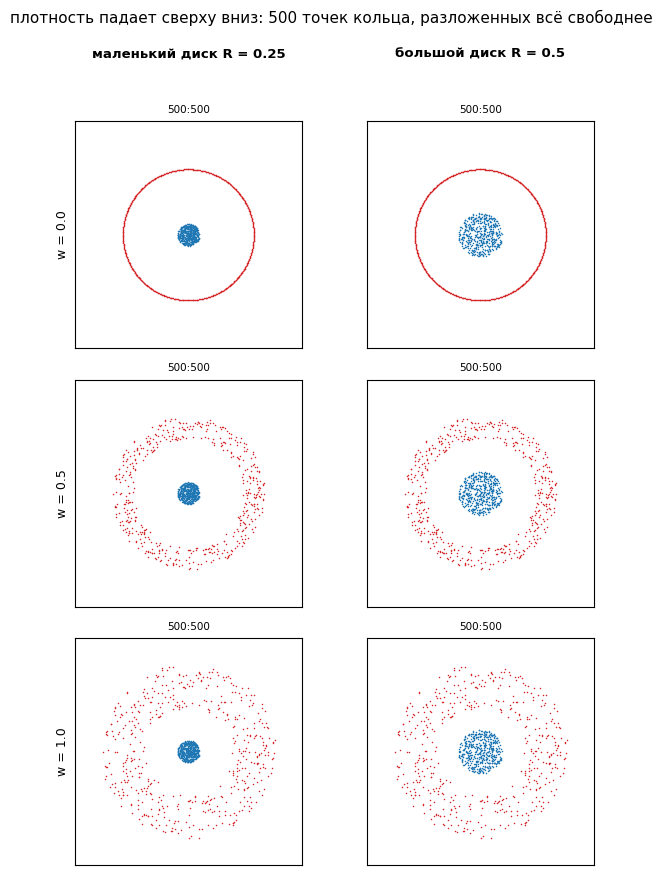

In [2]:
# Три ширины кольца и два радиуса диска при 500:500. Между панелями строки число точек
# не меняется — меняется только то, по какой площади они разложены.
show = [n for w in W3 for R in (0.25, 0.5) for n in C(task="relevant", w=w, R=R, rho=1.0, T=1000)]
fig = dplt.plot_dataset_grid(show, dsw.dataset_points, ncols=2, size=2.7,
                             xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), label_of=label,
                             row_labels=[f"w = {w}" for w in W3],
                             col_labels=["маленький диск R = 0.25", "большой диск R = 0.5"],
                             title="плотность падает сверху вниз: 500 точек кольца, разложенных всё свободнее")
plt.show()

### Одна количественная привязка — и дальше только «плотнее / реже»

Числом плотность в этом эксперименте не нужна: все утверждения ниже качественные, вида «стало реже —
изменилось ли что-нибудь». Но одну привязку полезно иметь, чтобы понимать, **в каком диапазоне
работает свип относительно самого инструмента**. Возьмём среднее расстояние между соседними точками
кольца и сравним его с шагом сетки, на которой считаются линии уровня.

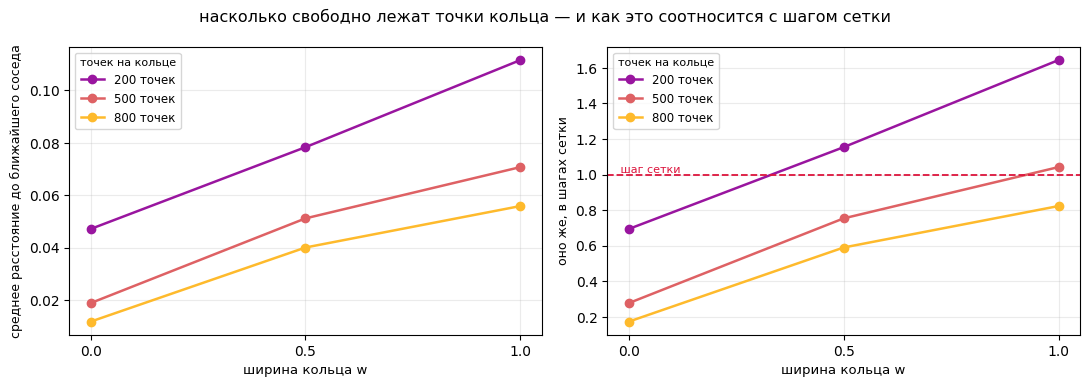

In [3]:
sp = dsw.spacing_table(REL)
ring = sp[sp["объект"] == "кольцо"].drop_duplicates(["w", "n_ring"])
fig = dplt.plot_spacing(ring, GRID_STEP,
    title="насколько свободно лежат точки кольца — и как это соотносится с шагом сетки")
plt.show()

### Что видно

**Свип проводит выборку через разрешение инструмента — при том числе точек, которое мы выбрали.**
Оба края оси зависят и от ширины, и от числа точек: при 500 точках на кольце расстояние до соседа
идёт 0.019 → 0.051 → 0.071 по трём ширинам, то есть от втрое плотнее шага сетки до вровень с ним; при
200 точках вся линия сдвинута вверх и уже при `w = 0.5` лежит реже сетки. Существенно то, что
диапазон выбран содержательно: если бы плотность обучающих точек вообще на что-то влияла, здесь это
должно было бы проявиться.

**Это расстояние — про данные, а не про инструмент.** Дальше встретится похожая величина `δ(A)` —
шаг **мишени**, по которой считается скор, и у неё своё, отдельное условие относительно шага сетки
(§2.1). Путать их нельзя: здесь мы меряем манипулируемую переменную эксперимента, там — разрешающую
способность прибора.

**Шаги оси неравны.** Переход `w = 0 → 0.5` разрежает точки сильнее, чем `0.5 → 1.0` (площадь растёт
линейно, а расстояние между точками — как корень). Поэтому по этой оси надо читать **наличие и знак**
эффекта, а не наклон.

Дальше слово «плотность» употребляется в обычном смысле — насколько тесно лежат точки объекта, — и
все выводы по ней качественные.

---

## 1.1 А точно ли эти датасеты task-relevant?

Прежде чем что-то мерить на сетях, стоит убедиться, что мерить есть что. Мы называем половину
конфигураций task-relevant по построению — кольцо вокруг диска противоположного класса, — но это
утверждение **о данных**, и его надо не предполагать, а проверить.

**Проверка есть, и она не требует ни одной обученной модели.** Хроматический альфа-комплекс строится
на самом раскрашенном облаке точек. Интересующая величина — **kernel** отображения из подкомплекса
класса 0 (кольцо) в полный комплекс: цикл из точек кольца, который **умирает**, как только добавлены
точки диска. То есть дырка одного класса, заполненная другим, — ровно определение task-relevant
топологической особенности (`PLAN.md` A.8).

Это эталон, лежащий уровнем ниже нейросети: он говорит, есть ли особенность в задаче, независимо от
того, нашла ли её какая-нибудь модель.

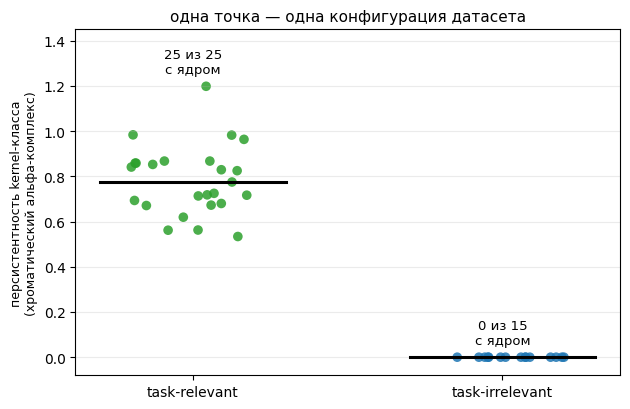

               min  median     max
task                              
irrelevant  0.0000  0.0000  0.0000
relevant    0.5337  0.7748  1.1982


In [4]:
chrom = dsw.chromatic_task_relevance(sorted(cells.cell.unique()))
fig, ax = plt.subplots(figsize=(6.4, 4.2))
rng = np.random.default_rng(0)
for i, (task, colour) in enumerate((("relevant", dplt.CT), ("irrelevant", dplt.C1))):
    v = chrom[chrom.task == task]["kernel_persistence"].to_numpy()
    ax.scatter(i + rng.uniform(-.2, .2, len(v)), v, s=48, color=colour, alpha=.85,
               edgecolors="none")
    ax.plot([i - .3, i + .3], [np.median(v)] * 2, color="k", lw=2.2, zorder=5)
    ax.text(i, max(v) + .06, f"{(v > 0).sum()} из {len(v)}\nс ядром", ha="center", fontsize=9.5)
ax.set_xticks([0, 1]); ax.set_xticklabels(["task-relevant", "task-irrelevant"], fontsize=10)
ax.set_ylabel("персистентность kernel-класса\n(хроматический альфа-комплекс)", fontsize=9)
ax.set_ylim(-0.08, 1.45); ax.grid(alpha=.25, axis="y")
ax.set_title("одна точка — одна конфигурация датасета", fontsize=11)
plt.tight_layout(); plt.show()

print(chrom.groupby("task")["kernel_persistence"].agg(["min", "median", "max"]).round(4).to_string())

### Что видно

**Эталон разделяет наши датасеты начисто.** Persistent kernel-класс есть в **25 конфигурациях из 25**
task-relevant и **ни в одной из 15** task-irrelevant: персистентность там равна ровно нулю, а здесь
лежит в 0.53–1.20. Промежуточной зоны нет.

**Это понадобится дважды.** Во-первых, все 25 релевантных конфигураций — **положительные примеры**, и
несрабатывание детектора на любой из них есть ошибка, а не информация; на этом будет стоять выбор
мишени (§2.6). Во-вторых, все 15 нерелевантных — **отрицательные**, и это делает задачу A измерением,
а не предположением.

**Одно наблюдение, которое не надо переоценивать.** Персистентность варьирует среди релевантных
конфигураций (0.53–1.20). Соблазнительно прочитать это как «степень релевантности», но величина
выражена в единицах альфа-фильтрации, то есть в квадрате длины, и падает с ростом ширины кольца просто
потому, что внутренний радиус — а с ним и сама дырка — уменьшается. Различие здесь в основном
геометрическое, и дальше используется только бинарная его часть: ядро есть или его нет.

---

# 2. Задача D — относительно чего считается структурный скор

**Вопрос.** Структурный критерий сравнивает линию уровня нейрона с **мишенью** `A` и возвращает
`расстояние Чамфера / диаметр A`. Пока особенность была окружностью, мишень задавалась однозначно.
Как только она стала кольцом, это перестало быть так: мишенью можно взять само кольцо, а можно любую
окружность внутри него. От выбора зависят все числа задач A–C, поэтому он делается здесь и первым.

**Рамка, которая держит всю секцию.** Нуль-фича — негативный контроль, и он принадлежит **конкретной
конфигурации датасета**: своим 50 моделям, своей геометрии, своему полю. Поэтому распределения
рассматриваются только внутри одной конфигурации, а всякое сводное число ниже есть **медиана
по-конфигурационных величин**, а не величина, посчитанная по объединённым данным.

**Порядок изложения.** Сначала — что вообще есть мишень и как мелко её нужно семплировать (§2.1),
затем нули, у которых свободен только один параметр (§2.2), затем данные, конфигурация за
конфигурацией (§2.3). Дальше два вопроса о справедливости сравнения: одинаково ли достижимы мишени
(§2.4) и насколько каждая отличает цель от собственного пола (§2.5). На этом мишень выбирается (§2.6)
— и только потом ставится порог (§2.7), потому что выбор мишени ни на каком пороге не стоит.
Заканчивается секция побочным результатом четырёх мишеней (§2.8) и вторым условием вердикта (§2.9).

## 2.1 Что такое мишень

### Мишень есть выборка области пространства, а не обучающие данные

Это самое важное для понимания того, что именно мы меряем, и здесь стоит остановиться.

**Мы меряем не то, на какие места обучающей выборки нейрон обращает внимание, а то, согласуется ли
его линия уровня с областью пространства, которую мы решили опросить.** Область может совпадать с
той, где лежат данные, а может и не совпадать; и мы вправе семплировать её точки сами, чтобы получить
более точных её представителей, чем дало бы обучающее облако.

В этом эксперименте так и есть. Три концентрические окружности — по внутреннему краю кольца, по его
средней линии и по внешнему краю — **не существуют в данных вовсе**. В датасете есть кольцо; окружности
построены нами специально, чтобы спросить, **на каком радиусе** лежат линии уровня. Ничего контрабандой
при этом не проносится: критерий спрашивает, согласуется ли линия уровня с областью, которую мы
**назвали**, и назвать её — наше право.

Именно это делает вопрос осмысленным за пределами чистых синтетических данных. На зашумлённых или
реальных данных никакой породившей кривой нет, и вопрос «обводит ли нейрон объект» повис бы без
референта. А вопрос «согласуется ли линия уровня с этой областью сильнее, чем с той же областью,
положенной в другое место» — не повисает, и отвечать на него можно, имея лишь саму область и её
жёсткие движения.

Отсюда и число точек в мишени: оно **наше решение**, одинаковое во всех сорока конфигурациях (500 на
окружность, 1000 на кольцо), а не отражение того, насколько густо данные заняли эту область. Как
мелко эту область нужно разрешать — отдельный вопрос, и у него есть точный ответ.

### Четыре кандидата и мотивы за них

| кандидат | мотив |
|---|---|
| **кольцо** `t_ring` | самый честный: фича и есть кольцо, никакой дополнительной инженерии |
| **средняя окружность** `t_mid` | подстановка окружности вместо кольца вносит сдвиг; из всех окружностей его минимизирует та, что ближе всего к кольцу — и это она |
| **внутренняя окружность** `t_inner` | если релевантная особенность образуется в равной мере фичей и её внутренностью противоположного класса, то смотреть надо на зону их взаимодействия — на внутренний край |
| **внешняя окружность** `t_outer` | своего мотива нет; нужна как **скобка**, чтобы увидеть, монотонен ли скор по радиусу зондирования |

Все четыре посчитаны на **одних и тех же моделях** в каждой конфигурации, поэтому сравнение между
ними ничем не смешано. При `w = 0` все три окружности **совпадают** — там это одна и та же фича, — и
в этой секции такие ячейки не рассматриваются.

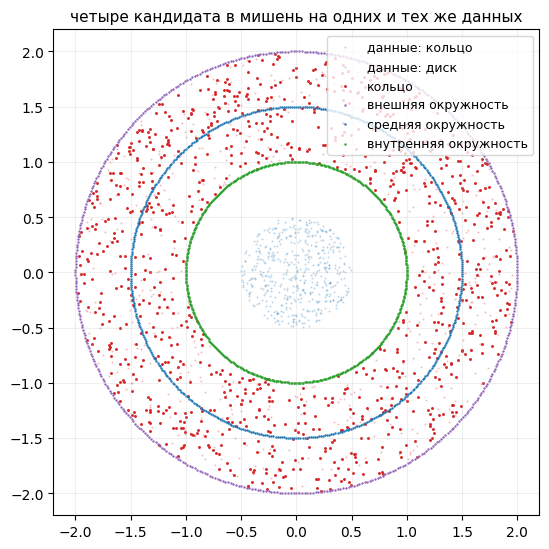

In [5]:
fig = dplt.plot_target_shapes(dsw.dataset_points, "d4_rel_w10_R050_r100_T1000")
plt.show()

### Насколько мелко надо семплировать мишень: условие `δ(A) < h`

Обозначим `δ(A)` типичное расстояние между соседними точками **мишени**, а `h = 0.0679` — шаг сетки,
на которой извлекаются линии уровня. (Это не та величина, что в §1: там мерилось расстояние между
точками **данных**, здесь — между точками мишени.)

У первого слагаемого Чамфера, `mean_{c∈C} d(c, A)`, есть **нижняя граница**: точка, лежащая **точно
на** области, всё равно найдёт ближайшую **выбранную** точку примерно в `δ/2` от себя — просто потому,
что между выбранными точками пусто. У компоненты уровня своя нижняя граница, `≈ h/2`: мельче шага
сетки её не локализовать. Два источника независимы, поэтому лучшее достижимое расстояние составляет
примерно

```
sqrt( (h/2)² + (δ(A)/2)² )
```

и дискретизация мишени безобидна ровно тогда, когда `δ(A) < h`. Выше этого **мерная линейка грубее
измеряемого**, и скор перестаёт говорить о сети.

Формула не постулируется: в §2.4 достижимые скоры измеряются напрямую, подстановкой в критерий поля,
какое было бы у идеального детектора каждой формы. Вот её предсказание рядом с тем измерением —
колонка «предсказано» получена формулой выше, колонка «измерено» взята из §2.4:

| мишень | `δ(A)` | `δ/h` | предсказано формулой | измерено в §2.4 |
|---|---|---|---|---|
| окружность `r = 1.0`, 500 точек | 0.0126 | 0.19 | 0.0345 | **0.0337** |
| окружность `r = 1.5`, 500 точек | 0.0188 | 0.28 | 0.0352 | **0.0342** |
| окружность `r = 2.0`, 500 точек | 0.0251 | 0.37 | 0.0362 | **0.0360** |
| **кольцо, 1000 точек** | **0.097** | **1.43** | 0.0592 | **0.0491** |

Для окружностей совпадение в третьем знаке — модель верна. А кольцо единственное имеет `δ/h > 1`, и
причина понятна: те же тысяча точек должны покрыть **площадь**, а не кривую, поэтому `δ = sqrt(S/n)`
неизбежно грубее. Кольцо ограничено собственной выборкой, а не сеткой.

### Два следствия, которые стоит записать

**Мишени нельзя позволять следовать за данными.** Если взять `A` = точки датасета, то у кольца
`δ = sqrt(площадь/n)`, а `n` — это ось `ρ`, манипулируемая переменная эксперимента. Прибор мерил бы
разреженные ячейки более грубой линейкой, чем плотные: при `ρ = 0.25` (200 точек) вышло бы
`δ/h = 3.2`, втрое за границей применимости, и именно в той ячейке, где мы находим худший результат.

**Уплотнить эталон кольца — тоже не выход.** Соблазнительно решить, что кольцо просто недосемплировано
и при более плотном эталоне окажется лучшей мишенью. Померено: при изменении эталона в шестнадцать раз
(250 → 4000 точек) медиана скора не двигается вовсе (0.3778 → 0.3800), а лучший нейрон улучшается на
6 % — при том что различающая способность у кольца 1.57 против 2.32 у средней окружности и 4.79 у
внутреннего края (§2.5), то есть отставание там несопоставимо больше.
Причина в том, что нижняя граница кольца (0.049) в восемь раз ниже его же типичного скора (0.414):
дискретизация ограничивает только лучшие нейроны, а различает — типичные.

Правило записано в `RESEARCH_PROGRAMME.md` §8 и `PROJECT.md`: если объект существует в данных и его
собственная выборка грубее сетки, надо либо сгущать сетку, либо честно сказать, что этой сеткой объект
не разрешается.

## 2.2 Нули: те же мишени, перенесённые

Скор сам по себе ничего не значит: 0.15 — это хорошо или плохо, зависит от того, чего стоит получить
0.15 случайно. Нужен пол, и его дают **нули A.1**.

**У нуля свободен ровно один параметр — место.** Всё остальное задано мишенью: нуль есть **та же
самая фигура**, того же размера, с тем же числом точек, сдвинутая жёстким движением туда, где задача
ничего не требует. Проверено на данных: числа точек совпадают во всех конфигурациях и на всех четырёх
мишенях, а после совмещения центров облака цели и нуля отличаются на 3·10⁻⁷ — округление float32.
Иначе и быть не должно: если бы нуль отличался от цели хоть чем-то кроме положения, контраст «цель
против пола» перестал бы изолировать положение.

**А место выбирается, и вот как.** Размещений три, и они **не двигаются между ячейками**: два вдали
от границы решения в разных направлениях (`far_right` в `(4.5, 0)`, `above_target` в `(0, 4.5)`) и
одно в коридоре у границы (`in_corridor` в `(−3.5, −3.0)`) — последнее только в task-irrelevant, где
коридор существует. Эксперимент 1 померил, что пол существенно зависит от места, поэтому подвижное
размещение сделало бы пол несравнимым вдоль свипа.

**Следствие, которое надо назвать:** в task-relevant задаче размещений **два**, а вердикт выносится
именно там.

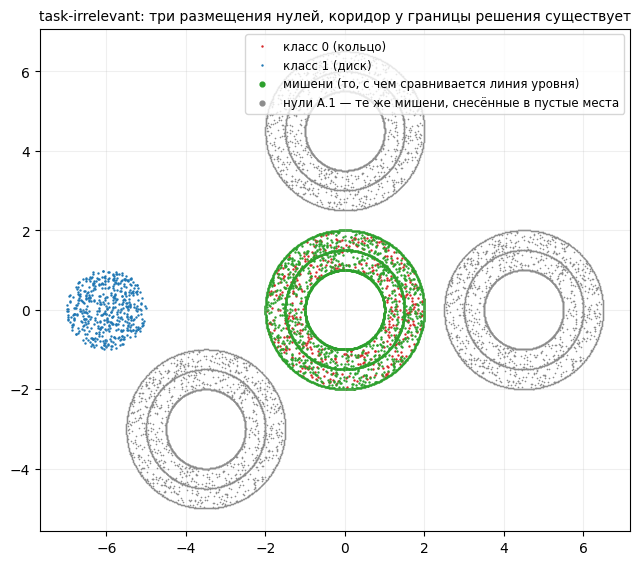

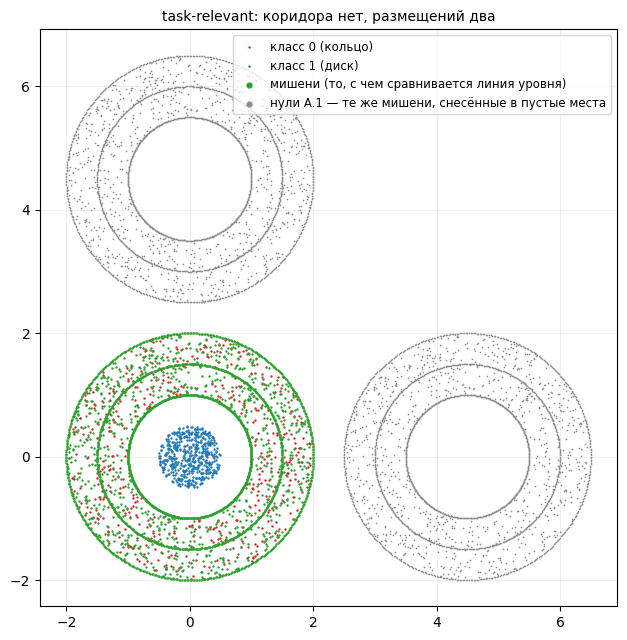

In [6]:
for cell, title in (("d4_irr_w10_R100_r100_T1000",
                     "task-irrelevant: три размещения нулей, коридор у границы решения существует"),
                    ("d4_rel_w10_R050_r100_T1000",
                     "task-relevant: коридора нет, размещений два")):
    fig = dplt.plot_targets_and_nulls(cell, dsw.dataset_points, title=title)
    plt.show()

## 2.3 Все конфигурации по отдельности

Мишени и пол определены — можно смотреть на данные. Четыре фигуры ниже показывают **всё**, и на них
стоит вся дальнейшая секция.

Строка — одна конфигурация датасета (слева нарисована она сама), столбец — одна мишень. В каждой
панели видна **вся популяция**: серым сверху нули, цветом снизу цель, чёрточками — медианы. Число
**×N** — во сколько раз медиана цели лучше медианы её нулей; это безразмерный зазор, и он ни от
какого порога не зависит. Красный пунктир — порог, а число **доля** — доля моделей, его прошедших;
**выбор уровня порога обосновывается позже, в §2.7**, здесь он нужен только как ориентир.

Разбито на четыре блока по задаче и ширине кольца: именно эти две координаты меняют геометрию мишеней
и нулей. Внутри блока строки — это радиус диска, баланс и объём выборки.

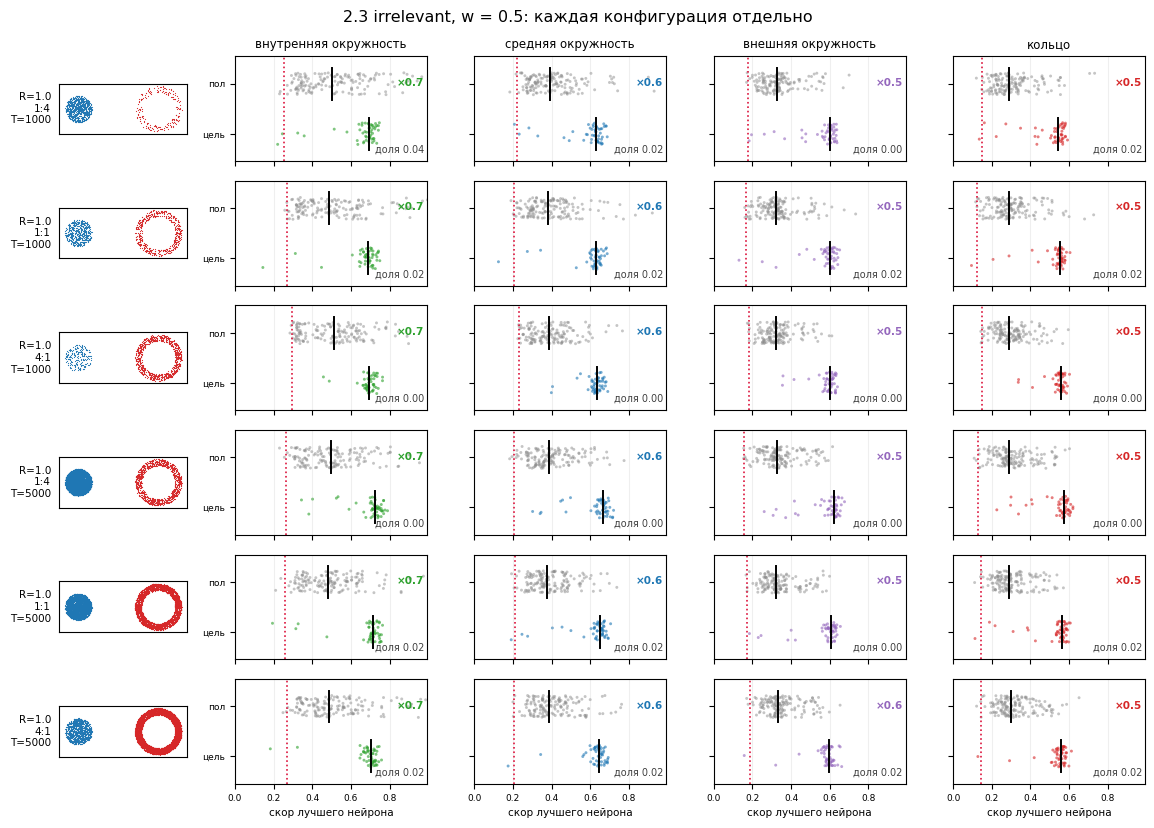

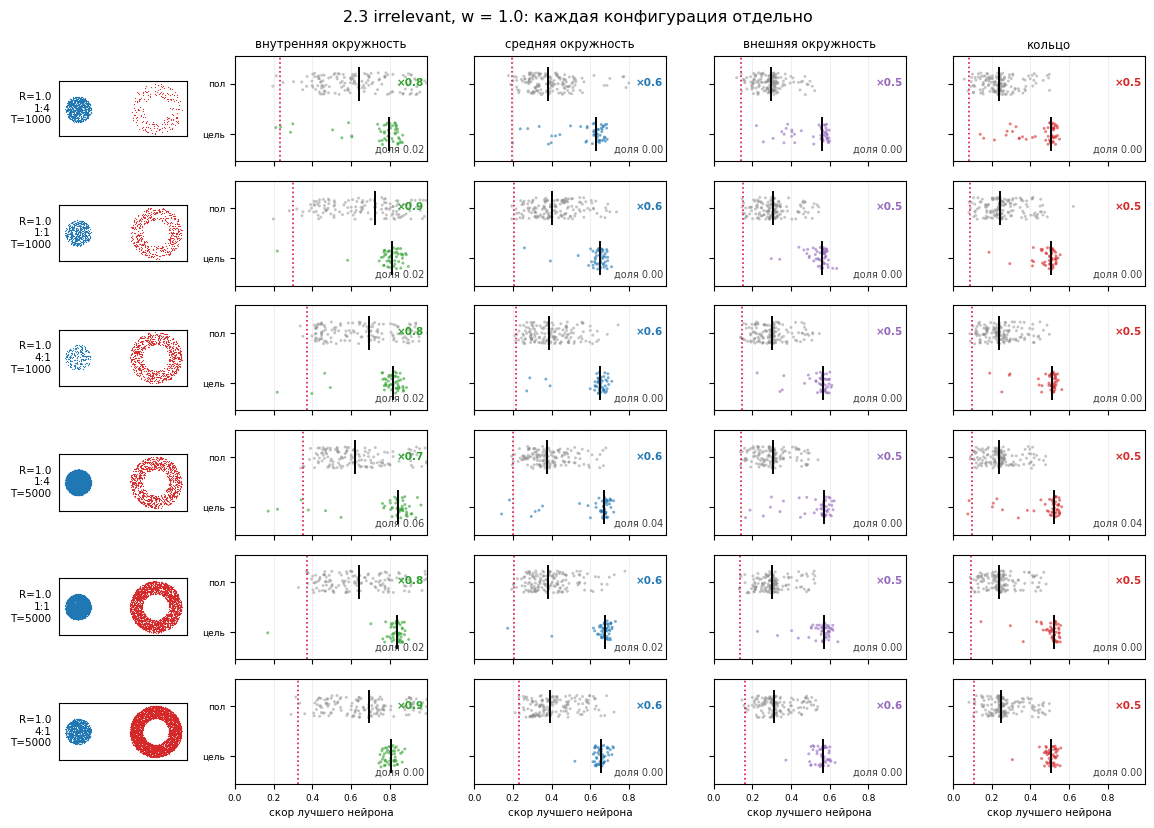

In [7]:
BLOCKS = []
for task in ("irrelevant", "relevant"):
    for w in (0.5, 1.0):
        names = [n for n in sorted(cells.cell.unique())
                 if dsw.cell_of(n)["task"] == task and dsw.cell_of(n)["w"] == w]
        names.sort(key=lambda n: (dsw.cell_of(n)["T"], dsw.cell_of(n)["R"], dsw.cell_of(n)["rho"]))
        BLOCKS.append((f"{task}, w = {w}", names))
XMAX = float(np.quantile(best[best.w > 0].score.dropna(), 0.995))
for name, names in BLOCKS[:2]:
    fig = dplt.plot_config_panels(names, best, cells, dsw.dataset_points, xmax=XMAX,
        row_label=row_label, title=f"2.3 {name}: каждая конфигурация отдельно")
    plt.show()

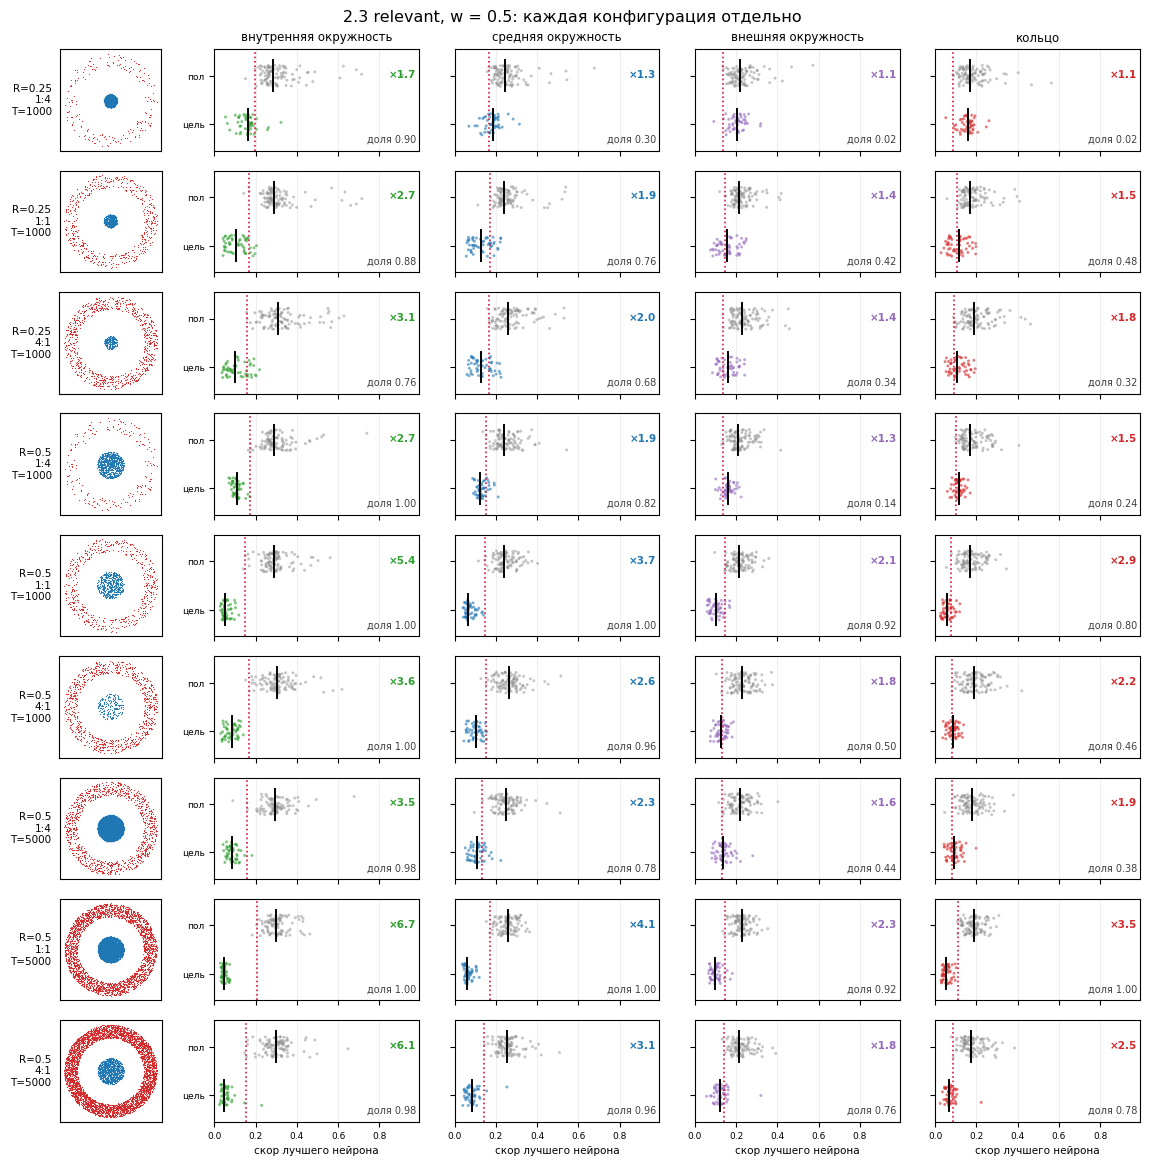

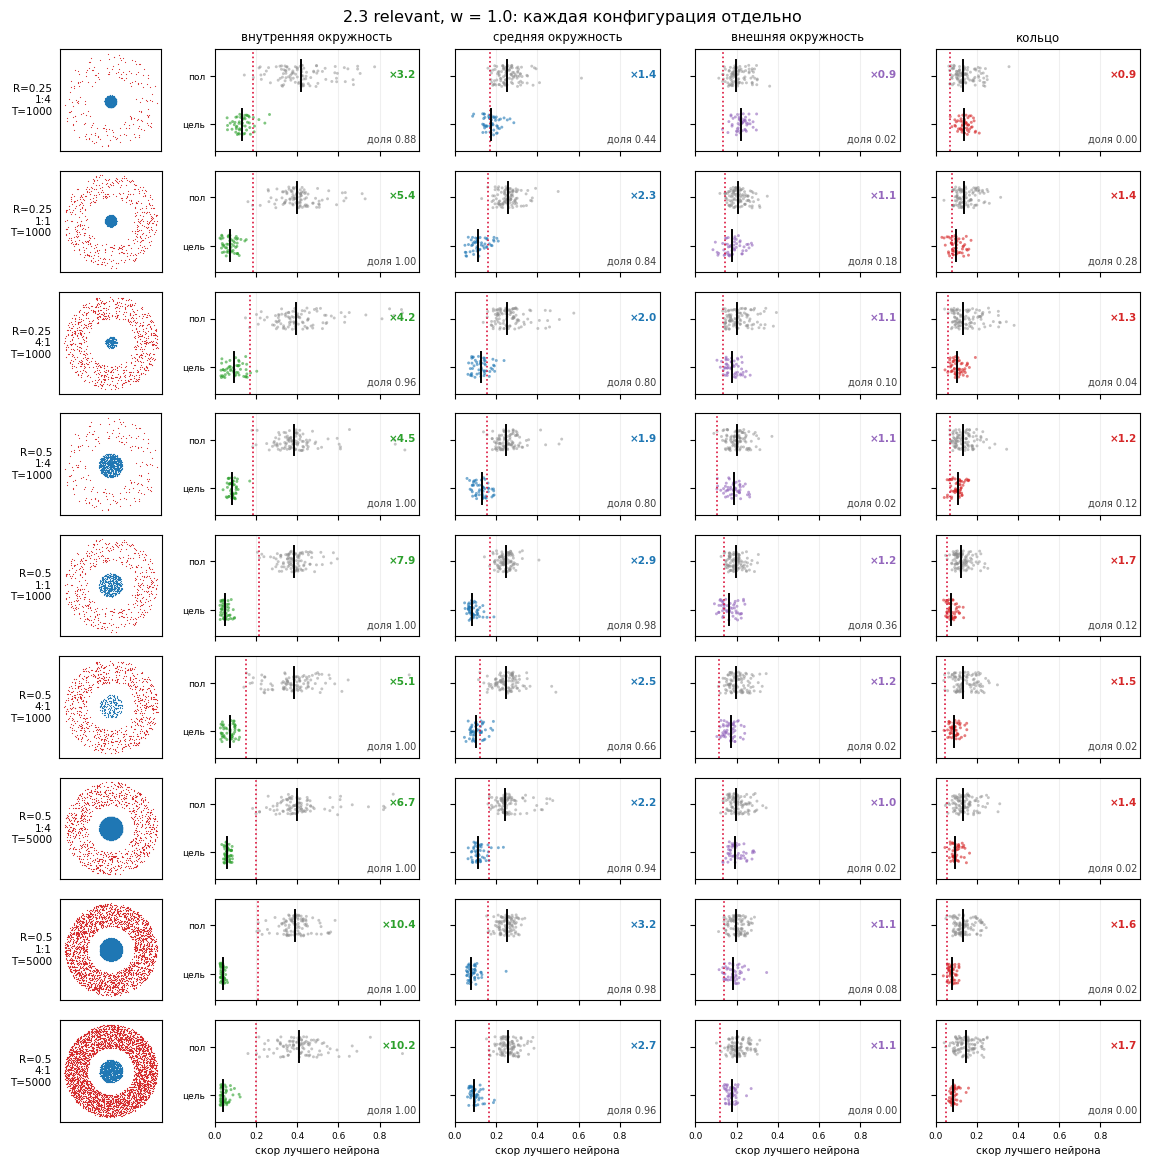

In [8]:
for name, names in BLOCKS[2:]:
    fig = dplt.plot_config_panels(names, best, cells, dsw.dataset_points, xmax=XMAX,
        row_label=row_label, title=f"2.3 {name}: каждая конфигурация отдельно")
    plt.show()

### Что видно

**Картина одинакова во всех конфигурациях внутри задачи и противоположна между задачами.** В
нерелевантных блоках цель лежит **правее** своих нулей во всех двенадцати конфигурациях и на всех
четырёх мишенях; в релевантных — левее, тоже везде. Вывод держится не в среднем, а в каждой
конфигурации по отдельности.

**Разделение цели и пола — распределительное, а не полное.** Внутри конфигурации хвост цели заходит
на территорию нулей: на средней окружности худшая модель хуже лучшего нуля в 17 релевантных
конфигурациях из 18. На внутреннем крае — который и станет мишенью вердикта — это случается лишь в 8
из 18, но и там полного разделения нет. Правильная формулировка поэтому не «цель не пересекается с
полом», а «`p_superior` = 0.87–1.00 по конфигурациям» (у внутреннего края 0.97–1.00).

**Мишени выстраиваются в устойчивую иерархию, и она читается прямо по числам ×N.** Порядок
**внутренняя → средняя → кольцо → внешняя** держится при обеих ширинах, и с ростом ширины
растягивается: внутренняя улучшается, внешняя опускается почти до случайности, средняя стоит на месте.
Величины разобраны в §2.5.

## 2.4 Одинаково ли достижимы мишени

§2.1 дало условие `δ(A) < h` и предсказало, какой скор достижим на каждой мишени. Теперь это
измеряется напрямую, и заодно проверяется само предсказание.

Критерий принимает произвольную функцию, поэтому ему можно подать **поле идеального нейрона** каждой
формы и посмотреть, какой скор получится: `|x|` для окружности (её линии уровня — в точности
концентрические окружности), плато `tanh(k(r−r_вн)) − tanh(k(r−r_нар))` для кольца и предельный
случай `−dist до кольца`. Лучший результат по этому семейству и называется здесь **потолком**.

**Оговорка о слове «потолок».** Это не доказанная нижняя граница, а лучшее из нескольких полей,
построенных вручную под каждую форму. Эксперимент 1 уже однажды показал, что подсаженная конструкция
не обязана быть оптимальной: заявленное там «лучшее» значение позже было побито обычными нейронами.
Поэтому корректная формулировка — «достижимо не хуже, чем», и она нужна лишь для того, чтобы сравнить
мишени между собой, а не как теорема о пределе.

**Почему для кольца плато, а не окружность.** Компонента уровня извлекается как `{x : |f − c| ≤ ε}`,
где `ε` при `level_eps="adaptive"` есть квантиль скачков значения между соседними узлами сетки рядом
с мишенью. На наклонном поле это даёт полосу шириной около двух шагов сетки — узкую, и покрыть ею
кольцо шириной 1.0 нельзя. А если поле **насыщено** на кольце, то есть почти постоянно там, скачки
малы, и множество `|f − c| ≤ ε` накрывает весь кольцевой слой. Плато — это и есть насыщенное поле.

### В каких единицах читать потолок

Идеальное поле оставляет расхождение, заданное **шагом сетки** — величиной абсолютной, которая о
мишени ничего не знает. Скор же есть `Чамфер / diam(A)`. Значит нормированный потолок **обязан**
падать как `1/diam` — это арифметика, а не геометрия: для окружностей радиуса 1.0, 1.5 и 2.0 против
плотного эталона абсолютный потолок держится в пределах 3 % от `h/2 = 0.0339`, а нормированный идёт
0.0167 → 0.0112 → 0.0087, ровно в отношении диаметров.

**Отсюда правило:** мишени разного размера **нельзя** сравнивать по сырому нормированному скору — ни
цели, ни потолки. Сравнимы только безразмерные отношения: «пол / цель» (§2.5) и «достигнутое /
потолок» (здесь). В обоих диаметр сокращается.

**И одна тонкость, которую пришлось вычистить.** Уровни сканируются сеткой из 101 значения по
диапазону поля — для `|x|` на нашем боксе это шаг 0.106, втрое грубее шага сетки. Куда попадёт радиус
мишени между двумя узлами — лотерея, и она добавляла до 49 % к измеренному потолку внешней
окружности. Ниже потолок меряется при **точном уровне**; сам эксперимент идёт при 101 уровне и платит
эту лотерею наравне со всеми нейронами.

**Что сравнивается с потолком.** Обученные нейроны **одной и той же конфигурации**: задача внутри неё
фиксирована, модели одни и те же, оцениваются одними и теми же 1250 нейронами (50 моделей × 25) —
меняется только мишень. Показаны две величины: **лучший нейрон** (минимум по всем 1250) говорит, чего
сеть достигает в принципе, **медиана лучших по моделям** — чего достигает типичная модель.

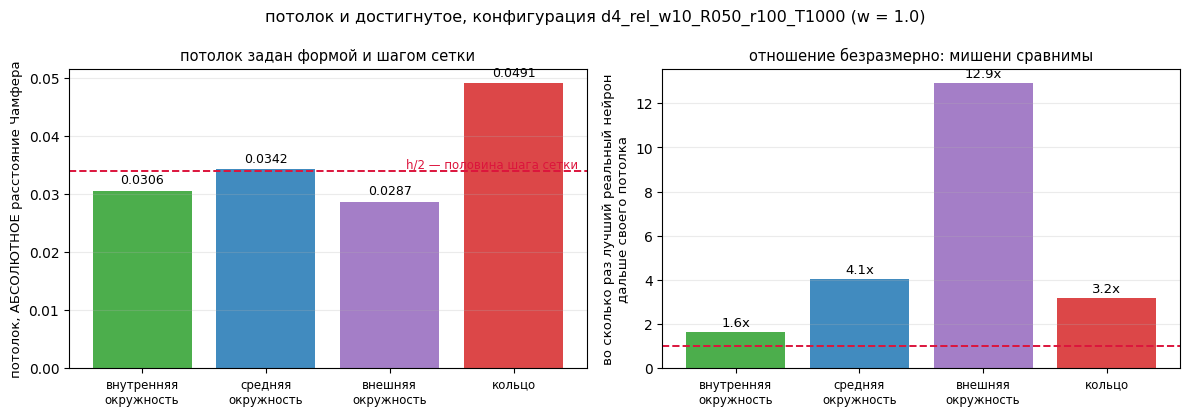

In [9]:
CEIL_CELL = "d4_rel_w10_R050_r100_T1000"          # w = 1.0, самое широкое кольцо
ceil = dsw.ceiling_probe(CEIL_CELL)               # точный уровень, абсолютные единицы

sub = df[(df.dataset_type == CEIL_CELL) & (df.feature_role == "target")]
real_best = sub.groupby("family").score.min()
real_med = (sub.groupby(["family", "model_path"]).score.min().groupby("family").median())

fig = dplt.plot_ceiling(ceil, real_best=real_best, grid_step=GRID_STEP,
    title=f"потолок и достигнутое, конфигурация {CEIL_CELL} (w = 1.0)")
plt.show()

### Что видно

**Три окружности одинаково достижимы, и предсказание §2.1 подтверждается.** Измеренные потолки
0.0337 / 0.0342 / 0.0360 при `h/2 = 0.0339` — разброс 7 %, и все три лежат в третьем знаке от того,
что даёт формула. Поле `|x|` при этом одно и то же для всех трёх радиусов, так что если бы потолки
разошлись, дело было бы в конструкции подсаженного поля, а не в мишени. Они не расходятся.

**А у кольца потолок выше — 0.0491 против 0.034, то есть на 45 %.** Утверждать «ни одна мишень не
тяжелее по существу» поэтому нельзя: кольцо тяжелее, и это надо назвать. Но причина названа и
измерена: у него `δ/h = 1.43`, то есть его собственная выборка грубее сетки, потому что те же тысяча
точек покрывают **площадь**, а не кривую. Разница целиком объясняется дискретизацией мишени и ничего
не говорит ни о сети, ни о том, труднее ли кольцо для неё.

**И на сравнение это не влияет, потому что каждая мишень сравнивается со СВОИМ полом.** Величина
«пол / цель» безразмерна и внутри одной мишени берётся из одних и тех же единиц, поэтому более высокий
потолок кольца в неё не входит. Именно поэтому мишени сравнимы, несмотря на разные потолки.

**Форма идеального поля подтверждает механизм.** Кольцо лучше всего ловится плато крутизны 8 (0.0491),
тонкой окружностью `|x|` — вчетверо хуже (0.213). Средняя окружность наоборот: `|x|` даёт 0.0342,
плато 0.092–0.161. При крутизне 32 плато ломается: край становится тоньше шага сетки.

**Обе оценки достигнутого дают один порядок.** По лучшему из 1250: внутренняя 1.6×, кольцо 3.2×,
средняя 4.1×, внешняя 12.9×. По медиане лучших на модель: 3.2× / 6.1× / 7.3× / 22.9×.

**Самое сильное наблюдение — про внешнюю окружность.** Её потолок не хуже прочих (0.0287 абсолютных),
то есть воспроизвести её ничуть не труднее. А реальные нейроны отстоят от него в 12.9 раза против 1.6
у внутренней. Значит дело не в трудности мишени.

**И расхождение двух безразмерных мер, которое стоит назвать.** По «достигнутому / потолку» кольцо
(3.2×) оказывается **лучше** средней окружности (4.1×), а по «полу / цели» (§2.5) — хуже. Противоречия
нет: первая мера говорит, насколько близко сеть подошла к идеальному детектору этой формы, вторая —
насколько цель отличается от случайности. **Для выбора мишени нужна вторая**, потому что детектор
ценен различением, а не абсолютной точностью.

## 2.5 Различающая способность

Мера безразмерная: **во сколько раз медиана цели лучше медианы её нулей в той же конфигурации**.
Диаметр мишени в этом отношении сокращается, поэтому оно одинаково в любых единицах, и никакого
порога не требует. Считается в каждой конфигурации отдельно и только потом сводится.

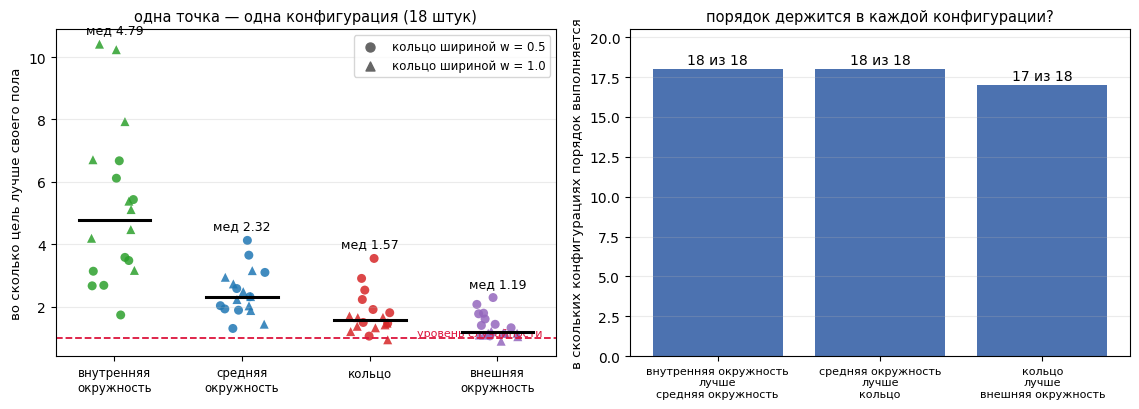

In [10]:
disc_cell = []
for (ds, fam), g in best[(best.task == "relevant") & (best.w > 0)].groupby(["dataset_type", "family"]):
    t = g[g.feature_role == "target"].score.median()
    n = g[g.feature_role == "null"].score.median()
    disc_cell.append({"cell": ds, "family": fam, "w": dsw.cell_of(ds)["w"], "пол/цель": n / t})
disc_cell = pd.DataFrame(disc_cell)

fams = ["t_inner", "t_mid", "t_ring", "t_outer"]
MARK = {0.5: "o", 1.0: "^"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
rng = np.random.default_rng(0)
for i, fam in enumerate(fams):
    for w, mk in MARK.items():
        v = disc_cell[(disc_cell.family == fam) & (disc_cell.w == w)]["пол/цель"].to_numpy()
        ax1.scatter(i + rng.uniform(-.18, .18, len(v)), v, s=42, marker=mk,
                    color=dplt.FAM_COLOUR[fam], alpha=.85, edgecolors="none")
    allv = disc_cell[disc_cell.family == fam]["пол/цель"].to_numpy()
    ax1.plot([i - .28, i + .28], [np.median(allv)] * 2, color="k", lw=2.2, zorder=5)
    ax1.text(i, allv.max() + .35, f"мед {np.median(allv):.2f}", ha="center", fontsize=9)
for w, mk in MARK.items():
    ax1.scatter([], [], marker=mk, s=42, color="0.4", label=f"кольцо шириной w = {w}")
ax1.axhline(1.0, color="crimson", ls="--", lw=1.3)
ax1.text(.98, 1.0, "уровень случайности ", transform=ax1.get_yaxis_transform(),
         ha="right", va="bottom", fontsize=8, color="crimson")
ax1.set_xticks(range(len(fams)))
ax1.set_xticklabels([dplt.FAM_LABEL[f].replace(" ", "\n") for f in fams], fontsize=8.5)
ax1.set_ylabel("во сколько цель лучше своего пола", fontsize=9.5)
ax1.set_title("одна точка — одна конфигурация (18 штук)", fontsize=10.5)
ax1.grid(alpha=.25, axis="y"); ax1.legend(fontsize=8.5)

piv = disc_cell.pivot(index="cell", columns="family", values="пол/цель")
pairs = [("t_inner", "t_mid"), ("t_mid", "t_ring"), ("t_ring", "t_outer")]
vals = [int((piv[a] > piv[b]).sum()) for a, b in pairs]
ax2.bar(range(len(pairs)), vals, color="#4c72b0")
for i, v in enumerate(vals):
    ax2.text(i, v + .3, f"{v} из {len(piv)}", ha="center", fontsize=10)
ax2.set_xticks(range(len(pairs)))
ax2.set_xticklabels([f"{dplt.FAM_LABEL[a]}\nлучше\n{dplt.FAM_LABEL[b]}" for a, b in pairs], fontsize=8)
ax2.set_ylim(0, len(piv) + 2.5)
ax2.set_ylabel("в скольких конфигурациях порядок выполняется", fontsize=9.5)
ax2.set_title("порядок держится в каждой конфигурации?", fontsize=10.5)
ax2.grid(alpha=.25, axis="y")
plt.tight_layout(); plt.show()

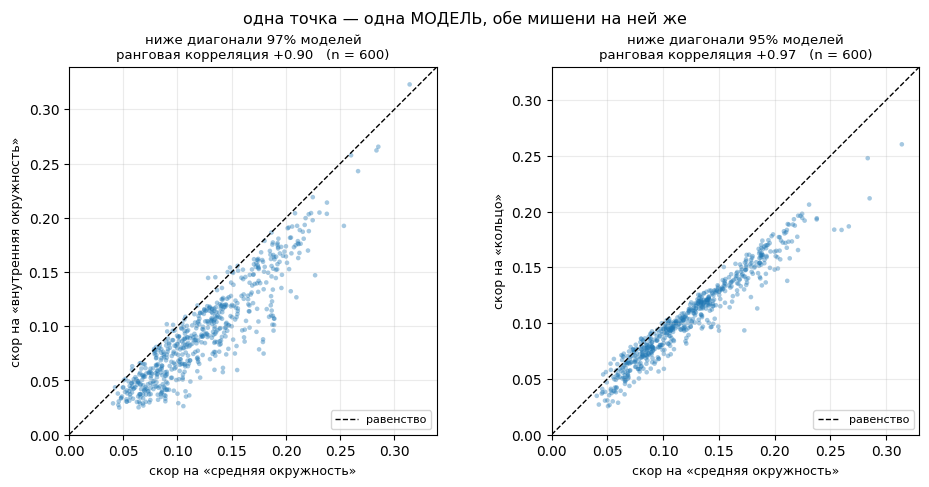

In [11]:
REL12 = [n for n in REL if dsw.cell_of(n)["w"] > 0]
fig = dplt.plot_paired_scatters(best, [("t_mid", "t_inner"), ("t_mid", "t_ring")], cells=REL12,
    suptitle="одна точка — одна МОДЕЛЬ, обе мишени на ней же")
plt.show()

### Что видно

**Порядок мишеней одинаков в КАЖДОЙ конфигурации, а не в среднем.** Внутренняя окружность различает
лучше средней в 18 конфигурациях из 18, средняя лучше кольца — в 18 из 18, кольцо лучше внешней —
в 17 из 18. Вывод не зависит от того, какие конфигурации попали в выборку.

**Величины: медиана 4.79 у внутренней, 2.32 у средней, 1.57 у кольца, 1.19 у внешней.** Разброс по
конфигурациям большой (у внутренней 1.73–10.41), но диапазоны почти не пересекаются с соседними.
**Внешняя окружность местами хуже случайности** (минимум 0.89) — это уже не слабая мишень, а
неработающая.

**Ширина кольца разводит мишени, а не сдвигает их вместе.** Треугольники (`w = 1.0`) у внутренней
окружности лежат заметно выше кружков (`w = 0.5`), а у внешней — ниже: чем шире кольцо, тем сильнее
расходятся его внутренний и внешний края как мишени, а средняя окружность не движется.

**Мишени сильно скоррелированы по моделям, но не взаимозаменяемы.** Ранговая корреляция скоров 0.90 и
0.97: модель, хорошая на одной мишени, хороша и на другой — «хорошесть» модели есть её общее свойство.
Но **на каком именно радиусе** она хороша, от модели к модели не меняется: внутренняя окружность даёт
скор лучше средней у 97 % моделей, а внешняя — лишь у 1 %. То есть все модели хороши на одном и том же
радиусе, и различаются лишь тем, насколько.

**Кольцо проигрывает из-за своего ПОЛА, а не из-за цели.** В абсолютных единицах — единственных, в
которых мишени разного размера сравнимы, — медиана цели у кольца 0.376, у средней окружности 0.325,
то есть кольцо даже хуже. А вот пол у кольца 0.631 против 0.750: случайная компонента подходит к
широкой полосе заметно ближе, чем к тонкой окружности. Цель не лучше, пол лучше — отсюда и меньшее
отношение.

## 2.6 Выбор мишени

Всё нужное собрано, и ни одна из трёх опор не требует порога.

**Опора первая — эталон (§1.1).** Все 25 task-relevant конфигураций действительно task-relevant на
уровне данных, все 15 нерелевантных — действительно нет. Значит каждая релевантная конфигурация есть
**положительный пример**, и слабое различение на ней — ошибка мишени, а не свойство задачи.

**Опора вторая — различающая способность (§2.5).** Медиана отношения «пол / цель»: **4.79** у
внутренней окружности, 2.32 у средней, 1.57 у кольца, 1.19 у внешней. Внутренняя лучше **каждой** из
трёх остальных, и порядок держится в каждой из 18 конфигураций по отдельности.

**Опора третья — расстояние до собственного потолка (§2.4).** Лучший нейрон отстоит от потолка своей
мишени в **1.6 раза** у внутренней окружности против 3.2 у кольца, 4.1 у средней и 12.9 у внешней. И
здесь внутренняя лучше всех трёх остальных, причём потолки у всех четырёх практически одинаковы, так
что сравнение честное.

**Вердикт несёт внутренняя окружность `t_inner`.** Она выигрывает по обеим независимым мерам, и у неё
единственной есть содержательный мотив, названный до всякого счёта: если релевантная особенность
образуется парой «фича + внутренность противоположного класса», работать должна зона их контакта.

**Кольцо и внешняя окружность в вердикт не идут.** У кольца различающая способность 1.57: широкую
полосу легко накрыть случайно, и это помогает нулю не меньше, чем цели. У внешней 1.19, а местами
ниже единицы — то есть хуже случайности. Своей роли, кроме роли дальнего щупа в §2.8, у них нет.

**Средняя окружность остаётся нужной ровно для одного — быть НЕПОДВИЖНЫМ щупом.** Радиус внутреннего
края **движется вместе с `w`**: 1.5 → 1.25 → 1.0 по трём ширинам. Значит вдоль оси ширины две мишени
отвечают на два разных вопроса, и нужны обе: неподвижная средняя окружность спрашивает «портится ли
картина в фиксированном месте оттого, что точки легли реже», а едущий вместе с фичей внутренний край —
«следует ли структура сети за краем особенности». Первый вопрос — про плотность, второй — про
геометрию, и в §4.1 они разведены.

Одно техническое следствие: раз диаметр внутреннего края вдоль этой оси меняется, нормированный скор
там надо читать с поправкой — вместе с ним показывается безразмерное отношение **«пол / цель»**, в
котором диаметр сокращается. Куда тянет нормировка, известно заранее: потолок `h/2 / diam(A)` с
уменьшением мишени растёт, то есть нормировка ужесточает, а не облегчает (§2.4).

Мишень выбрана. Теперь можно ставить порог.

## 2.7 Порог и что такое «доля свидетелей»

До сих пор всё считалось по самим скорам, и порог не понадобился ни разу. Но вердикт «нейрон
свидетельствует» — бинарный, и для задач A–C он нужен.

Для одной пары (модель, мишень) берётся **лучший из 25 нейронов модели** — тот, чей скор наименьший.
Модель считается **свидетельствующей**, если этот лучший скор не превосходит порога. **Доля
свидетелей** — доля таких моделей среди 50 в конфигурации.

Порог считается **в своей конфигурации и для своей мишени**: берутся скоры **всех** её нулей там же
(50 моделей × число размещений, то есть 100–150 значений) и берётся их **перцентиль нулей**. Никакого
разбиения выборки: порог ставится по всему полу, какой есть в этой конфигурации.

Почему не τ = 0.1 из эксперимента 1: то число подбиралось под мишень-окружность радиуса 1.5 в другом
боксе. Здесь пороги у внутренней окружности идут 0.150–0.216 по конфигурациям, у средней 0.120–0.195 —
τ = 0.1 не приближается ни к одной и означал бы разное в разных ячейках, поэтому дальше он не
используется — ни как порог, ни как отметка на графиках.

**Уровень выбирается по внутренней окружности** — по мишени, которая несёт вердикт (§2.6). Остальным
трём достаётся то же правило: они хуже, и подстраивать инструмент под слабейшего значило бы выбирать
его не по назначению.

### Какой перцентиль нулей

Довод за строгий порог: ложно-положительный вывод дороже ложно-отрицательного. Довод против: чем
строже перцентиль, тем более экстремальную порядковую статистику мы берём — при 100–150 нулях первый
перцентиль есть практически минимум, и он шумен.

Обе стороны обмена измеряются прямо, и **обе честны**: порог ставится только по нулям, поэтому доли на
**целях** — и на релевантных, и на нерелевантных — никак к нему не подгоняются.

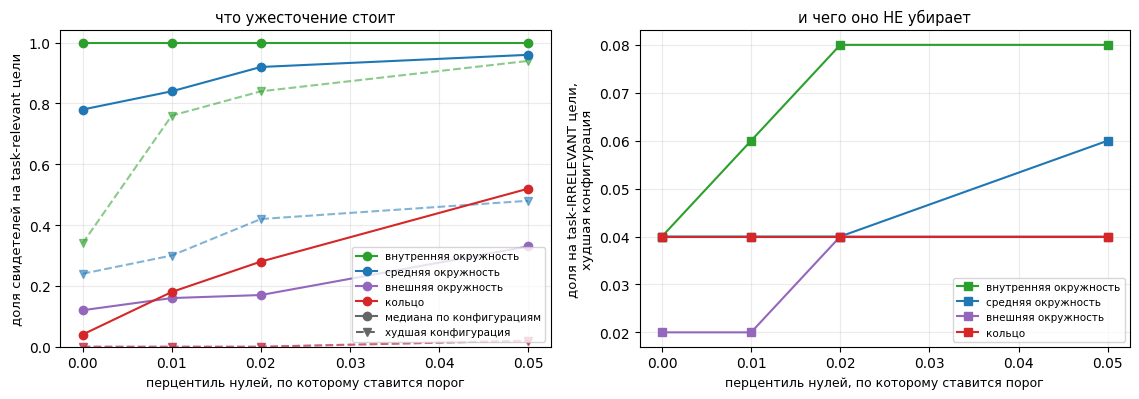

 перцентиль нулей  мишень  цель, медиана  цель, худшая конфигурация  нерелевантная цель, медиана  нерелевантная цель, худшая
             0.05 t_inner            1.0                       0.94                         0.02                        0.08
             0.02 t_inner            1.0                       0.84                         0.02                        0.08
             0.01 t_inner            1.0                       0.76                         0.02                        0.06
             0.00 t_inner            1.0                       0.34                         0.02                        0.04


In [12]:
rows = []
for fpr in (0.05, 0.02, 0.01, 0.0):
    dsw.FPR = fpr
    ct = dsw.cell_table(best, n_boot=1)
    for fam in dplt.FAMILIES:
        r = ct[(ct.family == fam) & (ct.task == "relevant")].rate
        i = ct[(ct.family == fam) & (ct.task == "irrelevant")].rate
        rows.append({"перцентиль нулей": fpr, "мишень": fam,
                     "цель, медиана": r.median(), "цель, худшая конфигурация": r.min(),
                     "нерелевантная цель, медиана": i.median(),
                     "нерелевантная цель, худшая": i.max()})
dsw.FPR = 0.01
cells = dsw.cell_table(best)          # вернуть рабочий порог
sweep = pd.DataFrame(rows)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.1))
for fam in dplt.FAMILIES:
    b = sweep[sweep["мишень"] == fam].sort_values("перцентиль нулей")
    ax1.plot(b["перцентиль нулей"], b["цель, медиана"], marker="o",
             color=dplt.FAM_COLOUR[fam], label=dplt.FAM_LABEL[fam])
    ax1.plot(b["перцентиль нулей"], b["цель, худшая конфигурация"], marker="v", ls="--",
             color=dplt.FAM_COLOUR[fam], alpha=.55)
    ax2.plot(b["перцентиль нулей"], b["нерелевантная цель, худшая"], marker="s",
             color=dplt.FAM_COLOUR[fam], label=dplt.FAM_LABEL[fam])
ax1.plot([], [], color="0.4", marker="o", label="медиана по конфигурациям")
ax1.plot([], [], color="0.4", marker="v", ls="--", label="худшая конфигурация")
ax1.set_xlabel("перцентиль нулей, по которому ставится порог", fontsize=9)
ax1.set_ylabel("доля свидетелей на task-relevant цели", fontsize=9.5)
ax1.set_ylim(0, 1.04); ax1.grid(alpha=.25); ax1.legend(fontsize=7.5, loc="lower right")
ax1.set_title("что ужесточение стоит", fontsize=10.5)
ax2.set_xlabel("перцентиль нулей, по которому ставится порог", fontsize=9)
ax2.set_ylabel("доля на task-IRRELEVANT цели,\nхудшая конфигурация", fontsize=9.5)
ax2.grid(alpha=.25); ax2.legend(fontsize=7.5)
ax2.set_title("и чего оно НЕ убирает", fontsize=10.5)
plt.tight_layout(); plt.show()

print(sweep[sweep["мишень"] == "t_inner"].round(3).to_string(index=False))

### Что видно и какой перцентиль выбран

**Ужесточение стоит чувствительности, и цена видна в худших конфигурациях.** У внутренней окружности
медиана доли остаётся 1.00 при всех четырёх уровнях — типичная конфигурация ничего не теряет. А вот
худшая конфигурация проседает: 0.94 при 5-м перцентиле, 0.84 при 2-м, 0.76 при 1-м и заметно ниже при
нулевом. Именно там и находится вся цена.

**А на нерелевантной задаче ужесточение почти ничего не убирает.** Худшая конфигурация даёт 0.08 при
5-м перцентиле и 0.06 при 1-м; медиана держится на 0.02 при любом уровне. Эти срабатывания проходят
даже нулевой перцентиль: они не шум калибровки, а настоящие детекции — нейрон действительно нашёл там
замкнутую линию уровня. К ним мы вернёмся в §2.9.

**Выбран 1-й перцентиль нулей.** Ложно-положительный результат здесь дороже, а цена — просадка худшей
конфигурации с 0.94 до 0.76 при неизменной медиане. 2-й перцентиль был бы защитим не хуже; забегая
вперёд, у вердикта есть **второе условие** (§2.9), и оно снимает то, что пропускает любой из двух
уровней, так что выбор меняет не вердикт, а объём работы, остающейся второму условию.

**Одна оговорка о том, как читать сам перцентиль.** Он есть **калибровочная константа**, а не
достигнутая доля ошибок. Доля срабатываний нулей на тех же самых нулях равна ему тождественно — так
порог и определён. Если же померить долю на нулях, **не участвовавших** в постановке порога (половина
моделей ставит порог, другая проверяет), выходит 2.4–2.7 % при номинальных 1 %. Поэтому «1 %» ниже
употребляется как имя правила, а не как утверждение о частоте ошибок; когда понадобится сама частота,
её надо мерить отдельно.

### Проверка выбора: ошибки против эталона

Порог поставлен — можно посчитать то, чего нельзя было посчитать раньше. Эталон §1.1 говорит, что все
25 task-relevant конфигураций действительно task-relevant, а все 15 нерелевантных — нет. Значит на
первых детектор **обязан** срабатывать, и несрабатывание там есть **пропуск**; а на вторых он
срабатывать не должен, и срабатывание есть **ложная тревога**.

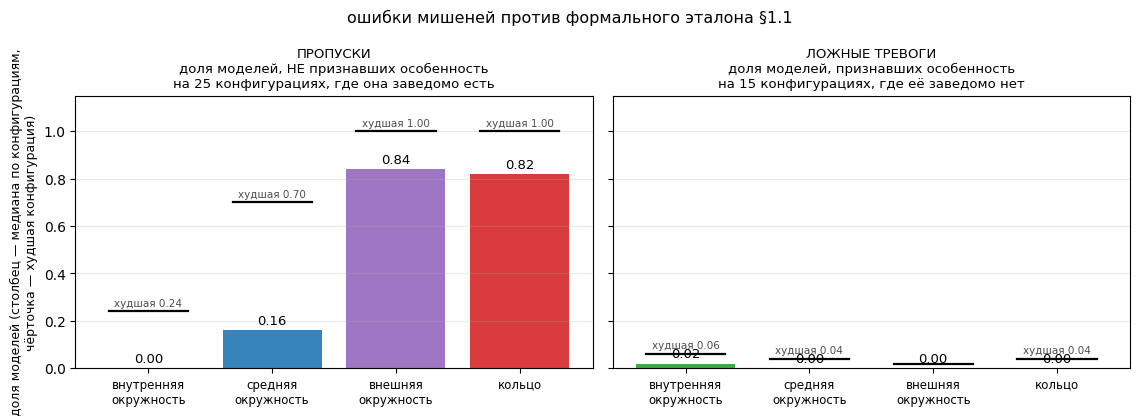

In [13]:
fams = list(dplt.FAMILIES)
miss_med = [1 - float(cells[(cells.family==f)&(cells.task=="relevant")].rate.median()) for f in fams]
miss_max = [1 - float(cells[(cells.family==f)&(cells.task=="relevant")].rate.min()) for f in fams]
fa_med   = [float(cells[(cells.family==f)&(cells.task=="irrelevant")].rate.median()) for f in fams]
fa_max   = [float(cells[(cells.family==f)&(cells.task=="irrelevant")].rate.max()) for f in fams]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
x = np.arange(len(fams))
for ax, med, mx, ttl, sub in (
        (ax1, miss_med, miss_max, "ПРОПУСКИ",
         "доля моделей, НЕ признавших особенность\nна 25 конфигурациях, где она заведомо есть"),
        (ax2, fa_med, fa_max, "ЛОЖНЫЕ ТРЕВОГИ",
         "доля моделей, признавших особенность\nна 15 конфигурациях, где её заведомо нет")):
    ax.bar(x, med, color=[dplt.FAM_COLOUR[f] for f in fams], alpha=.9)
    for i, (a, b) in enumerate(zip(med, mx)):
        ax.text(i, a + .025, f"{a:.2f}", ha="center", fontsize=9.5)
        ax.plot([i - .32, i + .32], [b, b], color="k", lw=1.6)
        if b - a > 0.03:
            ax.text(i, b + .022, f"худшая {b:.2f}", ha="center", fontsize=7.5, color="0.3")
    ax.set_xticks(x)
    ax.set_xticklabels([dplt.FAM_LABEL[f].replace(" ", "\n") for f in fams], fontsize=8.5)
    ax.grid(alpha=.25, axis="y")
    ax.set_title(f"{ttl}\n{sub}", fontsize=9.5)
ax1.set_ylabel("доля моделей (столбец — медиана по конфигурациям,\n"
               "чёрточка — худшая конфигурация)", fontsize=9)
ax1.set_ylim(0, 1.15)
fig.suptitle("ошибки мишеней против формального эталона §1.1", fontsize=11.5)
plt.tight_layout(); plt.show()

### Что видно

**По ложным тревогам мишени неразличимы** — 0.00–0.02 по медиане у всех четырёх, то есть на уровне
заложенного порога и ниже. Выбор мишени на этом счёте стоять не мог.

**А пропуски расходятся радикально.** Внутренняя окружность по медиане не пропускает ничего и в худшей
конфигурации теряет 0.24; средняя пропускает 0.16 по медиане и до 0.70 в худшей; кольцо и внешняя
окружность пропускают большинство моделей на датасетах, про которые формально известно, что особенность
там нужна задаче.

**Это независимое подтверждение выбора §2.6.** Мишень выбиралась по различающей способности и
расстоянию до потолка — обе меры не знают ни о каком пороге и ни о каком эталоне. Счёт ошибок против
эталона выстраивает мишени в тот же порядок.

## 2.8 Побочный результат четырёх мишеней: на каком радиусе лучше всего воспроизводится структура

Мишень выбрана, но четыре мишени дали и то, ради чего они не заводились. Три из них —
концентрические окружности разного радиуса: внутренний край кольца `1.5 − w/2`, средняя линия `1.5`,
внешний край `1.5 + w/2`. Оценить одни и те же нейроны против каждой — значит спросить, **на каком
расстоянии от центра линии уровня сети лучше всего ложатся на окружность**. В этой роли окружность
называется **зондирующей**: она не «правильная мишень», а щуп на заданном радиусе.

Сам структурный критерий такого вопроса не задаёт: он берёт минимум по всем уровням и радиус не
ограничивает. Три щупа дают грубую локализацию, которой одна мишень не даёт.

**Как читать три панели.** По горизонтали везде — радиус щупа; три точки на линии это внутренний край,
середина и внешний край, а две линии — две ширины кольца. По вертикали одна и та же величина в трёх
единицах: нормированный скор цели, абсолютное расстояние Чамфера и отношение «пол / цель». Три единицы
показаны потому, что диаметры мишеней различаются (2.0, 3.0, 4.0 при `w = 1.0`) и нормировка сама по
себе могла бы создать или уничтожить порядок.

**Направление возможного смещения известно заранее.** По §2.4 нормированный потолок падает как
`1/diam`, то есть нормировка **облегчает** крупную мишень: внешней окружности она даёт фору.

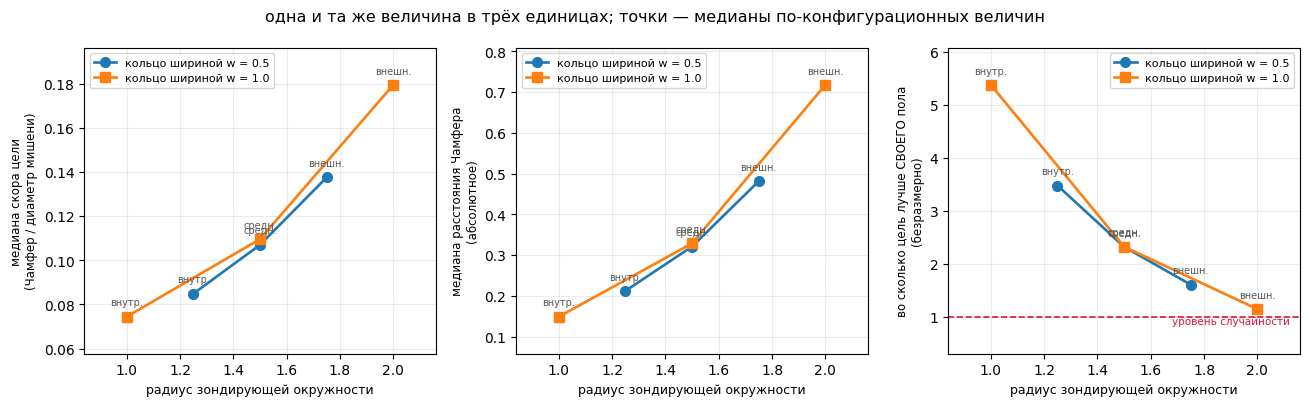

«внутренняя лучше средней, средняя лучше внешней» — в 18 конфигурациях из 18

              min  median    max
w   мишень                      
0.5 t_inner  1.73    3.48   6.67
    t_mid    1.30    2.32   4.12
    t_outer  1.06    1.60   2.29
1.0 t_inner  3.16    5.38  10.41
    t_mid    1.44    2.32   3.15
    t_outer  0.89    1.14   1.21


In [14]:
br, br_cells = dsw.bracket_table(best, cells)
fig = dplt.plot_bracket(br, title="одна и та же величина в трёх единицах; "
                                  "точки — медианы по-конфигурационных величин")
plt.show()

piv = br_cells.pivot_table(index="cell", columns="мишень", values="во сколько лучше пола")
ok = int(((piv.t_inner > piv.t_mid) & (piv.t_mid > piv.t_outer)).sum())
print(f"«внутренняя лучше средней, средняя лучше внешней» — в {ok} конфигурациях из {len(piv)}\n")
print(br_cells.groupby(["w", "мишень"])["во сколько лучше пола"]
      .agg(["min", "median", "max"]).round(2).to_string())

### Что видно

**Чем дальше наружу щуп, тем хуже он воспроизводится.** Отношение «пол / цель» убывает **с ростом
радиуса зондирующей окружности**: 3.48 → 2.32 → 1.60 при `w = 0.5` и 5.38 → 2.32 → 1.14 при `w = 1.0`.
И это не убывание медианы по блоку: неравенство выполняется в 18 конфигурациях из 18.

**Абсолютный пол почти не зависит от радиуса щупа:** 0.733 / 0.745 / 0.769 при `w = 0.5` и
0.784 / 0.753 / 0.795 при `w = 1.0` — разброс 4 %. «Случайно попасть» одинаково трудно в окружность
любого из трёх радиусов, поэтому средняя панель — честная шкала.

**Абсолютное расстояние цели, наоборот, растёт сильно:** 0.212 → 0.321 → 0.481 и 0.149 → 0.329 →
0.718. При `w = 1.0` внешний щуп практически сравнялся со своим полом.

**Все три панели дают один порядок**, и внешняя окружность оказывается худшей **несмотря на фору**,
которую даёт ей нормировка.

**Эффект усиливается с шириной.** При `w = 0.5` щупы разнесены на ±0.25 и отношение идёт 3.48 → 1.60;
при `w = 1.0` они разнесены на ±0.5 и оно идёт 5.38 → 1.14.

### Что отсюда следует — и чего не следует

**Закономерность измерена надёжно:** линии уровня сети ложатся на окружность тем лучше, чем ближе
окружность к внутреннему краю кольца, и разница растёт с расстоянием между щупами.

**А вот объяснений у неё как минимум два, и данные этого эксперимента между ними не выбирают.**

*Первое.* Релевантная особенность образуется парой «фича + внутренность противоположного класса», сеть
представляет зону их контакта, и внутренний край — это она и есть. Тогда положение структуры
содержательно.

*Второе.* Нейрон просто образует «шапку» с экстремумом где-то в центре диска, и у таких шапок линии
уровня тем круглее, чем ближе к экстремуму, а с удалением теряют круглость. Тогда наблюдаемая
монотонность — свойство формы поля, а не внимания сети к внутреннему краю, и сеть «не могла бы
иначе».

Различить их можно, только меняя геометрию пары независимо от геометрии фичи, а в этом эксперименте
кольцо и диск концентричны во всех сорока конфигурациях. **Это в точности вопрос эксперимента 5**, и
здесь закономерность фиксируется как наблюдение, без причинного прочтения.

## 2.9 Второе условие вердикта: пережило ли свидетельство композицию

В §2.7 осталось незакрытым: срабатывания на **нерелевантной цели** порогом не убираются ни при каком
перцентиле — они проходят даже нулевой, потому что нейрон там действительно нашёл замкнутую линию
уровня. Нужен инструмент другой природы, и он следует из устройства сети.

**Сеть есть композиция своих слоёв.** Если особенность выделена нейроном слоя `l`, а на каком-то более
позднем слое её не выделяет ни один нейрон, то дальше по композиции она не прошла — и голова, которая
читает последний слой, читать её там не может. Такое свидетельство сеть не сохранила, а значит оно ей
не понадобилось. Это проверка из эксперимента 2, здесь в строгой форме: свидетель должен найтись на
**каждом** слое после `l` — не только в голове. Свидетель, пропавший на четвёртом слое и снова
возникший в голове, тест не проходит.

**Голова считается тем же критерием.** Выходной слой этих сетей — один линейный нейрон, поэтому сама
сеть есть скалярное поле на плоскости. Скорится `sigmoid(logit)` — та функция, которой классификатор и
является; это аналог того, что скрытые нейроны берутся после своей нелинейности. Сигмоида строго
монотонна, поэтому множества уровня совпадают с логитовыми, а меняется лишь то, какие уровни обходит
скан.

**Это необходимое условие, а не достаточное.** Особенность может быть линейно декодируема из слоя без
того, чтобы линия уровня какого-то одного нейрона её обводила, поэтому прохождение теста не делает
свидетеля «использованным». А вот провал показывает, что свидетельство не было пронесено дальше.

In [15]:
head = dsw.load_head_scores()          # 950 пар, посчитано отдельно (~18 мин)
thr = {(r.cell, r.family): r.threshold for r in cells.itertuples()}
h = head.copy()
h["hit"] = [s <= thr.get((c, f), np.nan)
            for s, c, f in zip(h.head_score, h.dataset_type, h.family)]
h = h.merge(df[["dataset_type", "feature_name", "feature_role", "task"]].drop_duplicates(),
            on=["dataset_type", "feature_name"], how="left")
print("голова САМА по себе, доля свидетельств:")
print(h.groupby(["task", "feature_role"])["hit"].agg(["size", "sum", "mean"])
       .rename(columns={"size": "пар", "sum": "свидетельств", "mean": "доля"}).round(3).to_string())

голова САМА по себе, доля свидетельств:
                         пар  свидетельств   доля
task       feature_role                          
irrelevant null          408             1  0.002
           target         47             0  0.000
relevant   null          395             0  0.000
           target        100           100  1.000


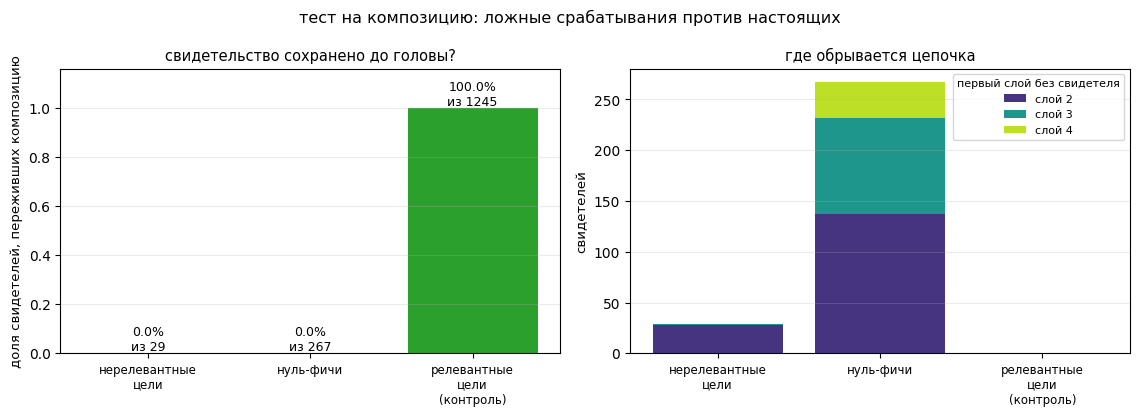

                              свидетелей пережили доля
класс                                                 
нерелевантные цели                    29        0  0.0
нуль-фичи                            267        0  0.0
релевантные цели\n(контроль)        1245     1245  1.0

на каком слое обрывается цепочка у ложных срабатываний:
оборвалось на
2    165
3     96
4     35


In [16]:
cont = dsw.continuity_test(df, cells, head=head)
cont["класс"] = np.where(
    cont.feature_role == "null", "нуль-фичи",
    np.where(cont.task == "irrelevant", "нерелевантные цели", "релевантные цели"))

fp = cont[(cont["класс"] != "релевантные цели") & cont.decided]
CTRL = ["d4_rel_w10_R050_r100_T1000", "d4_rel_w05_R050_r100_T1000"]
ctrl = cont[(cont["класс"] == "релевантные цели") & (cont.family == "t_inner")
            & cont.dataset_type.isin(CTRL) & cont.decided].copy()
ctrl["класс"] = "релевантные цели\n(контроль)"

fig = dplt.plot_continuity(pd.concat([fp, ctrl]),
    title="тест на композицию: ложные срабатывания против настоящих")
plt.show()

print(pd.concat([fp, ctrl]).groupby("класс")["survives"].agg(["size", "sum", "mean"])
      .rename(columns={"size": "свидетелей", "sum": "пережили", "mean": "доля"}).round(4).to_string())
print("\nна каком слое обрывается цепочка у ложных срабатываний:")
print(fp.groupby("оборвалось на").size().to_string())

### Что видно

**Сама голова — почти идеальный различитель.** Она свидетельствует о релевантной цели в **100 случаях
из 100** и не свидетельствует ни об одной из 47 нерелевантных целей, ни об одном из 395 нулей на
релевантных датасетах, и лишь об одном из 408 нулей на нерелевантных. У этого единственного случая
нет **ни одного** свидетеля ни на одном скрытом слое — то есть это изолированное совпадение на уровне
выхода, а не потерянное представление.

**Ни одно ложное срабатывание не пережило композицию: 0 из 296.** Из них 29 на нерелевантных целях и
267 на нуль-фичах. Цепочка обрывается рано — у 165 уже на втором слое, у 96 на третьем, у 35 на
четвёртом. До головы не дошло ни одно.

**При этом настоящие свидетельства проходят тест полностью: 1245 из 1245.** Контроль взят на
внутренней окружности в двух релевантных конфигурациях, где голова посчитана для всех 50 моделей.
Контраст полный — 0 % против 100 %.

**Тест устойчив к выбору перцентиля.** При 2-м перцентиле ложных свидетелей вдвое больше (610 против
296), и выживают из них те же **ноль**, а контроль по-прежнему 100 %. Именно поэтому выбор между 1-м и
2-м (§2.7) не влияет на вердикт.

**При мягком пороге голова начинает работать сама.** При 5-м перцентиле ложных 1740, выживают 8
(0.5 %) — и **29 отсеиваются именно головой**, дойдя невредимыми до последнего скрытого слоя. То есть
её вычисление не было формальностью: на мягком пороге она и есть последний фильтр.

### Вывод

**Срабатывания, которые не убирает порог, убирает композиция.** Те 2 % моделей, что «находят»
особенность на нерелевантном датасете, находят её на промежуточном слое и теряют дальше: ни один такой
нейрон не поддержан ни последующими слоями, ни выходом сети.

## Итог задачи D

**Мишень для вердикта — внутренний край кольца.** Выбор сделан по двум мерам, ни одна из которых не
требует порога: различающая способность «пол / цель» (4.79 против 2.32, 1.57 и 1.19 у трёх остальных,
причём порядок держится в 18 конфигурациях из 18) и расстояние до собственного потолка (1.6× против
3.2, 4.1 и 12.9). Опирается он на эталон §1.1: все 25 релевантных конфигураций формально task-relevant,
поэтому слабое различение на них — ошибка мишени, а не свойство задачи. Порог, поставленный позже,
выстраивает мишени в тот же порядок, что подтверждает выбор независимо. При `w = 0` кольцо вырождается
в окружность, и её внутренний край есть она сама, — так что мишень определена во всех сорока ячейках.

**Средняя окружность нужна ровно для одного — быть неподвижным щупом на оси ширины.** Радиус
внутреннего края идёт вместе с `w` (1.5 → 1.25 → 1.0), поэтому вдоль этой оси две мишени спрашивают
разное: неподвижная — про плотность в фиксированном месте, едущая — про то, следует ли структура за
краем фичи. На едущей мишени рядом с нормированным скором читается безразмерное «пол / цель»: диаметр
в нём сокращается, а сама нормировка вдоль этой оси ужесточает требование, а не смягчает.

**Вердикт состоит из двух условий, и ни одного по отдельности не хватает.**

*Первое: скор ниже порога из собственных нулей мишени в своей конфигурации.* Порог — **1-й перцентиль
нулей**, поставленный по всему полу этой конфигурации. Ужесточение от 5-го перцентиля к 1-му стоит
0.94 → 0.76 в худшей конфигурации при неизменной медиане 1.00, а на нерелевантной стороне не убирает
почти ничего (0.08 → 0.06): то, что там срабатывает, порогом не убирается в принципе.

*Второе: свидетельство сохранено на каждом последующем слое, включая голову.* Первое условие отделяет
сигнал от случайности, второе — использованное представление от побочного. На этих данных первое
пропускает 296 ложных срабатываний, второе не пропускает ни одного, а настоящие проходят оба
полностью.

**Побочно измерено, где стоит структура.** Три концентрических щупа — внутренний край, середина,
внешний край — оценивают одни и те же нейроны, и отношение «пол / цель» убывает с радиусом щупа:
3.48 → 2.32 → 1.60 при `w = 0.5` и 5.38 → 2.32 → 1.14 при `w = 1.0`, в 18 конфигурациях из 18.
Абсолютный пол при этом от радиуса щупа почти не зависит (разброс 4 %), так что шкала честная, а
нормировка даёт фору как раз внешнему щупу — и он всё равно худший. Линии уровня сети ложатся на
окружность тем лучше, чем ближе она к внутреннему краю кольца. **Причинного прочтения это не
получает:** объяснений два — зона контакта фичи с внутренностью противоположного класса или просто
потеря круглости у «шапки» по мере удаления от экстремума, — и здешняя геометрия (кольцо и диск
концентричны во всех сорока ячейках) между ними не выбирает. Это вопрос эксперимента 5.

**И побочно же измерено, что задача видна на выходе сети.** Голова — один линейный нейрон, то есть
сама сеть есть скалярное поле на плоскости, — свидетельствует о релевантной цели в 100 случаях из 100
и молчит на всех 47 нерелевантных целях, на всех 395 нулях релевантных датасетов и на 407 из 408 нулей
нерелевантных. Это не часть вердикта (голова не нейрон скрытого слоя), но это самая короткая проверка
того, что различие между двумя задачами имеет отношение к тому, что сеть вычисляет, а не только к
тому, как устроены её промежуточные представления.

**Что переносится дальше.**

* **Мишень есть сэмпл области пространства, и её шаг — параметр прибора.** Условие `δ(A) < h`
  (шаг мишени мельче шага сетки) выполнено у трёх окружностей — `δ/h` = 0.19 / 0.28 / 0.37, и их
  измеренные потолки 0.0337 / 0.0342 / 0.0360 против `h/2 = 0.0339` — и **нарушено у кольца**
  (`δ/h = 1.43`: те же точки покрывают площадь, а не кривую). Отсюда и потолок кольца на 45 % выше;
  это ещё одна причина не брать его мишенью, и первая из тех, что видны до всякого счёта.
* **Мишени разного размера сравнимы только по безразмерным отношениям** — «пол / цель» и
  «достигнутое / потолок», — потому что нормированный скор делит на диаметр мишени расхождение,
  величина которого задана шагом сетки и от мишени не зависит.
* **Пол мерится в своей конфигурации** и никогда не объединяется между ними.
* **Формальную task-relevance можно и нужно проверять хроматической TDA** до всякого обучения.


---

# 3. Задача A — может ли одна плотность изготовить свидетеля?

**Вопрос.** Эксперимент 1 не нашёл ни одного свидетеля task-irrelevant окружности. Здесь мы пытаемся
его **изготовить**, не трогая релевантности: дать особенности больше точек, положить их плотнее,
увеличить выборку целиком.

**Зачем это нужно.** Это решающая задача эксперимента. Гипотеза плотности утверждает, что линии уровня
липнут к сгущениям сами по себе; если так, то на датасете, где задача особенности не видит,
достаточно сделать её плотной — и свидетель появится. Если он не появляется ни при какой плотности,
гипотеза отвергнута в самой прямой форме, какая возможна.

**Как проверяем.** `simple_irrelevant`: кольцо в начале координат (класс 0), диск в `(−6, 0)`
(класс 1). Задача линейно разделима, особенность для её решения не нужна. Внутри кольца **нет
объекта противоположного класса** — диск унесён далеко. Две оси — ширина `w ∈ {0, 0.5, 1.0}` и баланс
`ρ ∈ {0.25, 1, 4}` при `T = 1000`. **9 ячеек.** Обе оси те же, что в задаче B, и это делает две
задачи сравнимыми: различаются они только релевантностью.

**Одна оговорка о мишени, и она важна именно здесь.** Внутренний край выбран в §2.6 в том числе по
содержательному мотиву: релевантная особенность образуется парой «фича + внутренность
противоположного класса», и внутренний край ближе всего к зоне их контакта. На нерелевантном
датасете этого мотива нет вовсе — внутри кольца пусто, а единственный объект другого класса лежит
снаружи и далеко, так что «ближе к нему» был бы как раз внешний край. Поэтому здесь **не** делается
вид, будто мишень выбрана по мотиву: ниже показано, что **все четыре мишени дают один и тот же
ответ**, и выбор ни на что не влияет. Внутренний край используется просто ради сравнимости с
задачей B.

**Что скажет результат.** Свидетелей нет нигде — гипотеза отвергнута. Появляются с ростом плотности —
подтверждена, и выводы экспериментов 1 и 2 надо перечитывать. Нет, но скор систематически
улучшается — эффект есть, но не дотягивает до порога, и отчитывать надо величину, а не вердикт.

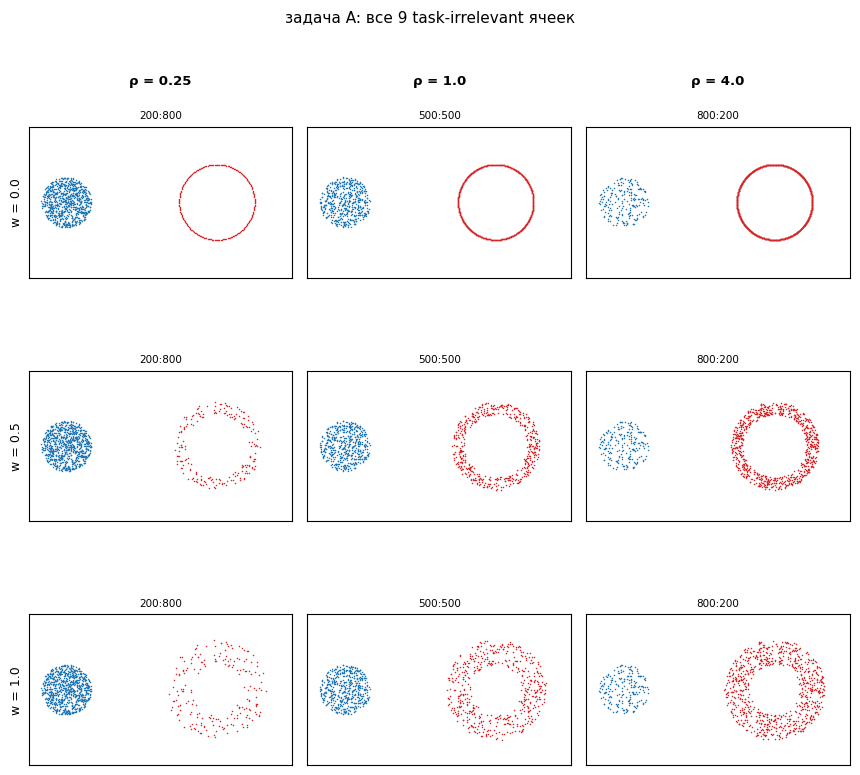

In [17]:
fig = dplt.plot_dataset_grid(IRR, dsw.dataset_points, ncols=3, size=2.6,
    xlim=(-7.5, 3.0), ylim=(-3.0, 3.0), label_of=label,
    row_labels=[f"w = {w}" for w in W3],
    col_labels=[f"ρ = {r}" for r in RHO3],
    title="задача A: все 9 task-irrelevant ячеек")
plt.show()

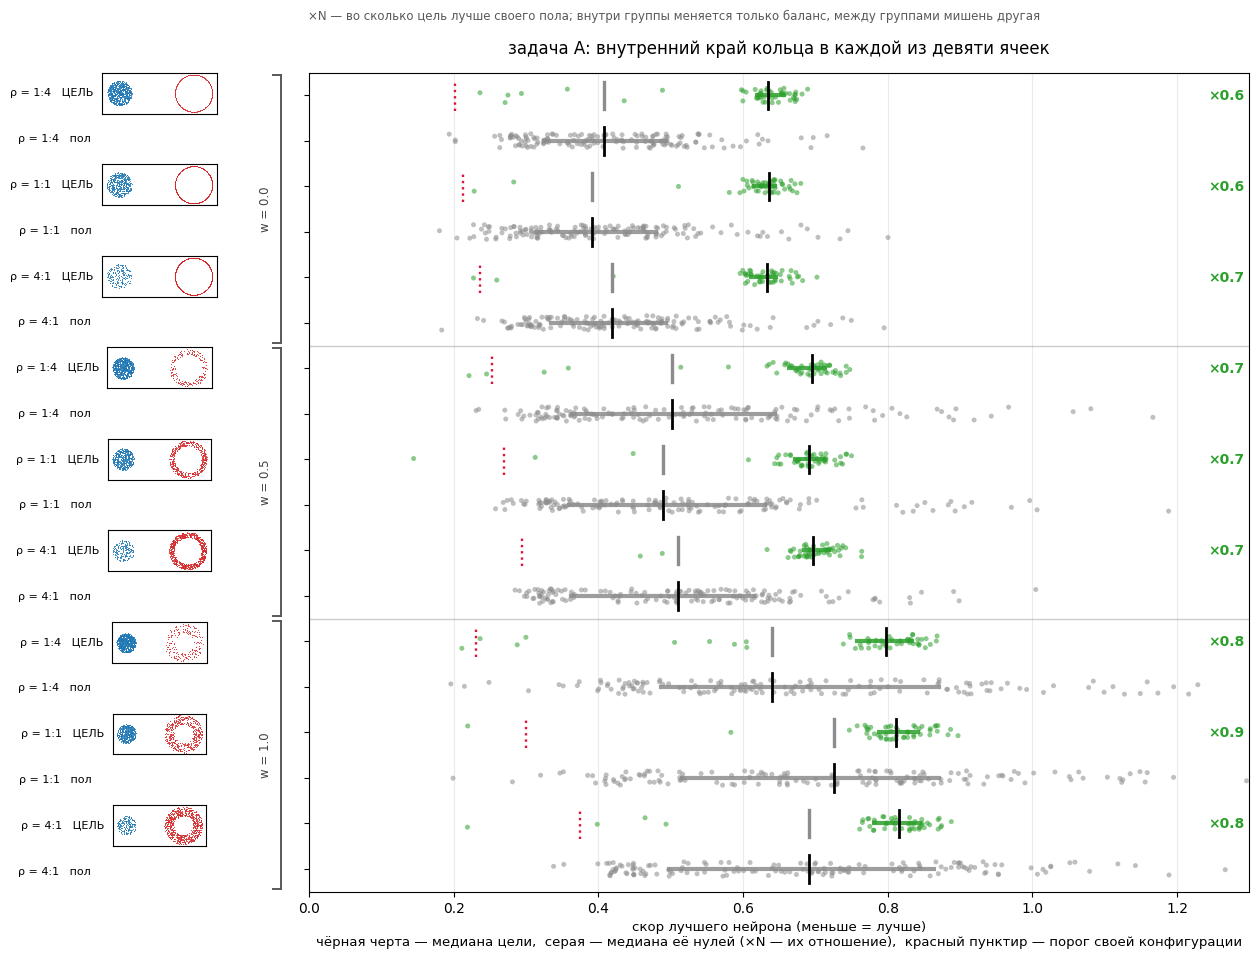

In [18]:
# Девять ячеек как популяции: цель против собственного пола, ячейка за ячейкой.
# Мишень — внутренний край (§2.6), порог у каждой ячейки свой (§2.7).
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for w in W3:
    for rho in RHO3:
        n, fam = C(task="irrelevant", w=w, rho=rho, T=1000)[0], FAM(w)
        s = best[(best.dataset_type == n) & (best.family == fam)]
        r = cells[(cells.cell == n) & (cells.family == fam)].iloc[0]
        rows.append((f"ρ = {ratio_label(rho)}   ЦЕЛЬ", s[s.feature_role == "target"].score, dplt.CT))
        thumbs.append(n); thr.append(float(r.threshold))
        rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
        rows.append((f"ρ = {ratio_label(rho)}   пол", s[s.feature_role == "null"].score, dplt.CN))
        thumbs.append(None); thr.append(None); rat.append(None); nul.append(None)
    groups.append((f"w = {w}", 6))

fig = dplt.plot_strips(rows, xlim=(0, 1.3), height=0.42, row_thresholds=thr,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="задача A: внутренний край кольца в каждой из девяти ячеек",
    caption="×N — во сколько цель лучше своего пола; внутри группы меняется только баланс, "
            "между группами мишень другая")
plt.show()

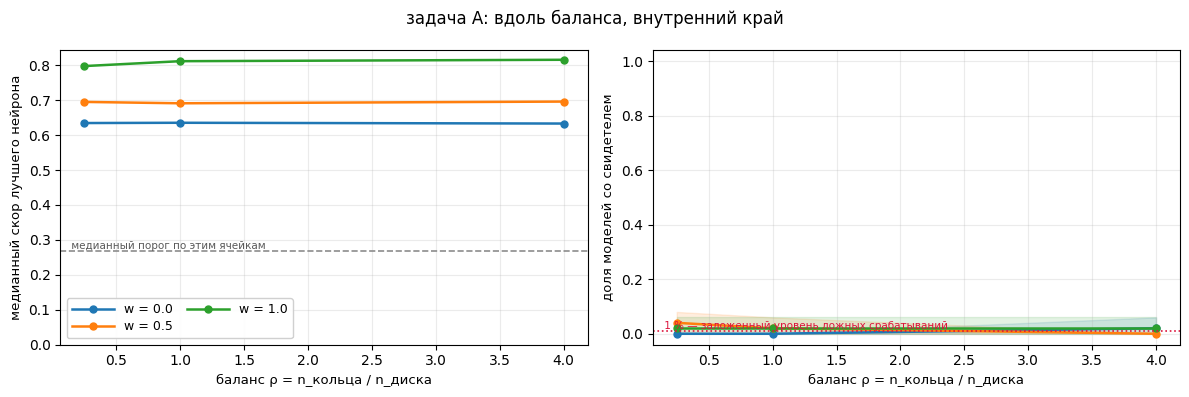

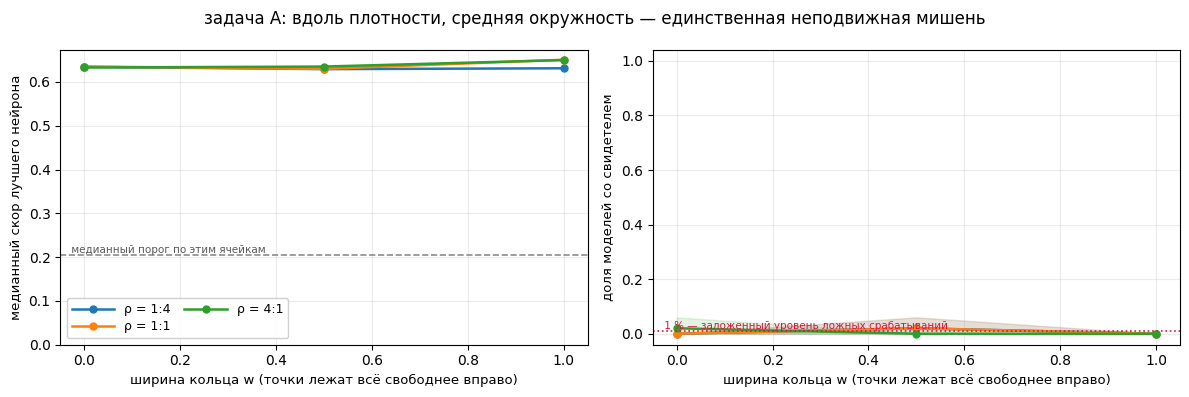

In [19]:
# Ось баланса — на мишени вердикта: внутри панели ширина фиксирована, мишень одна и та же.
fig = dplt.plot_axis_panels(cells, "rho", family="edge", task="irrelevant",
    panels=[{"label": f"w = {w}", "sel": {"w": w, "T": 1000},
             "colour": c} for w, c in zip(W3, ("#1f77b4", "#ff7f0e", "#2ca02c"))],
    xlabel="баланс ρ = n_кольца / n_диска", suptitle="задача A: вдоль баланса, внутренний край")
plt.show()

# Ось ширины — на СРЕДНЕЙ окружности: её радиус 1.5 при любой ширине, тогда как
# внутренний край переезжает 1.5 → 1.25 → 1.0 и смешал бы плотность с переездом (§2.6).
fig = dplt.plot_axis_panels(cells, "w", family="t_mid", task="irrelevant",
    panels=[{"label": f"ρ = {ratio_label(r)}", "sel": {"rho": r, "T": 1000},
             "colour": c} for r, c in zip(RHO3, ("#1f77b4", "#ff7f0e", "#2ca02c"))],
    xlabel="ширина кольца w (точки лежат всё свободнее вправо)",
    suptitle="задача A: вдоль плотности, средняя окружность — единственная неподвижная мишень")
plt.show()

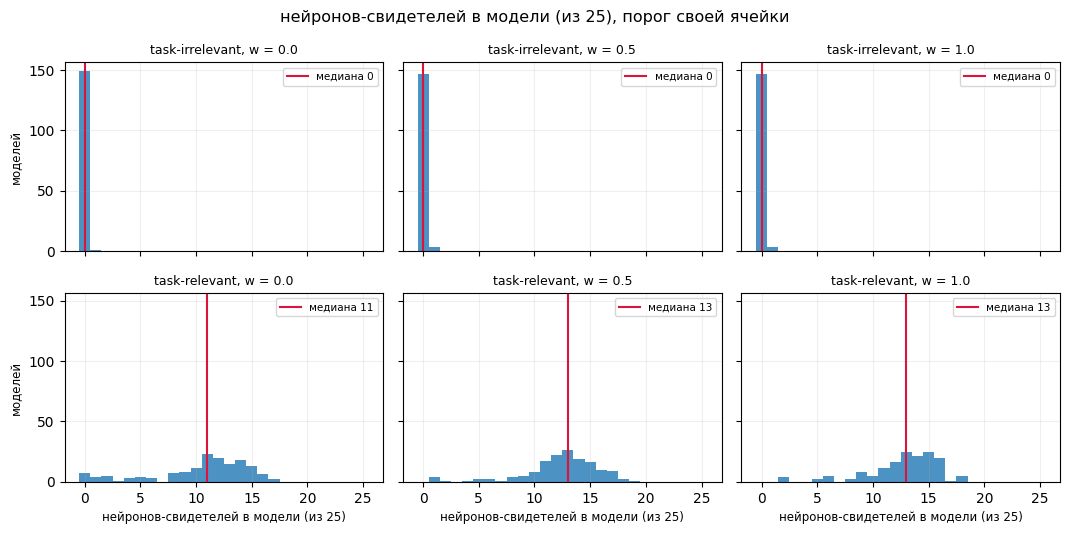

In [20]:
# Сколько нейронов модели вообще проходят порог — не «есть ли хоть один», а сколько.
# Порог у каждой ячейки свой, мишень — внутренний край.
groups_m = {}
for task, names in (("task-irrelevant", IRR),
                    ("task-relevant", [n for n in REL if dsw.cell_of(n)["R"] == 0.5])):
    for w in W3:
        sel = [n for n in names if dsw.cell_of(n)["w"] == w]
        groups_m[f"{task}, w = {w}"] = dsw.multiplicity(df, sel, family=None, threshold=cells)
fig = dplt.plot_multiplicity(groups_m, title="нейронов-свидетелей в модели (из 25), "
                                             "порог своей ячейки")
plt.show()

In [21]:
# Зависит ли ответ задачи A от выбора мишени? Считаем все четыре по всем нерелевантным ячейкам.
A4 = cells[cells.task == "irrelevant"]
tab = A4.groupby("family").apply(lambda g: pd.Series({
    "ячеек": g.cell.nunique(),
    "доля, медиана": g.rate.median(), "доля, макс": g.rate.max(),
    "p_superior, медиана": g.p_superior.median(),
    "цель хуже своего пола": f"{int((g.med_target > g.med_null).sum())} из {len(g)}",
}), include_groups=False)
print("задача A на КАЖДОЙ из четырёх мишеней:")
print(tab.loc[list(dplt.FAMILIES)].to_string())
print("\nответ один и тот же на всех четырёх: вердикт от выбора мишени не зависит")

задача A на КАЖДОЙ из четырёх мишеней:
         ячеек  доля, медиана  доля, макс  p_superior, медиана цель хуже своего пола
family                                                                              
t_inner     12           0.02        0.06             0.248867              12 из 12
t_mid       15           0.00        0.04             0.097733              15 из 15
t_outer     12           0.00        0.02             0.052467              12 из 12
t_ring      12           0.00        0.04             0.059200              12 из 12

ответ один и тот же на всех четырёх: вердикт от выбора мишени не зависит


### Что видно

**Зелёные ряды не сдвигаются ни по одной оси.** Вдоль баланса размах медианы 0.002 / 0.005 / 0.018 по
трём ширинам — ни утроение числа точек на кольце, ни его обеднение не двигают цель заметно на фоне
самой величины 0.63–0.82. Вдоль ширины (средняя окружность, правая пара панелей) медиана стоит на
0.63–0.65. Обе панели плоские.

**Доля свидетелей — на уровне порога.** Она идёт 0.00–0.04 по девяти ячейкам при медиане 0.02, а
порог по построению пропускает 1 % нулей: это ошибки порога, а не сигнал.

**И выбор мишени здесь ни на что не влияет.** Таблица по всем четырём мишеням: медианная доля
0.00–0.02 при максимуме 0.06, медианное `p_superior` 0.05–0.25, и цель хуже своего пола **во всех**
ячейках у **каждой** из четырёх. Оговорка из вводной снята измерением: на нерелевантном датасете
внутренний край не привилегирован и не обязан быть — отвечают одинаково все.

**Цель систематически ХУЖЕ своего пола.** Зелёные ряды лежат правее серых во всех девяти ячейках;
медианное `p_superior` = 0.18 — и оно же 0.18 с интервалом [0.14, 0.27], если считать по всем
пятнадцати нерелевантным ячейкам, включая срез `T = 5000`. Это не «эффекта нет» — это эффект противоположного знака: окружность в
начале координат воспроизводится хуже, чем её копия в пустом месте. Похоже, что в области, где сеть
действительно что-то вычисляет, линии уровня разнообразнее и на окружность ложатся хуже, чем в
пустоте, где поле почти линейно.

**Гистограммы множественности добивают вопрос.** В нерелевантных ячейках порог своей ячейки проходит
ноль нейронов у 98–99 % моделей, и распределение не меняется с шириной. В релевантных та же картина
устроена совсем иначе — там медиана 11–13 нейронов из 25.

### Выводы

**Гипотеза плотности отвергнута, и отвергнута сильнее, чем требовалось.** Требовалось показать, что
плотность не изготавливает свидетеля; получилось, что особенность там представлена не «никак», а хуже
случайности.

**Это не слепота инструмента.** Те же 50 моделей на том же критерии дают свидетеля почти в каждой
релевантной ячейке (§4), и разница видна на тех же графиках. Ноль здесь — свойство датасета.

**Вывод эксперимента 1 про релевантность устоял**, и всё дальнейшее можно читать как «что модулирует
уже существующий эффект», а не «есть ли он».

---

# 4. Задача B — что определяет качество свидетеля там, где особенность нужна

**Вопрос.** Раз плотность не создаёт свидетеля на пустом месте, следующий вопрос — что внутри
релевантной задачи определяет, насколько он хорош.

**Зачем это нужно.** Задача A убрала плотность как **причину** появления представления. Но она могла
остаться его **модулятором** — и тогда все сравнения между экспериментами с разной плотностью выборки
надо было бы на неё поправлять. Здесь же проверяется тезис о том, что релевантная особенность
образуется в равной мере самой фичей и её внутренностью противоположного класса: если так, ось диска
должна давать эффект, сопоставимый с осью кольца.

**Как проверяем.** `simple_relevant`: кольцо класса 0 вокруг диска класса 1, задача вынуждает
замкнутую границу между ними. Три оси — ширина `w`, радиус диска `R`, баланс `ρ` — при `T = 1000`.
**18 ячеек**, разбираются по одной оси за раз.

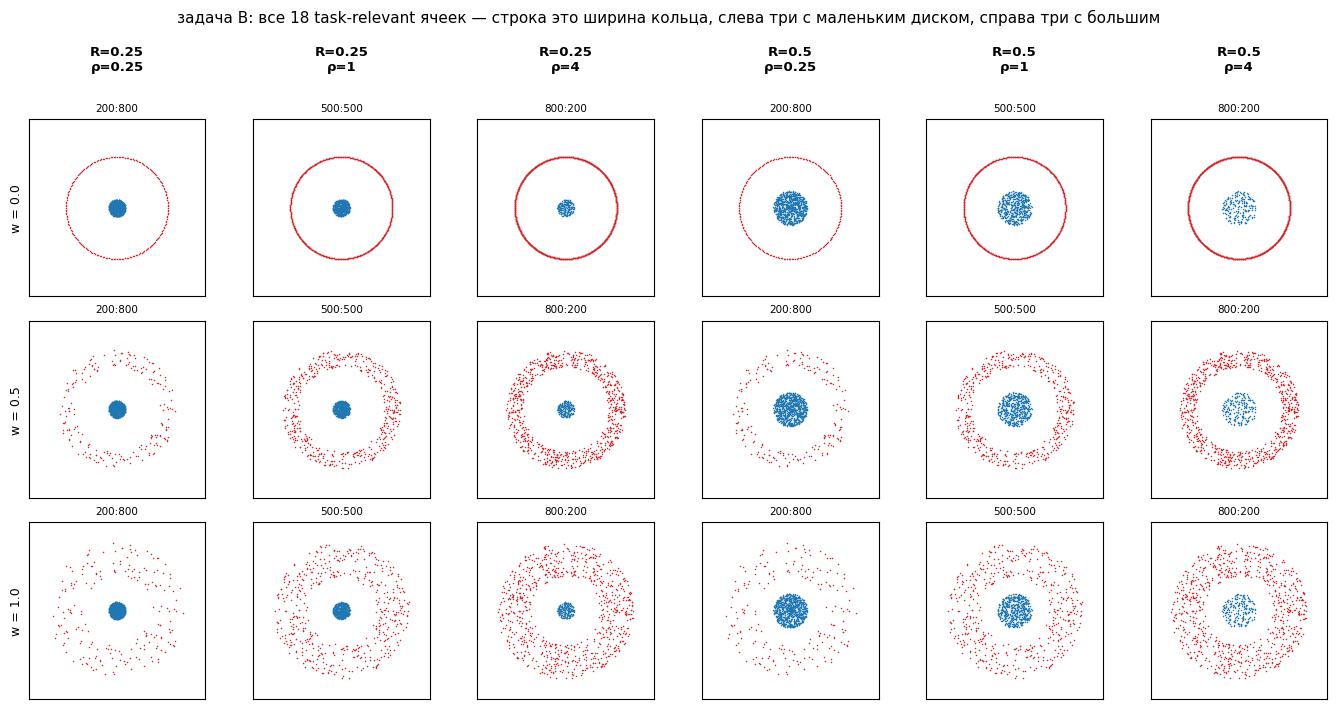

In [22]:
fig = dplt.plot_dataset_grid(REL, dsw.dataset_points, ncols=6, size=2.15,
    xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), label_of=label,
    row_labels=[f"w = {w}" for w in W3],
    col_labels=["R=0.25\nρ=0.25", "R=0.25\nρ=1", "R=0.25\nρ=4",
                "R=0.5\nρ=0.25", "R=0.5\nρ=1", "R=0.5\nρ=4"],
    title="задача B: все 18 task-relevant ячеек — строка это ширина кольца, "
          "слева три с маленьким диском, справа три с большим")
plt.show()

## 4.1 Ось ширины: что на ней на самом деле меняется

Эта ось задумывалась как чистая ось плотности: числа точек кольца и диска, радиус диска и бокс на ней
неподвижны, а переход `w = 0.5 → 1.0` увеличивает расстояние до ближайшего соседа в 1.4 раза, переход
от `w = 0` — втрое.

**Но меняется на ней не только плотность, и это надо назвать прямо.** Кольцо расширяется внутрь и
наружу одновременно, поэтому его внутренний край едет к центру: 1.5 → 1.25 → 1.0. Вместе с ним
сужается **просвет** между фичей и внутренностью — `1.5 − w/2 − R`, то есть 1.25 → 1.00 → 0.75 при
`R = 0.25` и 1.00 → 0.75 → 0.50 при `R = 0.5`. Плотность падает и просвет сужается на одной оси.

Поэтому ось читается двумя мишенями, и они отвечают на **разные** вопросы.

**Неподвижный щуп — средняя окружность радиуса 1.5.** Она стоит на месте при любой ширине, поэтому
вопрос на ней звучит чисто: портится ли картина в ФИКСИРОВАННОМ месте оттого, что точки легли реже?

**Мишень вердикта — внутренний край.** Она едет вместе с фичей, и вопрос на ней другой: следует ли
структура сети за краем особенности?

Обе мишени читаются в обычных единицах — **скор, делённый на `diam(A)`**, как везде в этом проекте.
Но у внутреннего края диаметр вдоль оси меняется (3.0 → 2.5 → 2.0), поэтому рядом со скором на каждом
ряду стоит **`×N` — во сколько медиана цели лучше медианы её собственных нулей**. Это отношение
безразмерно, диаметр в нём сокращается, и оно сравнимо вдоль всей оси без оговорок (§2.4). Куда
нормировка тянет скор, известно заранее: потолок прибора равен `h/2 / diam(A)` и с уменьшением мишени
**растёт** — 0.0113 → 0.0136 → 0.0170, — то есть нормировка играет **против** улучшения, а не за него.

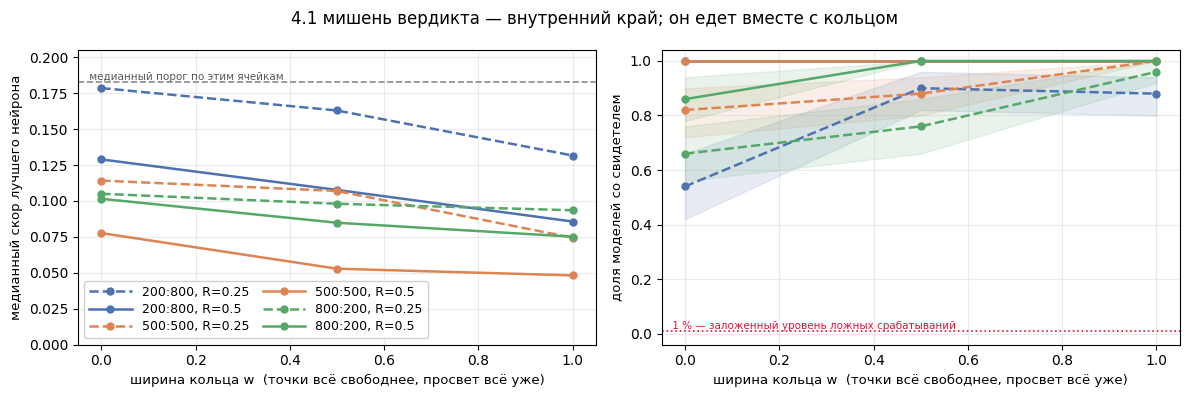

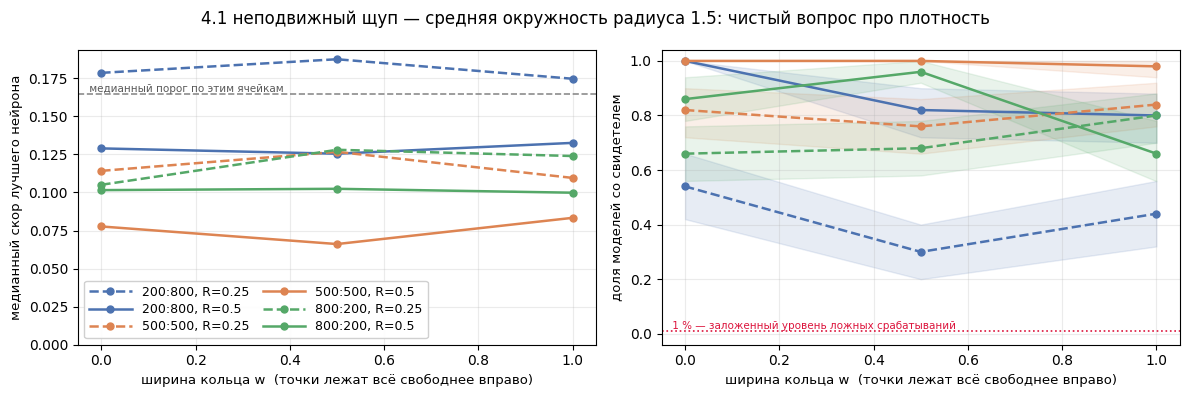

In [23]:
COL = {0.25: "#4c72b0", 1.0: "#dd8452", 4.0: "#55a868"}
panels_w = [{"label": f"{dsw.n_ring_of(r,1000)}:{1000-dsw.n_ring_of(r,1000)}, R={R}",
             "sel": {"rho": r, "R": R, "T": 1000}, "colour": COL[r],
             "ls": "-" if R == 0.5 else "--"}
            for r in RHO3 for R in (0.25, 0.5)]

cw = cells.copy()
cw["просвет"]  = 1.5 - cw.w / 2 - cw.R
cw["пол/цель"] = cw.med_null / cw.med_target
cw["диаметр"]  = [2 * dsw.target_radius(f, w) for f, w in zip(cw.family, cw.w)]
cw["абс_цель"] = cw.med_target * cw["диаметр"]

fig = dplt.plot_axis_panels(cells, "w", panels_w, family="edge",
    xlabel="ширина кольца w  (точки всё свободнее, просвет всё уже)",
    suptitle="4.1 мишень вердикта — внутренний край; он едет вместе с кольцом")
plt.show()

fig = dplt.plot_axis_panels(cells, "w", panels_w, family="t_mid",
    xlabel="ширина кольца w  (точки лежат всё свободнее вправо)",
    suptitle="4.1 неподвижный щуп — средняя окружность радиуса 1.5: чистый вопрос про плотность")
plt.show()

In [24]:
# Доля свидетелей на неподвижном щупе дрожит порогом, а не плотностью: 1-й перцентиль
# сотни нулей есть почти минимум и шумен (§2.7). Проверка — общий порог на всю строку.
Bm = cells[(cells.task == "relevant") & (cells.family == "t_mid")
           & (cells.R < 1.0) & (cells["T"] == 1000)]
own, common = [], []
for _, g in Bm.groupby(["rho", "R"]):
    g = g.sort_values("w")
    bar = float(g.threshold.median())
    fixed = [float((best[(best.dataset_type == r.cell) & (best.family == "t_mid")
                         & (best.feature_role == "target")].score <= bar).mean())
             for r in g.itertuples()]
    own.append(g.rate.max() - g.rate.min()); common.append(max(fixed) - min(fixed))
print(f"неподвижный щуп: размах доли внутри строки {min(own):.2f}-{max(own):.2f} при своём пороге "
      f"и {min(common):.2f}-{max(common):.2f} при общем пороге строки")

неподвижный щуп: размах доли внутри строки 0.02-0.30 при своём пороге и 0.02-0.14 при общем пороге строки


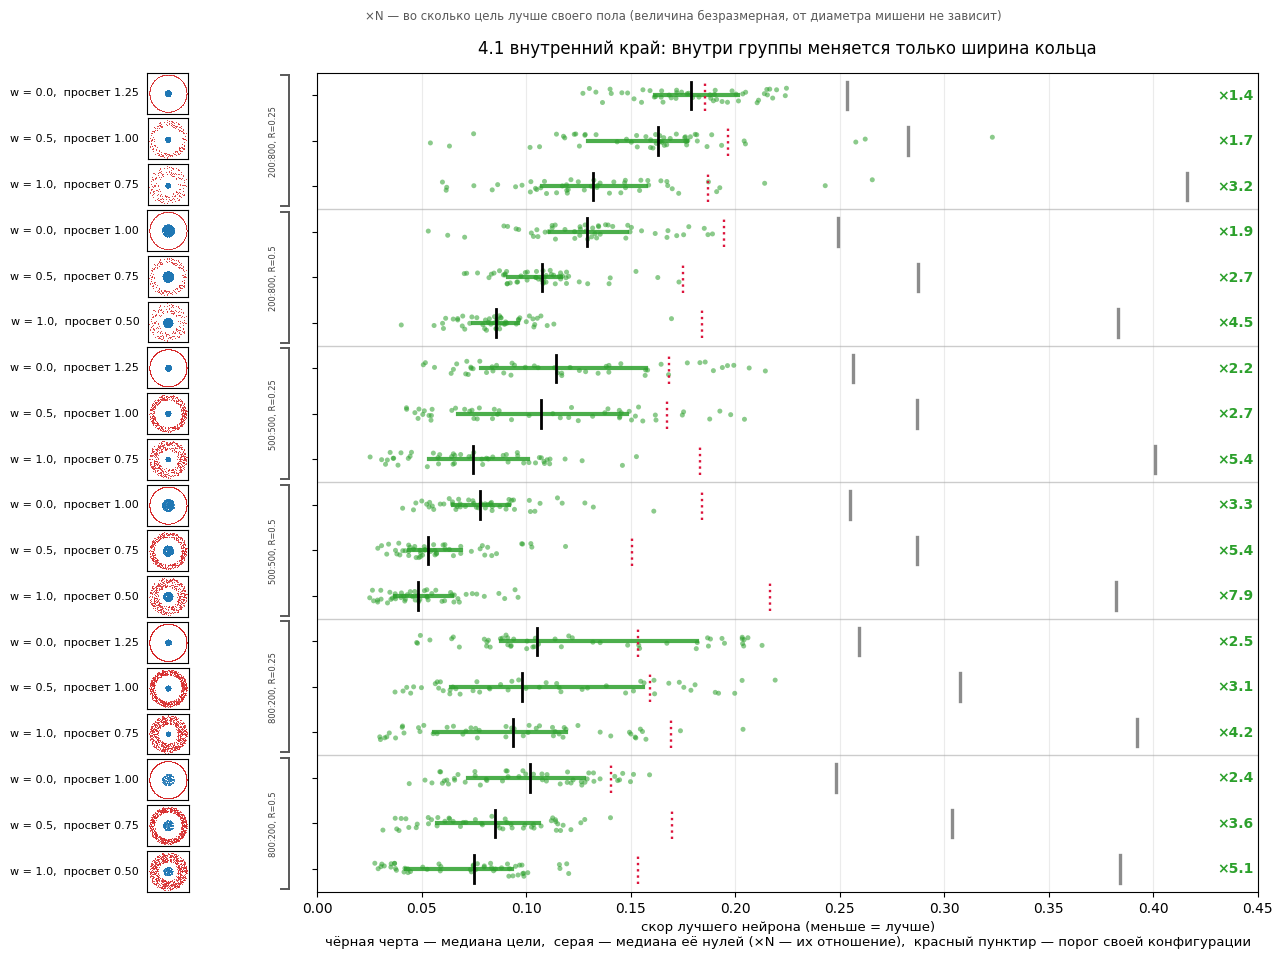

In [25]:
# Все восемнадцать релевантных ячеек; внутри группы меняется только ширина кольца,
# а с ней — просвет между фичей и внутренностью.
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for rho in RHO3:
    for R in (0.25, 0.5):
        for w in W3:
            n, fam = C(task="relevant", w=w, R=R, rho=rho, T=1000)[0], FAM(w)
            b = best[(best.dataset_type == n) & (best.family == fam)]
            r = cells[(cells.cell == n) & (cells.family == fam)].iloc[0]
            rows.append((f"w = {w},  просвет {1.5 - w/2 - R:.2f}",
                         b[b.feature_role == "target"].score, dplt.CT))
            thumbs.append(n); thr.append(float(r.threshold))
            rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
        nr = dsw.n_ring_of(rho, 1000)
        groups.append((f"{nr}:{1000-nr}, R={R}", 3))
fig = dplt.plot_strips(rows, xlim=(0, 0.45), row_thresholds=thr, height=0.42,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="4.1 внутренний край: внутри группы меняется только ширина кольца",
    caption="×N — во сколько цель лучше своего пола (величина безразмерная, "
            "от диаметра мишени не зависит)")
plt.show()

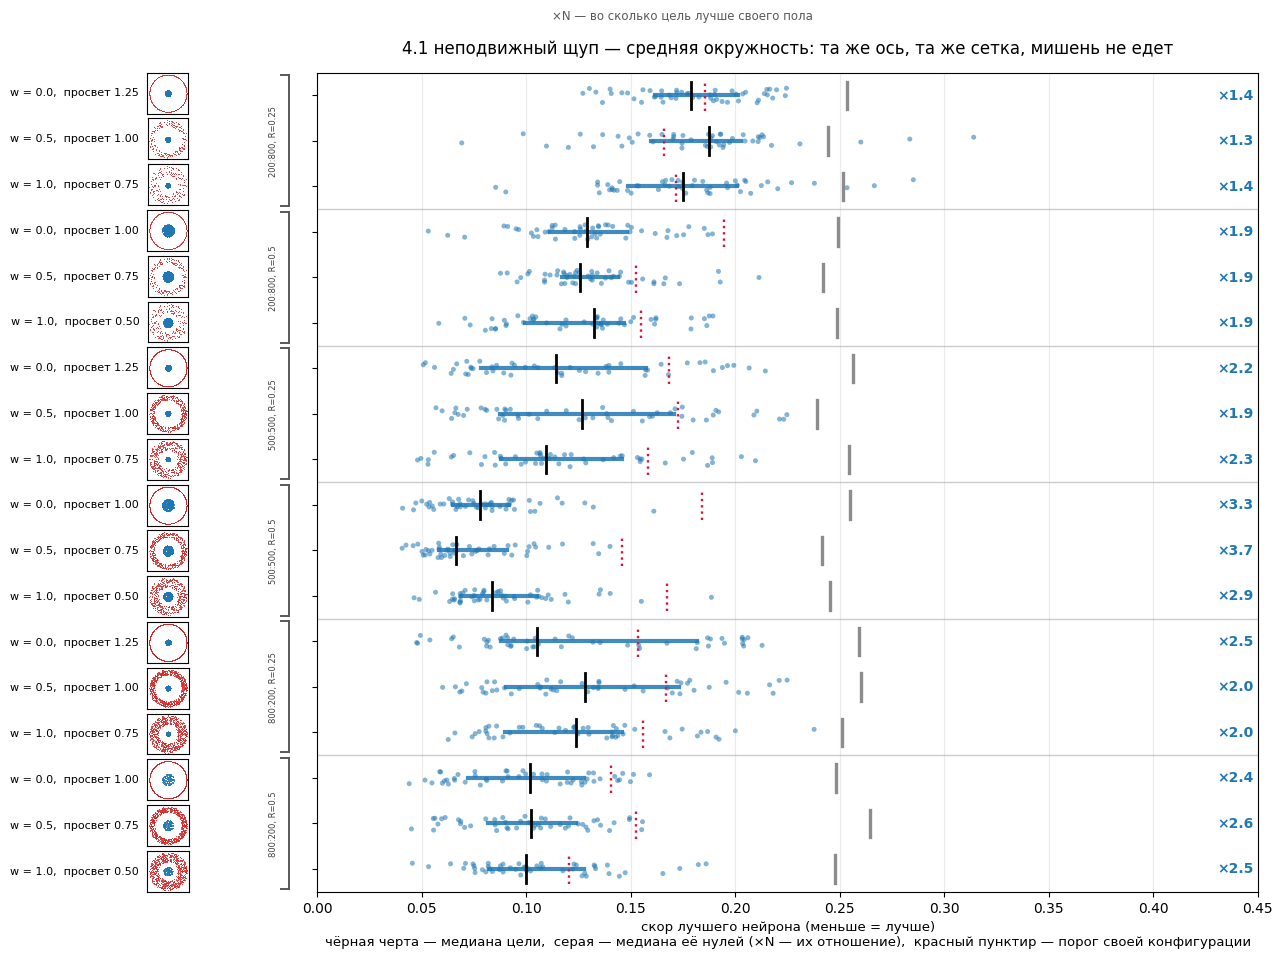

In [26]:
# Та же сетка и та же ось, но мишень НЕПОДВИЖНА: средняя окружность радиуса 1.5.
# Сравнивать надо с предыдущей картинкой ряд в ряд — первый ряд каждой группы
# в обеих один и тот же, потому что при w = 0 внутренний край и есть эта окружность.
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for rho in RHO3:
    for R in (0.25, 0.5):
        for w in W3:
            n = C(task="relevant", w=w, R=R, rho=rho, T=1000)[0]
            b = best[(best.dataset_type == n) & (best.family == "t_mid")]
            r = cells[(cells.cell == n) & (cells.family == "t_mid")].iloc[0]
            rows.append((f"w = {w},  просвет {1.5 - w/2 - R:.2f}",
                         b[b.feature_role == "target"].score, dplt.FAM_COLOUR["t_mid"]))
            thumbs.append(n); thr.append(float(r.threshold))
            rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
        nr = dsw.n_ring_of(rho, 1000)
        groups.append((f"{nr}:{1000-nr}, R={R}", 3))
fig = dplt.plot_strips(rows, xlim=(0, 0.45), row_thresholds=thr, height=0.42,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="4.1 неподвижный щуп — средняя окружность: та же ось, та же сетка, мишень не едет",
    caption="×N — во сколько цель лучше своего пола")
plt.show()

### Что видно

**На неподвижном щупе не происходит ничего.** Все шесть линий средней окружности горизонтальны:
размах медианы внутри линии 0.003–0.023 против 0.121 между линиями. На полосовой диаграмме это видно
построчно — внутри каждой группы ряды ложатся друг на друга и медианами, и хвостами, а `×N` стоит на
месте: 1.4 → 1.3 → 1.4, 1.9 → 1.9 → 1.9, 3.3 → 3.7 → 2.9, размах внутри группы 0.06–0.71 и без
согласованного знака. Точки кольца ложатся втрое свободнее — и на фиксированном радиусе 1.5 это не
меняет ни медиану, ни форму распределения. Это и есть ответ про плотность: **сама по себе она ничего
не портит**. Доля свидетелей на этом щупе дрожит сильнее (до 0.30 внутри линии), но дрожит она
порогом: 1-й перцентиль сотни нулей есть почти минимум и шумен (§2.7), и при общем пороге строки
размах падает вдвое.

**Одна группа выбивается вниз, и она же худшая по всей сетке.** В группе `200:800, R = 0.25` —
обеднённое кольцо при маленьком диске — доля свидетелей идёт 0.54 / 0.30 / 0.44, то есть в двух строках
из трёх вердикт проходит меньше половины моделей: медиана цели там оказывается **правее порога**
(0.188 против 0.166 и 0.175 против 0.172). Это не сбой отсчёта: цель в тех же строках в 1.3–1.4 раза
лучше медианы своих нулей (0.24) — просто порог берётся по 1-му перцентилю нулей, а не по их медиане,
и планка стоит намного левее. На мишени вердикта та же группа даёт 0.54 / 0.90 / 0.88. Худший угол сетки — обеднённая
фича вместе с маленькой внутренностью, и §4.2 с §4.3 разбирают обе эти координаты по отдельности.

**А на мишени вердикта улучшается всё — и в обычном нормированном скоре тоже.** Медиана идёт
0.1786 → 0.1630 → 0.1317 в худшей строке и 0.0777 → 0.0529 → 0.0482 в лучшей; улучшение **в шести
строках из шести**, и это уже после деления на `diam(A)`. Отношение «пол / цель», от диаметра вовсе
не зависящее, растёт с 1.4–3.3 при `w = 0` до 3.2–7.9 при `w = 1.0`.

**Две полосовые диаграммы стоит сравнить ряд в ряд.** Сетка, модели, критерий и порог в них одни и
те же — различается только мишень. **Первый ряд каждой группы в обеих картинках один и тот же**: при
`w = 0` кольца нет, и внутренний край совпадает со средней окружностью, поэтому обе начинаются с
1.4 / 1.9 / 2.2 / 3.3 / 2.5 / 2.4. Дальше одна картинка уезжает влево, а `×N` в ней растёт монотонно
в шести группах из шести (до 3.2, 4.5, 5.4, 7.9, 4.2, 5.1), другая стоит на месте. Расходятся они
ровно там, где мишень начинает ехать вместе с фичей. Доля свидетелей по итогу оси
нигде не падает (0.54 → 0.88, 0.66 → 0.96, 0.82 → 1.00), а в двух строках она 1.00 с самого начала.

**Нормировка при этом работает ПРОТИВ наблюдаемого улучшения, а не за него.** Мишень по дороге
уменьшается, а нормированный потолок прибора равен `h/2 / diam(A)` и потому растёт: 0.0113 → 0.0136 →
0.0170. То есть достижимый предел вдоль оси **ухудшается** ровно в полтора раза, а измеренный скор
улучшается в 1.1–1.6 раза. В отношении «достигнутое / потолок» — единственном, где обе поправки уже
учтены, — это улучшение в **1.7–2.4 раза**, и ровно во столько же растёт независимое от него
отношение «пол / цель». Наблюдаемое в нормированном скоре есть нижняя оценка настоящего.

**Видно это и на нерелевантном датасете, где следовать не за чем.** Там та же мишень едет по тем же
радиусам, и нормированный скор ведёт себя ровно так, как велит арифметика уменьшения мишени: он
**ухудшается**, 0.635 → 0.695 → 0.798, а отношение «пол / цель» так и остаётся ниже единицы
(0.64 → 0.85) — цель хуже случайности при любой ширине. Один и тот же геометрический ход мишени даёт
там ухудшение, здесь улучшение; разница — в том, есть ли чему следовать.

**Плотностью это тоже не объяснить — знак не тот.** Гипотеза плотности предсказывает, что более
редкая фича даёт худшего свидетеля. Здесь фича становится втрое реже, а свидетель — вдвое лучше.

**Что же меняется? Просвет.** Вместе с внутренним краем к центру едет и граница между классами:
просвет `1.5 − w/2 − R` сужается 1.25 → 1.00 → 0.75 и 1.00 → 0.75 → 0.50 (он подписан на каждом ряду
полосовой диаграммы). Чем он уже, тем плотнее зона контакта прижата к внутреннему краю — то есть к
мишени.

### Вывод

**Плотность особенности не модулирует качество свидетеля.** На неподвижном щупе она не делает ничего;
а там, где скор всё же движется, он движется в сторону, **противоположную** предсказанию гипотезы
плотности, и объясняется геометрией — сужением просвета, а не теснотой точек.

**Ось ширины оказалась не осью плотности, а первой осью просвета.** Вторую даёт §4.3, где просвет
сужается с другой стороны — ростом диска. Знак у обеих один, и вместе они складываются в механизм,
который формулируется в конце §4.3.

## 4.2 Ось баланса: `ρ` — как точки поделены между двумя объектами

Баланс `ρ = n_кольца / n_диска` перекладывает точки между объектами, **не трогая геометрию**:
`ρ = 0.25` даёт 200 точек кольцу и 800 диску, `ρ = 4` наоборот, `ρ = 1` делит поровну. Суммарное
число точек при этом постоянно, поэтому ось отвечает именно на вопрос «кому из двух объектов точки
нужнее».

Здесь линий шесть — по одной на каждую комбинацию `(w, R)`, — и внутри линии меняется только баланс.
Мишень снова вердиктная, внутренний край: ширина внутри линии постоянна, поэтому мишень внутри линии
одна и та же, и нормированный скор сравним прямо.

Рядом со скором показано **безразмерное отношение «пол / цель»** (числа `×N` справа от каждого ряда).
Оно нужно потому, что вместе с балансом меняется поле в ячейке, а значит и пол: скор мог бы двигаться
не оттого, что цель воспроизводится лучше, а оттого, что случайной компоненте стало труднее. Отношение
от этого свободно.

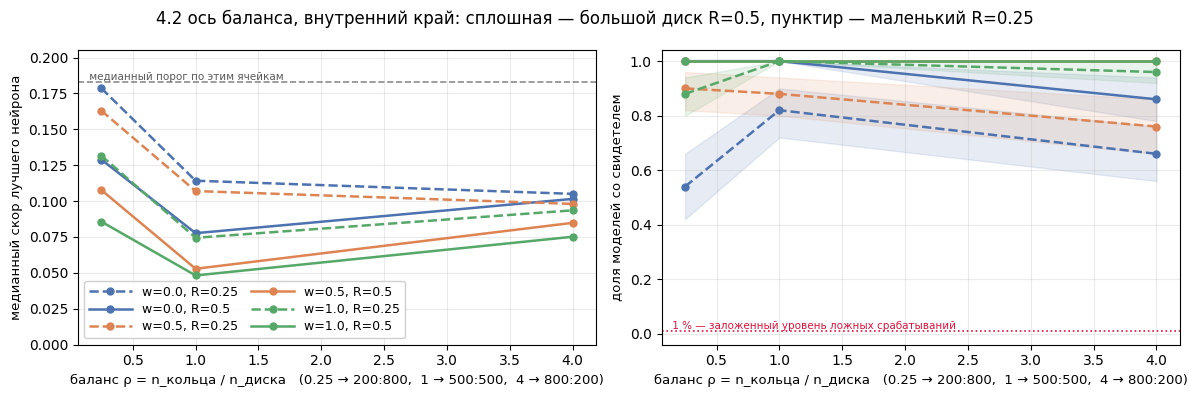

In [27]:
panels_rho = [{"label": f"w={w}, R={R}", "sel": {"w": w, "R": R, "T": 1000},
               "colour": {0.0: "#4c72b0", 0.5: "#dd8452", 1.0: "#55a868"}[w],
               "ls": "-" if R == 0.5 else "--"}
              for w in W3 for R in (0.25, 0.5)]
fig = dplt.plot_axis_panels(cells, "rho", panels_rho, family="edge",
    xlabel="баланс ρ = n_кольца / n_диска   (0.25 → 200:800,  1 → 500:500,  4 → 800:200)",
    suptitle="4.2 ось баланса, внутренний край: сплошная — большой диск R=0.5, пунктир — маленький R=0.25")
plt.show()

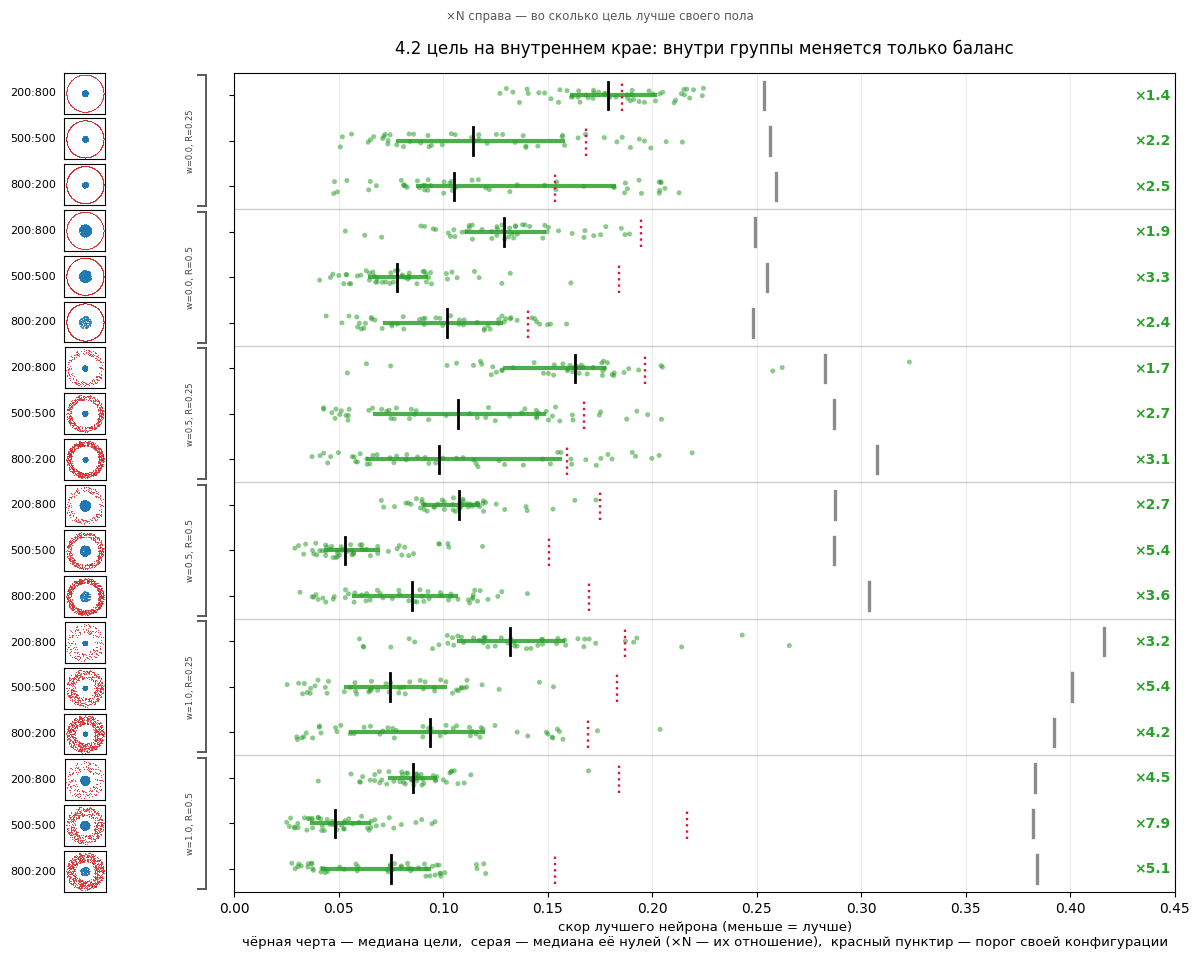

In [28]:
# Все восемнадцать релевантных ячеек; внутри группы меняется только баланс.
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for w in W3:
    for R in (0.25, 0.5):
        for rho in RHO3:
            n, fam = C(task="relevant", w=w, R=R, rho=rho, T=1000)[0], FAM(w)
            b = best[(best.dataset_type == n) & (best.family == fam)]
            r = cells[(cells.cell == n) & (cells.family == fam)].iloc[0]
            nr = dsw.n_ring_of(rho, 1000)
            rows.append((f"{nr}:{1000-nr}", b[b.feature_role == "target"].score, dplt.CT))
            thumbs.append(n); thr.append(float(r.threshold))
            rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
        groups.append((f"w={w}, R={R}", 3))
fig = dplt.plot_strips(rows, xlim=(0, 0.45), row_thresholds=thr, height=0.42,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="4.2 цель на внутреннем крае: внутри группы меняется только баланс",
    caption="×N справа — во сколько цель лучше своего пола")
plt.show()

### Что видно

**Обеднённая фича — худшая точка всегда.** `ρ = 0.25`, то есть 200 точек на кольце против 800 на
диске, даёт худший результат **во всех шести линиях** и по нормированному скору, и по безразмерному
`×N`. Это единственное утверждение об этой оси, которое держится без исключений.

**А вот «оптимум при равенстве» держится не везде — в четырёх линиях из шести.** В двух оставшихся,
и обе они с маленьким диском `R = 0.25`, скор продолжает улучшаться и дальше `ρ = 1`: 0.1786 → 0.1142
→ 0.1050 и 0.1630 → 0.1070 → 0.0981. `×N` там ведёт себя так же (1.42 → 2.24 → 2.47 и
1.73 → 2.68 → 3.14), так что дело не в поле и не в пороге.

**Исключения не случайны, и они складываются в правило.** Оба приходятся на маленький диск, и это
объяснимо: точек объекту нужно столько, сколько нужно **для его размера**. Шаг между точками диска
`R = 0.25` при 200 точках равен 0.031 — мельче, чем у диска `R = 0.5` при 500 точках (0.040). Маленький
диск уже разрешён при 200 точках, поэтому отдавать ему больше нечего, и всё, что забирается у него,
достаётся кольцу с пользой. У большого диска этот запас кончается, и оптимум возвращается к равенству.

**Безразмерное отношение подтверждает картину и снимает подозрение на пол.** Вместе с балансом меняется
поле, а значит и пол; скор мог бы двигаться не оттого, что цель воспроизводится лучше, а оттого, что
случайной компоненте стало труднее. `×N` от этого свободно — и даёт тот же порядок и те же исключения.

**Доля свидетелей — самый грубый из трёх отсчётов.** В двух линиях она упёрлась в 1.00 на всех трёх
балансах, поэтому по ней минимум приходится на `ρ = 0.25` лишь в четырёх линиях из шести. Читать эту
ось надо по скору и по `×N`.

### Вывод

**Объекту нужно столько точек, сколько нужно для его размера, и обеднять фичу дороже всего.** Скор
определяется тем, хватает ли точек кольцу и диску по отдельности; худшая точка везде — обеднённое
кольцо. Где именно лежит оптимум, зависит от того, насколько велик диск: с маленьким диском выгодно
отдавать точки кольцу и дальше равенства.

**А теснота точек тут ни при чём.** Вдоль `ρ` при `w = 0.5` шаг между точками кольца идёт
0.153 → 0.097 → 0.077, и скор ведёт себя немонотонно; вдоль `w` при тех же числах точек шаг растёт так
же сильно, а на неподвижном щупе не меняется ничего. Одна и та же величина в одном случае «объясняет»
изменение, в другом не объясняет его отсутствие — значит она не та величина.

## 4.3 Ось диска: радиус внутренности

Осталась третья ось — радиус диска противоположного класса. Она проверяет тезис о равноправии фичи и
внутренности прямо: если релевантная особенность образуется парой, то геометрия внутренности должна
давать эффект, сопоставимый с эффектом самой фичи.

Радиус диска принимает два значения, 0.25 и 0.5, поэтому каждая линия здесь — отрезок из двух точек,
и всего таких отрезков девять, по одному на комбинацию `(w, ρ)`. Мишень вердиктная, внутренний край:
ширина внутри отрезка постоянна.

Просвет между диском и кольцом в этом эксперименте **не исследуется**: он по дизайну удерживается не
меньше 0.5 во всех ячейках, и этого достаточно, чтобы задача была разрешима без резких перепадов
значения на малом расстоянии. Здесь он фиксированное условие, а не переменная.

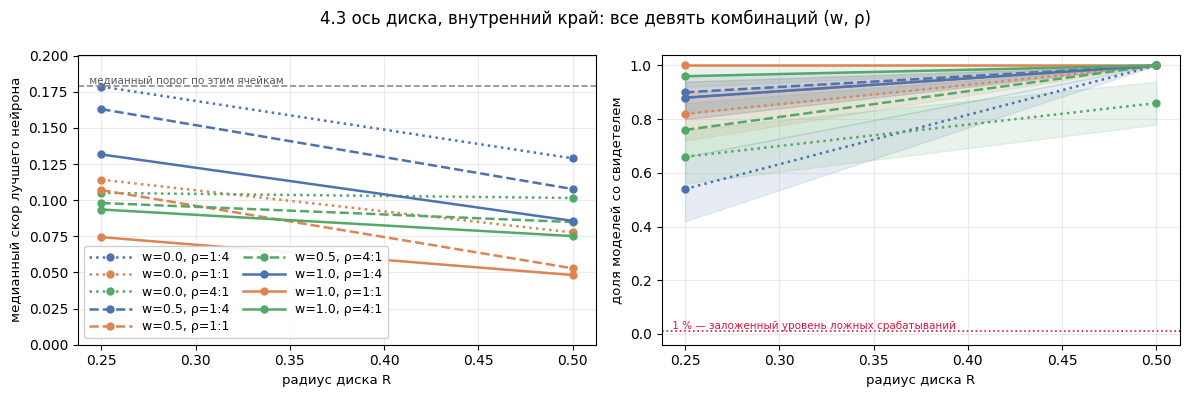

больший диск лучше в 9 случаях из 9; медианное улучшение 0.0365 (32%); по безразмерному «пол / цель» — в 8 из 9
порог внутри пары сдвигается на 0.0158 по медиане, вверх в 4 парах из 9 — то есть без знака
одинаковый просвет 0.75:  w=0.5 R=0.5 → абс.Чамфер 0.132, пол/цель 5.43 | w=1.0 R=0.25 → абс.Чамфер 0.149, пол/цель 5.38
одинаковый просвет 1.00:  w=0.5 R=0.25 → абс.Чамфер 0.267, пол/цель 2.68 | w=0.0 R=0.5 → абс.Чамфер 0.233, пол/цель 3.28


In [29]:
panels_R = [{"label": f"w={w}, ρ={ratio_label(r)}", "sel": {"w": w, "rho": r, "T": 1000},
             "colour": COL[r], "ls": {0.0: ":", 0.5: "--", 1.0: "-"}[w]}
            for w in W3 for r in RHO3]
# Якорная ячейка эксперимента 1 стоит при R = 1.0 и другой геометрии, на этой оси ей не место.
fig = dplt.plot_axis_panels(cells[cells.R < 1.0], "R", panels_R, family="edge",
    xlabel="радиус диска R", suptitle="4.3 ось диска, внутренний край: все девять комбинаций (w, ρ)")
plt.show()

E18 = dsw.inner_edge(cw[(cw.task == "relevant") & (cw.R < 1.0) & (cw["T"] == 1000)])
piv = E18.pivot_table(index=["w", "rho"], columns="R", values="med_target")
pth = E18.pivot_table(index=["w", "rho"], columns="R", values="threshold")
prt = E18.pivot_table(index=["w", "rho"], columns="R", values="пол/цель")
print(f"больший диск лучше в {int((piv[0.5] < piv[0.25]).sum())} случаях из {len(piv)}; "
      f"медианное улучшение {float((piv[0.25]-piv[0.5]).median()):.4f} "
      f"({float(((piv[0.25]-piv[0.5])/piv[0.25]).median()):.0%}); "
      f"по безразмерному «пол / цель» — в {int((prt[0.5] > prt[0.25]).sum())} из {len(prt)}")
print(f"порог внутри пары сдвигается на {float((pth[0.5]-pth[0.25]).abs().median()):.4f} по медиане, "
      f"вверх в {int((pth[0.5] > pth[0.25]).sum())} парах из {len(pth)} — то есть без знака")

# Просвет 1.5 − w/2 − R совпадает у двух пар ячеек с разной геометрией: это и есть
# проверка, исчерпывается ли эффект шириной зазора.
for cl, g in E18[E18.rho == 1.0].groupby("просвет"):
    if len(g) > 1:
        cells_txt = " | ".join(f"w={r['w']} R={r['R']} → абс.Чамфер {r['абс_цель']:.3f}, "
                               f"пол/цель {r['пол/цель']:.2f}" for _, r in g.iterrows())
        print(f"одинаковый просвет {cl:.2f}:  {cells_txt}")

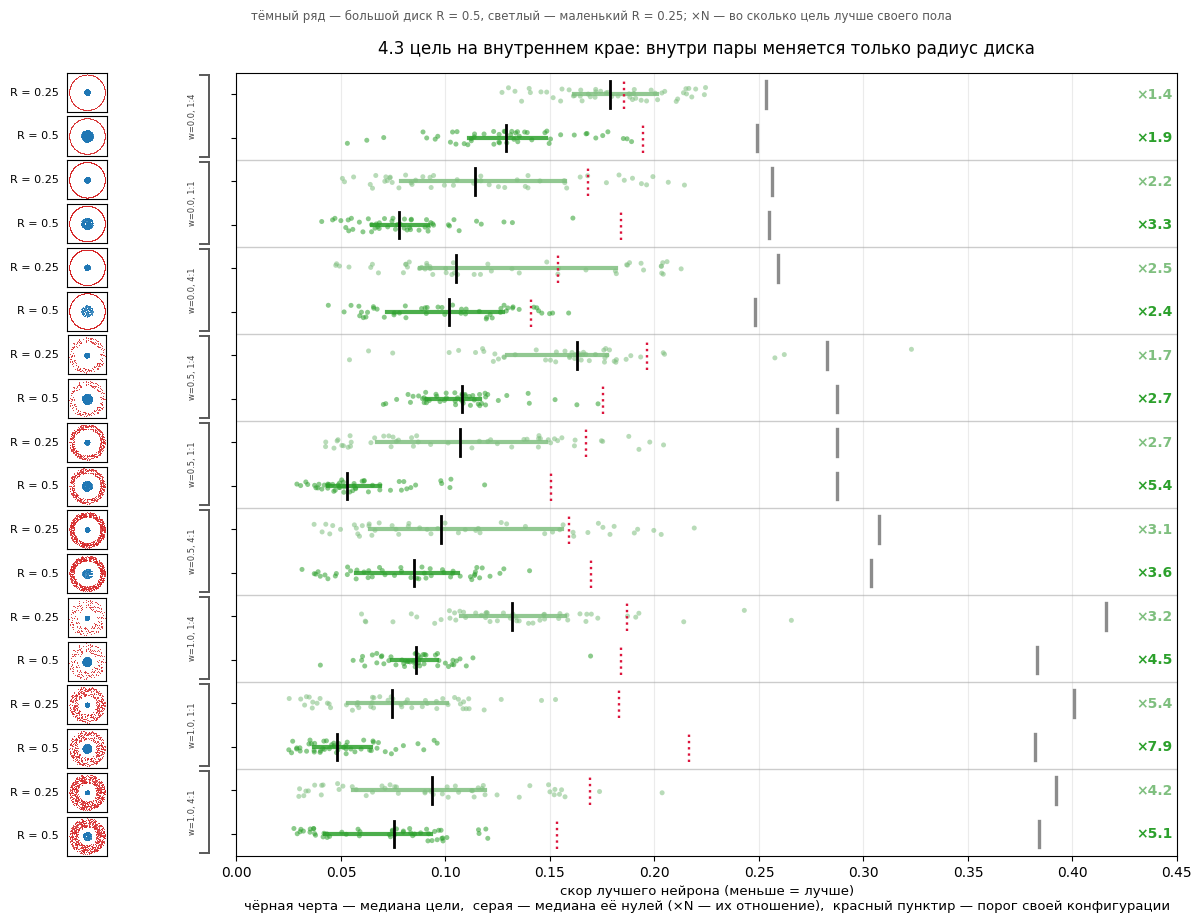

In [30]:
# Внутри пары меняется только радиус диска; всё остальное держится.
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for w in W3:
    for rho in RHO3:
        for R in (0.25, 0.5):
            n, fam = C(task="relevant", w=w, R=R, rho=rho, T=1000)[0], FAM(w)
            b = best[(best.dataset_type == n) & (best.family == fam)]
            r = cells[(cells.cell == n) & (cells.family == fam)].iloc[0]
            rows.append((f"R = {R}", b[b.feature_role == "target"].score,
                         dplt.CT if R == 0.5 else "#7fbf7f"))
            thumbs.append(n); thr.append(float(r.threshold))
            rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
        groups.append((f"w={w}, {ratio_label(rho)}", 2))
fig = dplt.plot_strips(rows, xlim=(0, 0.45), row_thresholds=thr, height=0.40,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="4.3 цель на внутреннем крае: внутри пары меняется только радиус диска",
    caption="тёмный ряд — большой диск R = 0.5, светлый — маленький R = 0.25; "
            "×N — во сколько цель лучше своего пола")
plt.show()

### Что видно

**Больший диск даёт лучшего свидетеля, и это видно во всех трёх отсчётах.** По нормированному скору —
в **9 комбинациях из 9**; по безразмерному `×N` — в 8 из 9, причём единственное исключение
(`w = 0, ρ = 4`) даёт 2.44 против 2.47, то есть совпадение в пределах второго знака; по доле
свидетелей — в 8 из 9 при одном равенстве. Медианное улучшение скора 0.037, около трети его величины.

**Эффект согласован по знаку — этим он и отличается от плотности.** Радиус диска двигает скор в одну и
ту же сторону девять раз из девяти, тогда как трёхкратное разрежение точек на неподвижном щупе (§4.1)
не двигает его вовсе.

**Пол при этом стоит на месте.** Порог внутри пары сдвигается на 0.016 по медиане — вдвое меньше
эффекта, — и вверх лишь в четырёх парах из девяти, то есть без согласованного знака. Медианы нулей
(серые засечки) внутри пары тоже практически совпадают. Диск не меняет того, насколько трудно попасть
в окружность случайно; он меняет только то, насколько хорошо в неё попадает обученная сеть.

### Вывод

**Геометрия внутренности — работающая переменная**, и работает она в ту же сторону, что и ширина
кольца в §4.1.

**Обе оси делают одно и то же: сужают просвет.** Просвет между фичей и внутренностью равен
`1.5 − w/2 − R`; §4.1 сужает его, придвигая внутренний край к центру, §4.3 — раздувая диск наружу.
Зона, в которой два объекта разных классов взаимодействуют, лежит **в этом просвете**, и чем он уже,
тем плотнее она прижата к внутреннему краю — то есть к мишени. Отсюда и совпадение знаков: 6 строк из
6 по ширине, 9 пар из 9 по радиусу диска. Обе опоры — свои собственные измерения этих двух осей;
результат оси баланса (§4.2) сюда не входит.

**Это прямая проверка тезиса, ради которого внутренний край вообще стал мишенью.** Если бы релевантная
особенность была свойством одной фичи, радиус диска не должен был бы делать ничего. Если она есть
свойство **пары** — фича плюс внутренность противоположного класса, — то приближение любого из двух
объектов к другому должно улучшать картину у их контакта. Наблюдается второе, и наблюдается с двух
независимых сторон.

**Но просвет — механизм, а не единственная переменная.** Две пары ячеек имеют одинаковый просвет при
разной геометрии, и в обеих не хуже та, где диск крупнее: при просвете 1.00 абсолютный Чамфер 0.233
против 0.267 и отношение 3.28 против 2.68; при просвете 0.75 — 0.132 против 0.149 при практически
равном отношении 5.43 и 5.38. Собственный размер внутренности участвует помимо ширины зазора.

## Итог задачи B

Три оси дали три разных ответа, и вместе они складываются в один.

| ось | что двигает | эффект |
|---|---|---|
| ширина кольца `w` | плотность фичи **и** просвет одновременно | на неподвижном щупе **ничего** (размах 0.003–0.023, знак не согласован); на мишени вердикта улучшение в 6 строках из 6, «пол / цель» с 1.4–3.3 до 3.2–7.9 — и это просвет, а не плотность |
| баланс `ρ` | число точек у каждого из двух объектов | **есть**: обеднённая фича — худшая точка в 6 линиях из 6 и по скору, и по `×N`. Оптимум при равенстве — только в 4 из 6: с маленьким диском выгодно отдавать точки кольцу и дальше |
| радиус диска `R` | геометрию внутренности, а с ней просвет | **есть**, 9 из 9, около трети величины скора |

**Качество свидетеля определяется тем, хватает ли каждому объекту точек ДЛЯ ЕГО РАЗМЕРА, и геометрией
пары.** Теснота особенности не участвует ни как причина (задача A), ни как модулятор: на неподвижном
щупе её трёхкратное изменение не двигает ничего.

**Две из трёх осей оказались одной осью — осью просвета.** Ширина кольца и радиус диска сужают зазор
между фичей и внутренностью с разных сторон, и обе улучшают картину у внутреннего края. Это прямая
поддержка тезиса, ради которого внутренний край стал мишенью: релевантная особенность есть свойство
**пары**, и работает зона их контакта. С этим же сходится §2.8, где структура нашлась именно там.

**Проверка на другой мишени.** Оси баланса и диска считаются и на средней окружности: больший диск
лучше в 9 случаях из 9, медианное улучшение 24 % (против 32 % на внутреннем крае), оптимум баланса на
`ρ = 1` в 5 линиях из 6. Вывод от выбора мишени не зависит; меняется только величина.

**Одна оговорка о том, что здесь НЕ разделено.** Радиус диска меняет и его геометрию, и его площадную
плотность, и просвет. Матченные по просвету пары показывают, что просветом эффект не исчерпывается,
но геометрия и плотность диска на этой сетке не разделены, и утверждение сформулировано про радиус
как таковой.

---

# 5. Задача C — плотность или число точек?

**Вопрос.** Задача B ответила «число точек» на своей сетке. Здесь ответ проверяется там, где он мог
бы сломаться: при впятеро большей выборке, где абсолютный уровень плотности другой, а её отношение
между объектами то же.

**Зачем это нужно.** У утверждения «работает число точек» два разных прочтения, и здесь они
расходятся. Первое: важен **абсолютный** объём выборки, и тогда `T = 5000` должно всё заметно
улучшить. Второе: важна **достаточность** — хватает ли точек, чтобы объект был различим, — и тогда
улучшение должно упереться в потолок.

**Как проверяем.** Мишень вердиктная, внутренний край; `T = 5000` вместо 1000 при неизменной геометрии: обе плотности растут одновременно,
их отношение сохраняется. Срез — ось баланса при обеих ненулевых ширинах, в обеих задачах, для
task-relevant при `R = 0.5`. **12 ячеек.**

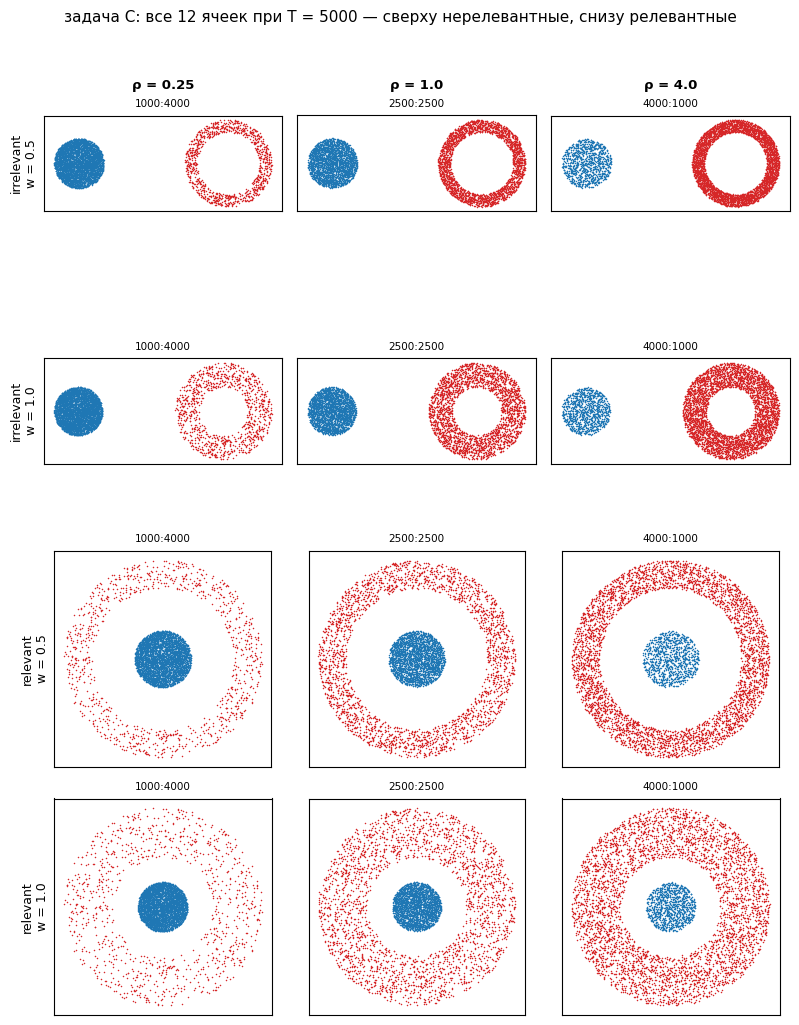

In [31]:
fig = dplt.plot_dataset_grid(BIG, dsw.dataset_points, ncols=3, size=2.4, label_of=label,
    row_labels=["irrelevant\nw = 0.5", "irrelevant\nw = 1.0",
                "relevant\nw = 0.5", "relevant\nw = 1.0"],
    col_labels=[f"ρ = {r}" for r in RHO3],
    title="задача C: все 12 ячеек при T = 5000 — сверху нерелевантные, снизу релевантные")
plt.show()

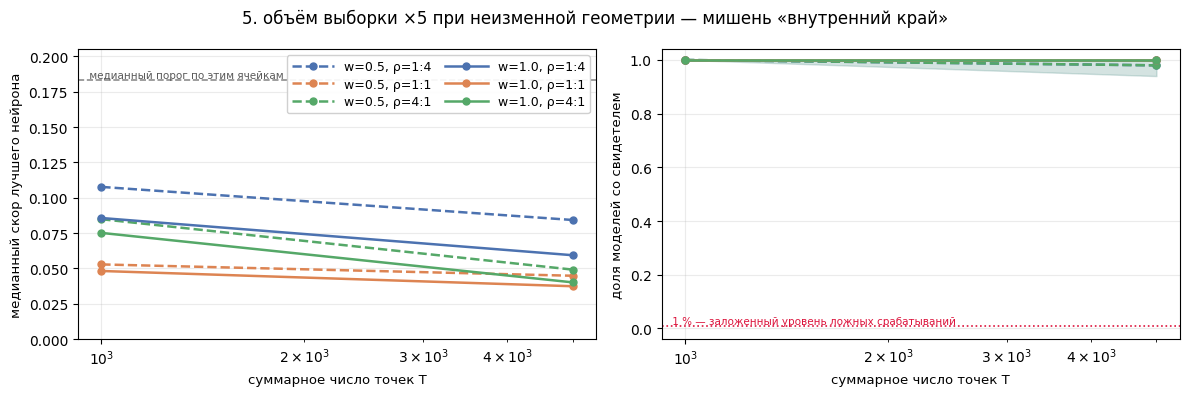

скор улучшился в 6 парах из 6, сдвиг 0.0080..0.0357
доля: было 1.00-1.00, стало 0.98-1.00


In [32]:
panels_T = [{"label": f"w={w}, ρ={ratio_label(r)}", "sel": {"w": w, "rho": r, "R": 0.5},
             "colour": COL[r], "ls": "-" if w == 1.0 else "--"}
            for w in (0.5, 1.0) for r in RHO3]
fig = dplt.plot_axis_panels(cells, "T", panels_T, family="edge", logx=True,
    xlabel="суммарное число точек T",
    suptitle="5. объём выборки ×5 при неизменной геометрии — мишень «внутренний край»")
plt.show()

S = EDGE[(EDGE.task == "relevant") & (EDGE.R == 0.5) & (EDGE.w > 0)]
p5 = S.pivot_table(index=["w", "rho"], columns="T", values="med_target")
r5 = S.pivot_table(index=["w", "rho"], columns="T", values="rate")
print(f"скор улучшился в {int((p5[5000] < p5[1000]).sum())} парах из {len(p5)}, "
      f"сдвиг {float((p5[1000]-p5[5000]).min()):.4f}..{float((p5[1000]-p5[5000]).max()):.4f}")
print(f"доля: было {r5[1000].min():.2f}-{r5[1000].max():.2f}, стало {r5[5000].min():.2f}-{r5[5000].max():.2f}")

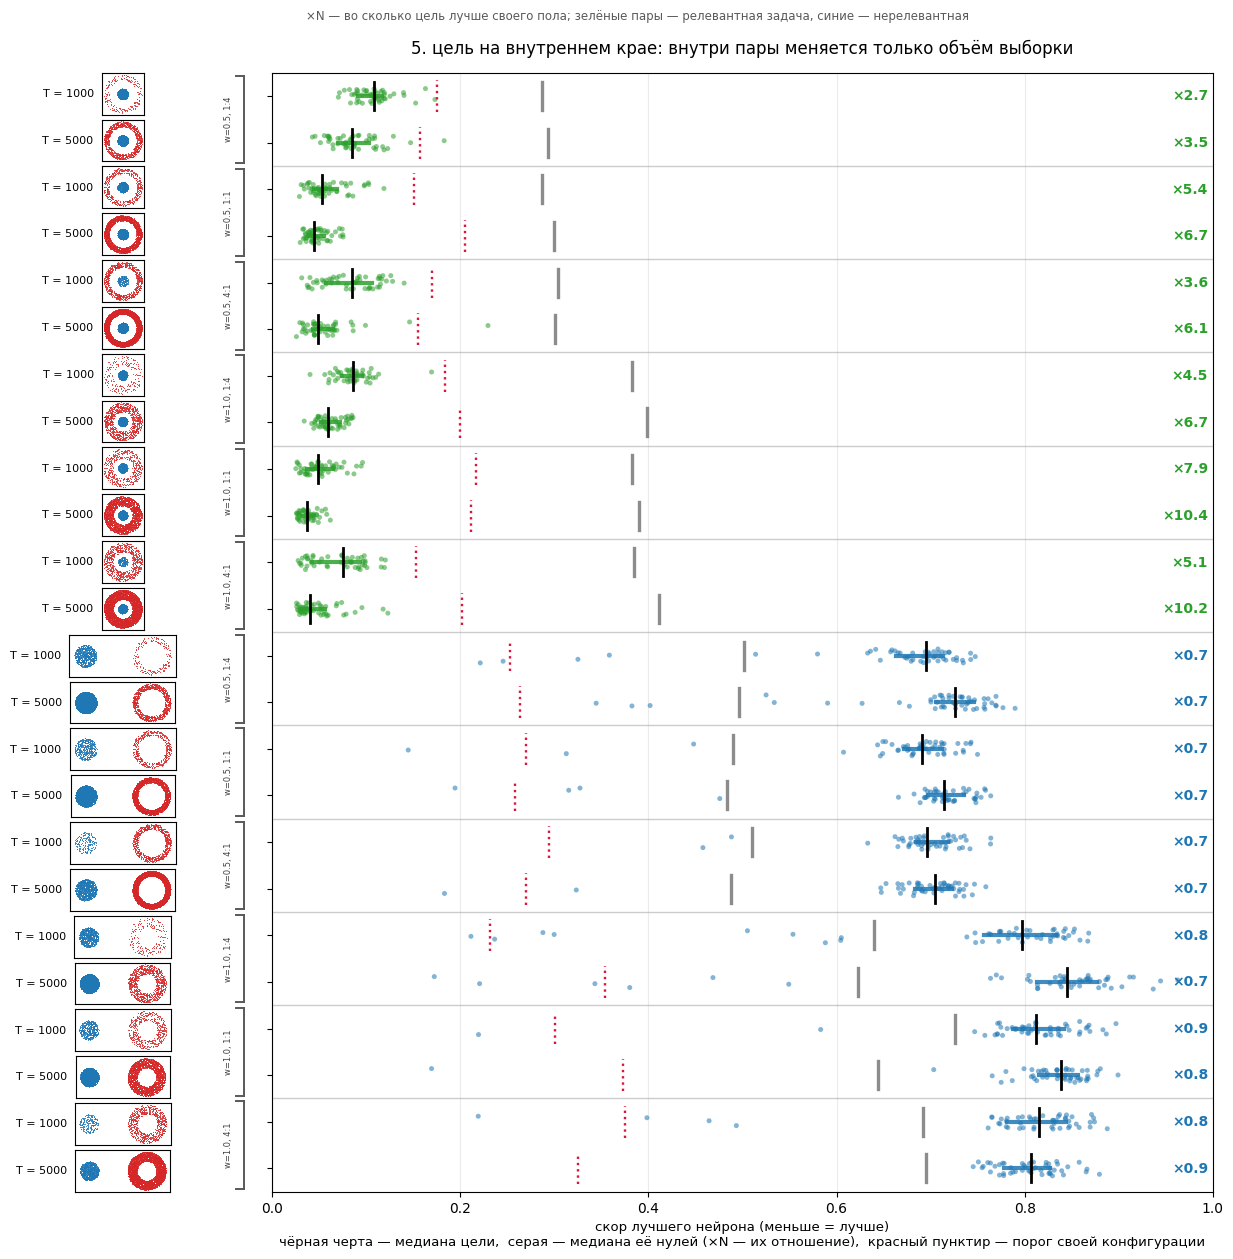

In [33]:
# Пара строк = одна геометрия при двух объёмах выборки; конфигурации не смешиваются.
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for task, col in (("relevant", dplt.CT), ("irrelevant", dplt.C1)):
    for w in (0.5, 1.0):
        for rho in RHO3:
            for T in (1000, 5000):
                sel = (C(task=task, w=w, rho=rho, T=T) if task == "irrelevant"
                       else C(task=task, w=w, R=0.5, rho=rho, T=T))
                n, fam = sel[0], FAM(w)
                b = best[(best.dataset_type == n) & (best.family == fam)]
                r = cells[(cells.cell == n) & (cells.family == fam)].iloc[0]
                rows.append((f"T = {T}", b[b.feature_role == "target"].score, col))
                thumbs.append(n); thr.append(float(r.threshold))
                rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
            groups.append((f"w={w}, {ratio_label(rho)}", 2))
fig = dplt.plot_strips(rows, xlim=(0, 1.0), row_thresholds=thr, height=0.44,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="5. цель на внутреннем крае: внутри пары меняется только объём выборки",
    caption="×N — во сколько цель лучше своего пола; зелёные пары — релевантная задача, "
            "синие — нерелевантная")
plt.show()

### Что видно

**Впятеро большая выборка улучшает скор, но вердикта не меняет.** Медиана сдвигается на 0.008–0.036 и
улучшается во всех шести парах — то есть эффект есть и он согласован по знаку, в отличие от эффекта
плотности. Но доля свидетелей была 1.00 и стала 0.98–1.00: двигаться ей уже некуда. Линии на левой
панели почти горизонтальны в логарифмической шкале — пятикратное увеличение выборки делает меньше,
чем перекладывание тех же точек между объектами в §4.2 (там размах внутри линии 0.038–0.074).

**Форма зависимости от баланса сохраняется.** При `T = 5000` порядок ровно тот же: `ρ = 0.25` хуже
всех. Значит дело не в абсолютных числах, а в том, чтобы каждому объекту хватало точек.

**На task-irrelevant стороне впятеро большая выборка не даёт вообще ничего**: доля 0.00–0.06, ряды
популяций совпадают с `T = 1000` до толщины линии, и цель по-прежнему хуже своего пола.

### Выводы

**Верно прочтение «достаточность», а не «абсолютный уровень».** Точки нужны, чтобы объект был
различим; после этого добавление ещё точек скор чуть улучшает, но вердикт уже насыщен, а
перекладывание точек между объектами двигает его сильнее. Именно поэтому баланс оказался сильнее
объёма.

**И это третий, независимый способ, которым плотность не подтвердилась.** В задаче A её меняли на
нерелевантной задаче, в §4.1 — на релевантной при постоянных числах точек, здесь — поднимали обе
плотности сразу. Ни один не дал эффекта в пользу гипотезы плотности.

---

# 6. Задача F — что говорит второй критерий

**Вопрос.** Всё до сих пор меряно одним прибором. Гомологический критерий задаёт о тех же нейронах
другой вопрос — **есть ли вообще замкнутая петля** в поле около особенности, — и согласие или
расхождение двух приборов само по себе информативно.

**Зачем это нужно.** Во-первых, вывод, стоящий на одном критерии, слабее вывода, который подтверждён
вторым и независимым. Во-вторых — и это важнее — критерии спрашивают **разное**: структурный меряет,
насколько точно линия уровня ложится **на мишень**, гомологический — существует ли петля в её
окрестности. Если геометрия двигает первый и не двигает второй, значит меняется не наличие петли, а
её положение, и это прямой ответ на вопрос, оставшийся открытым в §2.8.

**Как устроен критерий.** На облаке точек около мишени строится суперуровневая персистентность (обе
ориентации поля), и берётся самый длинный бар в `H_1`. Величина `persistence_margin` — насколько он
превосходит следующий бар и абсолютный пол в 10 % размаха поля. **`margin > 0` значит «есть
доминирующая петля»**; отрицательное значение — бары есть, но ни один не доминирует; `NaN` — баров
нет вовсе.

**Три оговорки, без которых числа читаются неправильно.**

*Первая.* Критерий смотрит на **окрестность** мишени (1.5 её радиуса), а не на саму кривую. Поэтому он
не знает, где именно проходит петля, — только что она есть где-то рядом. Это не изъян, а разделение
труда: ровно поэтому он дополняет структурный, а не дублирует его.

*Вторая.* Окрестность растёт вместе с радиусом мишени, поэтому `margin` **нельзя** сравнивать между
разными мишенями — только между ячейками при одной и той же. Всё ниже считается на мишени вердикта.

*Третья.* Слой 0 исключён: его линии уровня прямые, петли там не бывает по теореме, и включать его
значило бы просто разбавлять доли нулями.

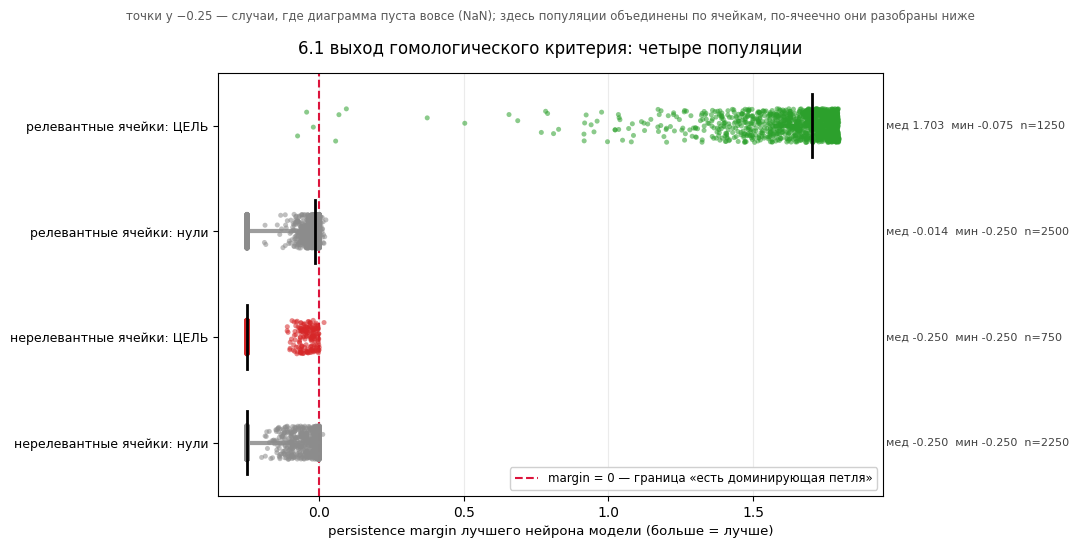

                         единиц  доля_с_петлёй  медиана_margin
task       feature_role                                       
irrelevant null            2250          0.003          -0.011
           target           750          0.001          -0.039
relevant   null            2500          0.014          -0.005
           target          1250          0.998           1.703

задача A по-ячеечно — доля моделей с петлёй на нерелевантной цели:
rho  0.25  1.00  4.00
w                    
0.0   0.0  0.00   0.0
0.5   0.0  0.02   0.0
1.0   0.0  0.00   0.0


In [34]:
hom  = dsw.homology_units(dsw.inner_edge(df))       # (ячейка, фича, модель) -> лучший margin
homc = dsw.homology_cells(hom)                      # то же, сведённое по ячейкам

rows = [(lab, hom[(hom.task == t) & (hom.feature_role == r)].margin.fillna(-0.25), col)
        for t, r, lab, col in (
            ("relevant",   "target", "релевантные ячейки: ЦЕЛЬ",   dplt.CT),
            ("relevant",   "null",   "релевантные ячейки: нули",   dplt.CN),
            ("irrelevant", "target", "нерелевантные ячейки: ЦЕЛЬ", dplt.C0),
            ("irrelevant", "null",   "нерелевантные ячейки: нули", dplt.CN))]
fig = dplt.plot_strips(rows, xlim=(-0.35, 1.95), height=0.9,
    vline=(0.0, "margin = 0 — граница «есть доминирующая петля»"),
    xlabel="persistence margin лучшего нейрона модели (больше = лучше)",
    title="6.1 выход гомологического критерия: четыре популяции",
    caption="точки у −0.25 — случаи, где диаграмма пуста вовсе (NaN); "
            "здесь популяции объединены по ячейкам, по-ячеечно они разобраны ниже")
plt.show()

print(hom.groupby(["task", "feature_role"])
         .agg(единиц=("witness", "size"), доля_с_петлёй=("witness", "mean"),
              медиана_margin=("margin", "median")).round(3).to_string())
print("\nзадача A по-ячеечно — доля моделей с петлёй на нерелевантной цели:")
A = homc[(homc.task == "irrelevant") & (homc.feature_role == "target") & (homc["T"] == 1000)]
print(A.pivot_table(index="w", columns="rho", values="rate").round(3).to_string())

### Что видно

**Выход критерия почти двоичный.** На релевантных целях лучший нейрон модели даёт margin около 1.6–1.8
и **петля есть у 998 моделей из 1000**. Во всех трёх остальных популяциях margin отрицателен или
диаграмма пуста: у нулей релевантных ячеек петля находится в 1.4 % случаев, у нерелевантных целей —
**в 0.1 %** (одна модель из 750), у их нулей — в 0.3 %. Промежуточной зоны почти нет: либо петля есть
и она доминирующая, либо её нет вовсе.

**Задача A закрывается и вторым прибором, причём жёстче.** По девяти нерелевантным ячейкам доля равна
нулю везде, кроме одной ячейки, где она 0.02. Ни ширина кольца, ни баланс её не двигают. Структурный
критерий давал там 0.00–0.04 — то есть **оба прибора говорят «петли нет», и плотность её не создаёт**.

**И это тот же результат в более сильной форме.** Структурный критерий мог бы промолчать оттого, что
петля есть, но проходит не там, где мы смотрим. Гомологический такой лазейки не оставляет: он смотрит
на всю окрестность и петли там не находит. На нерелевантном датасете сеть не строит замкнутых структур
вокруг кольца ни при какой плотности.

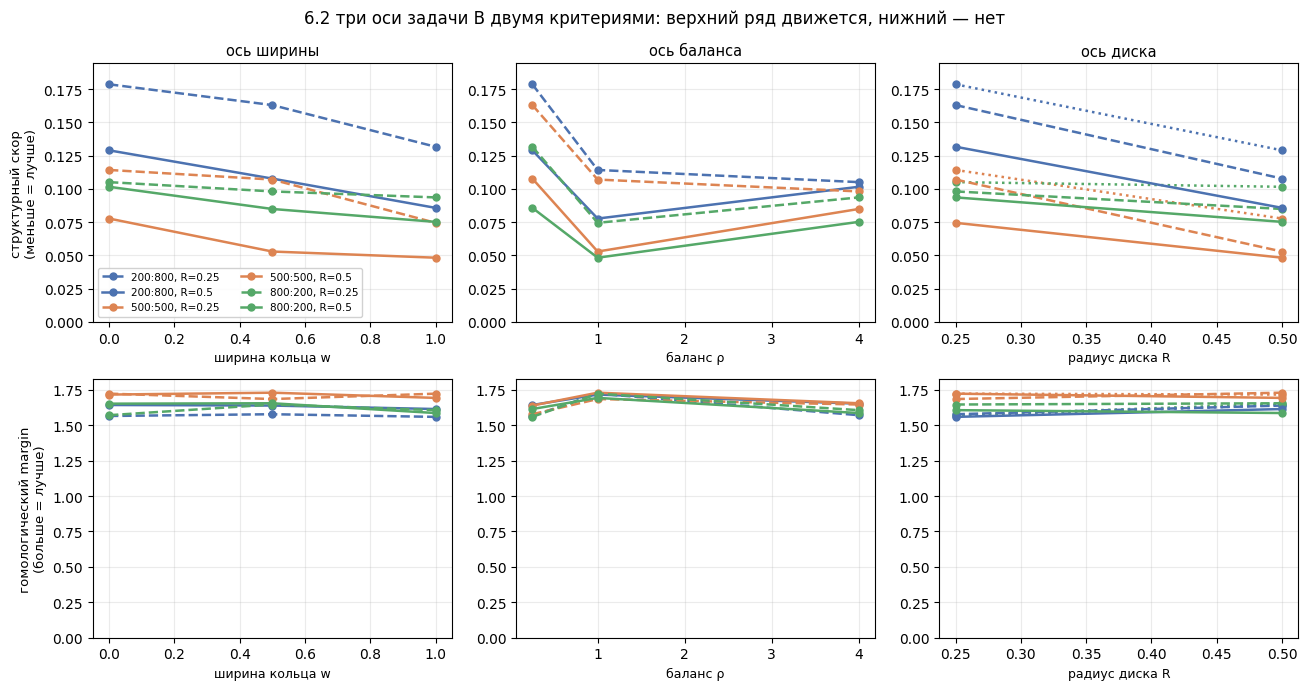

структурный скор по 18 ячейкам: 0.048-0.179 (размах в 3.7 раза)
гомологический margin:          1.560-1.731 (размах в 1.11 раза)
нейронов с петлёй в модели:     13-16 из 20 (эта величина до потолка не дошла, так что дело не в насыщении)


In [35]:
# Те же три оси задачи B, но каждая — двумя критериями сразу.
S = dsw.inner_edge(cells)
S = S[(S.task == "relevant") & (S.R < 1.0) & (S["T"] == 1000)]
H = dsw.inner_edge(homc[homc.feature_role == "target"])
H = H[(H.task == "relevant") & (H.R < 1.0) & (H["T"] == 1000)]

AXES = [
    {"axis": "w",   "xlabel": "ширина кольца w", "title": "ось ширины",
     "panels": [{"label": f"{dsw.n_ring_of(r,1000)}:{1000-dsw.n_ring_of(r,1000)}, R={R}",
                 "sel": {"rho": r, "R": R}, "colour": COL[r],
                 "ls": "-" if R == 0.5 else "--"} for r in RHO3 for R in (0.25, 0.5)]},
    {"axis": "rho", "xlabel": "баланс ρ", "title": "ось баланса",
     "panels": [{"label": f"w={w}, R={R}", "sel": {"w": w, "R": R},
                 "colour": {0.0:"#4c72b0",0.5:"#dd8452",1.0:"#55a868"}[w],
                 "ls": "-" if R == 0.5 else "--"} for w in W3 for R in (0.25, 0.5)]},
    {"axis": "R",   "xlabel": "радиус диска R", "title": "ось диска",
     "panels": [{"label": f"w={w}, ρ={ratio_label(r)}", "sel": {"w": w, "rho": r},
                 "colour": COL[r], "ls": {0.0:":",0.5:"--",1.0:"-"}[w]}
                for w in W3 for r in RHO3]},
]
fig = dplt.plot_criteria_axes(S, H, AXES,
    title="6.2 три оси задачи B двумя критериями: верхний ряд движется, нижний — нет")
plt.show()

print(f"структурный скор по 18 ячейкам: {S.med_target.min():.3f}-{S.med_target.max():.3f} "
      f"(размах в {S.med_target.max()/S.med_target.min():.1f} раза)")
print(f"гомологический margin:          {H.med_margin.min():.3f}-{H.med_margin.max():.3f} "
      f"(размах в {H.med_margin.max()/H.med_margin.min():.2f} раза)")
print(f"нейронов с петлёй в модели:     {H.med_n_positive.min():.0f}-{H.med_n_positive.max():.0f} из 20 "
      f"(эта величина до потолка не дошла, так что дело не в насыщении)")

### Что видно

**Верхний ряд движется, нижний стоит.** По тем же восемнадцати ячейкам структурный скор идёт от 0.048
до 0.179 — размах в **3.7 раза**; гомологический margin от 1.560 до 1.731 — размах в **1.11 раза**. Ни
одна из трёх осей не двигает второй критерий сколько-нибудь заметно: доля моделей с петлёй равна 1.00
в шестнадцати ячейках из восемнадцати и 0.96–0.98 в двух оставшихся.

**И это не насыщение шкалы.** Можно было бы возразить, что margin лучшего нейрона просто упёрся в
потолок. Но есть второй, ненасыщенный отсчёт — сколько нейронов модели несут петлю: он даёт 13–16 из
двадцати, то есть до потолка далеко, и по ячейкам тоже почти не движется.

**Слабое эхо баланса всё же есть.** Максимум margin приходится на `ρ = 1` (1.69–1.73 против 1.56–1.66
на краях), то есть та же форма, что у структурного скора, но в двадцать раз слабее по относительной
величине. Это ожидаемо: чтобы петля вообще построилась, точек должно хватать обоим объектам.

**Ось диска на гомологический критерий не действует** — 1.56–1.72 при `R = 0.25` против 1.59–1.73 при
`R = 0.5`, — тогда как структурный скор она двигает в девяти парах из девяти. Тот же рисунок, что и у
обучаемости (приложение): величины, меняющие **место** границы, не меняют факта её существования.

**Задача C, для полноты.** При `T = 5000` margin поднимается 1.59–1.73 → 1.78–1.79, согласованно во
всех шести парах, а доля остаётся 1.00. Больше точек — чище топология, но вердикт был насыщен и
остался.

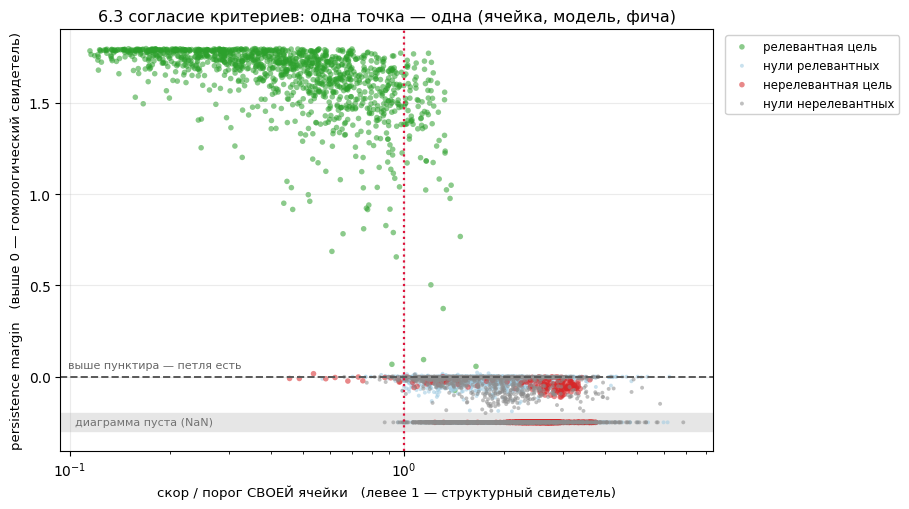

relevant   target n= 1250:  оба  1161 | только структурный    0 | только гомологический   86 | ни один     3
relevant   null   n= 2500:  оба     7 | только структурный   18 | только гомологический   27 | ни один  2448
irrelevant target n=  750:  оба     1 | только структурный   12 | только гомологический    0 | ни один   737
irrelevant null   n= 2250:  оба     1 | только структурный   29 | только гомологический    6 | ни один  2214



на уровне НЕЙРОНОВ (релевантные цели, слои 1-4, 25000 шт.): структурных 0.572, гомологических 0.704; структурных БЕЗ петли 14 из 14295


In [36]:
# Согласие двух критериев, единица наблюдения — (ячейка, модель, фича).
u = hom.merge(best.rename(columns={"score": "стр_скор"})[["dataset_type", "feature_name",
              "model_path", "стр_скор"]],
              on=["dataset_type", "feature_name", "model_path"], how="left")
thr = {(r.cell, r.family): r.threshold for r in cells.itertuples()}
u["score_over_threshold"] = [s / thr.get((c, f), np.nan)
                             for s, c, f in zip(u.стр_скор, u.dataset_type, u.family)]
u["стр"] = u.score_over_threshold <= 1.0

fig = dplt.plot_criteria_scatter(u, title="6.3 согласие критериев: одна точка — одна (ячейка, модель, фича)")
plt.show()

for task in ("relevant", "irrelevant"):
    for role in ("target", "null"):
        b = u[(u.task == task) & (u.feature_role == role)]
        both = int((b["стр"] & b.witness).sum()); so = int((b["стр"] & ~b.witness).sum())
        ho = int((~b["стр"] & b.witness).sum()); nn = int((~b["стр"] & ~b.witness).sum())
        print(f"{task:10s} {role:6s} n={len(b):5d}:  оба {both:5d} | только структурный {so:4d} | "
              f"только гомологический {ho:4d} | ни один {nn:5d}")
n = dsw.inner_edge(df)
n = n[(n.layer_id > 0) & (n.task == "relevant") & (n.feature_role == "target")].copy()
n["стр"] = [s <= thr.get((c, f), np.nan) for s, c, f in zip(n.score, n.dataset_type, n.family)]
n["гом"] = (n.margin > 0).fillna(False)
print(f"\nна уровне НЕЙРОНОВ (релевантные цели, слои 1-4, {len(n)} шт.): "
      f"структурных {n['стр'].mean():.3f}, гомологических {n['гом'].mean():.3f}; "
      f"структурных БЕЗ петли {int((n['стр'] & ~n['гом']).sum())} из {int(n['стр'].sum())}")

### Что видно

**Структурный свидетель почти всегда есть подмножество гомологического.** На релевантных целях из 1250
пар (ячейка, модель) оба критерия сработали у 1161, только гомологический — у 86, **только структурный
— ни у одной**, ни один — у трёх. На уровне отдельных нейронов то же самое: 14 нарушений на 14 295
структурных свидетелей, то есть 0.1 %. Иначе говоря: **если линия уровня легла на мишень, петля там
есть заведомо**; обратное неверно.

**Те самые 86 — это и есть «петля есть, но не на мишени».** Они не разбросаны по сетке, а собраны в
одном её углу: 77 из 86 приходятся на маленький диск `R = 0.25`, 61 из 86 — на `w = 0`. Это ровно тот
угол, где структурный скор хуже всего (§4.3) и где вердикт проходит меньше половины моделей (§4.1).
Значит там сеть строит замкнутую структуру, но проводит её не по внутреннему краю.

**На нерелевантной задаче гомологический критерий строже структурного.** Ложных срабатываний у него
1 из 750 против 13 из 750 у структурного. Те немногие «детекции», которые структурный критерий не
убирает никаким порогом (§2.7), почти все оказываются случаями, где петли нет вовсе.

### Вывод

**Оба критерия дают один и тот же вердикт о плотности, и это делает вывод эксперимента прочнее.**
Плотность не создаёт петлю там, где задача её не требует (0.001 против 0.998), и не улучшает её там,
где требует.

**Но говорят они о разном, и различие оказалось содержательным.** Топология — есть ли замкнутая
структура — присутствует всегда, когда задача её вынуждает, и не появляется, когда не вынуждает; она
не реагирует ни на ширину кольца, ни на радиус диска. Геометрия — где именно эта структура проходит —
меняется всеми геометрическими переменными сразу.

**Это прямо отвечает на вопрос, оставшийся открытым в §2.8.** Наблюдение «структура ближе к внутреннему
краю» не могло быть артефактом того, что петли где-то нет: петля есть почти везде и почти всегда. Что
меняется с геометрией — её положение. И это же объясняет, почему §4.1 и §4.3 двигают структурный скор,
а обучаемость (приложение) и гомологический критерий к ним равнодушны: просвет меняет **место**
границы, не меняя ни факта её существования, ни трудности задачи.

---

# 7. Что установлено

**Плотность точек особенности не участвует в появлении нейрона-свидетеля — ни как причина, ни как
модулятор.** Три независимых способа это проверить, и ни один не дал эффекта в её пользу:

* она **не создаёт** свидетеля там, где задача особенности не видит (задача A: доля 0.00–0.06 при
  медиане 0.02 во всех 15 нерелевантных ячейках, при пороге, пропускающем 1 % нулей; более того,
  цель там **хуже** своих нулей во всех 15, медианное `p_superior` = 0.18 с интервалом
  `[0.14, 0.27]`);
* она **не улучшает** свидетеля там, где особенность нужна (§4.1: на щупе, стоящем на неподвижном
  радиусе, трёхкратное разрежение точек кольца не двигает медиану — размах внутри строки 0.003–0.023
  без согласованного знака при 0.121 между строками. А там, где скор всё же движется — на мишени,
  едущей вместе с фичей, — он движется в сторону, ПРОТИВОПОЛОЖНУЮ гипотезе плотности: фича становится
  втрое реже, а отношение «пол / цель» вырастает вдвое);
* её **абсолютный уровень** ничего не решает (задача C: пятикратный подъём обеих плотностей сразу
  двигает медиану на 0.008–0.036 и вердикта не меняет — доля была 1.00 и осталась 0.98–1.00; и это
  подъём не только плотностей, но и чисел точек, то есть тот же эффект достаточности, что в §4.2).

**Второй критерий даёт тот же вердикт, и даёт его жёстче.** Гомологический `persistence_margin`
находит доминирующую петлю у 998 моделей из 1000 на релевантных целях и лишь у 1 из 750 на
нерелевантных; вдоль обеих осей задачи A он равен нулю везде, кроме одной ячейки с 0.02. Структурный
критерий мог бы промолчать оттого, что петля проходит не там, где мы смотрим; гомологический такой
лазейки не оставляет — он смотрит на всю окрестность и петли там не находит.

**Конфаунд, ради которого ставился эксперимент, закрыт.** Выводы экспериментов 1 и 2 о том, что
свидетель появляется из-за релевантности, поправки на плотность выборки не требуют.

**Что вместо плотности.** Число точек у каждого из двух объектов — скор лучший при равенстве и
деградирует, когда любой оголодал, причём голодание самой особенности вредит сильнее (худшая точка
при обеднённом кольце в 6 линиях из 6 и по скору, и по безразмерному «пол / цель»), — и **геометрия
пары**: просвет между фичей и внутренностью. Обе переменные двигают скор согласованно по знаку, чего
плотность не делает ни разу.

**Просвет — то, что на самом деле стоит за двумя из трёх осей.** Ширина кольца сужает его, придвигая
внутренний край к центру (нормированный скор улучшается в 6 строках из 6, отношение «пол / цель»
растёт с 1.4–3.3 до 3.2–7.9 — при том, что нормировка вдоль этой оси играет против улучшения), радиус
диска — с другой стороны, раздувая внутренность (9 пар из 9). Зона, где взаимодействуют два объекта разных
классов, лежит в этом зазоре, и чем он уже, тем плотнее она прижата к внутреннему краю. Матченные по
просвету пары показывают, что зазором эффект не исчерпывается: при равном просвете не хуже та ячейка,
где внутренность крупнее. **Релевантная особенность есть свойство пары, а не одной фичи** — и это
измерено с двух независимых сторон.

**Структура сидит у внутреннего края особенности**, на контакте с внутренностью противоположного
класса. Скобка из трёх концентрических щупов даёт 5.38 → 2.32 → 1.14 по отношению «пол / цель» от
внутреннего края к внешнему при `w = 1.0` (и 3.48 → 2.32 → 1.60 при `w = 0.5`), в 18 конфигурациях из
18 и во всех трёх единицах измерения. Причинного прочтения это не получает: контакт с внутренностью и
потеря круглости у «шапки» по мере удаления от экстремума предсказывают здесь одно и то же, а кольцо
с диском концентричны во всех сорока ячейках. Различить их — вопрос эксперимента 5.

**Задача видна и на выходе сети.** Голова свидетельствует о релевантной цели в 100 случаях из 100 и
молчит на всех 47 нерелевантных целях и на 802 нулях из 803.

**Топология присутствует всегда, когда задача её требует; меняется только её положение.** По тем же
восемнадцати ячейкам структурный скор проходит размах в 3.7 раза, а гомологический margin — в 1.11
раза; доля моделей с петлёй равна 1.00 в шестнадцати ячейках из восемнадцати. Ни ширина кольца, ни
радиус диска на второй критерий не действуют. И структурный свидетель оказывается **подмножеством**
гомологического: на релевантных целях 1161 модель прошла оба критерия, 86 — только гомологический,
и **ни одна — только структурный**. Те 86 собраны в одном углу сетки (77 из 86 при маленьком диске),
и это ровно тот угол, где структурный скор хуже всего. Значит там сеть строит замкнутую структуру, но
проводит её не по внутреннему краю.

**Обучаемость — второй прибор на той же сетке.** По балансу и по ширине она отвечает теми же
переменными и в ту же сторону, что и скор; по радиусу диска — не отвечает вовсе, и это само по себе
информативно: диск меняет не трудность задачи, а место, где проходит граница.

**Связь с экспериментом 1 держится.** Якорная ячейка с его геометрией (окружность 500 точек вокруг
диска `r = 1.0` из 500 точек), пересчитанная в новом боксе, воспроизвела его числа: медиана лучшего
нейрона 0.0314 против 0.0349, свидетель у 50 моделей из 50 против 49 из 50, `p_superior = 1.0000`.

## Что переносится в следующие эксперименты

* **Мишень вердикта — внутренний край особенности**; средняя окружность нужна только там, где
  меряется тренд вдоль оси, по которой внутренний край переезжает. Кольцо мишенью не брать — из-за
  низкой различающей способности (1.57 против 4.79 у внутреннего края). Внешняя окружность своего
  вопроса не несёт (1.19, местами хуже случайности).
* **Мишень есть сэмпл области пространства, а не подмножество обучающей выборки**, и её шаг —
  параметр прибора: требуется `δ(A) < h`. Проверено измерением: потолки трёх окружностей
  0.0337 / 0.0342 / 0.0360 при `h/2 = 0.0339`.
* **Порог берётся из собственных нулей мишени в своей ячейке** — **1-й перцентиль**, по всему полу
  этой ячейки, — и не наследуется. τ = 0.1 из экспериментов 1 и 2 здесь не применим: пороги мишени
  вердикта идут 0.14–0.38 по сорока ячейкам.
* **Вердикт двухсоставный**: скор ниже порога И свидетельство, пережившее композицию до самой головы.
  Первое условие пропускает 296 ложных срабатываний, второе не пропускает ни одного.
* **Мишени разного размера сравнимы только по безразмерным отношениям** — «пол / цель» и
  «достигнутое / потолок»; сырой нормированный скор для этого не годится.
* **Два критерия читаются на одних и тех же строках и отвечают на разные вопросы**: гомологический —
  есть ли замкнутая структура, структурный — где она проходит. Margin нельзя сравнивать между
  мишенями: критерий смотрит на окрестность в 1.5 радиуса мишени, и окрестность растёт вместе с ней.
* **Плотность можно вычеркнуть из списка конфаундов**; на её место в список рабочих переменных
  становятся число точек объекта и геометрия внутренности.
* **Пол мерить в своей ячейке и по размещениям**, а не одним числом: медиана пола по трём
  размещениям идёт 0.46 / 0.58 / 0.67 — разброс до трети величины.
* **Доля успеха обучения отчитывается как результат.**

## Границы применимости

* **Есть ли свидетель и насколько он хорош — да; где именно он стоит — только грубо.** Структурный
  критерий есть минимум по уровням; локализация §2.8 получена скобкой из трёх щупов, а не
  измерением положения линии уровня.
* **Ось ширины даёт два неравных шага.** Разрежение от `w = 0` к `0.5` сильнее, чем от `0.5` к
  `1.0`; читать по этой оси надо наличие и знак эффекта, а не наклон.
* **Ось диска не разложена.** Радиус меняет геометрию внутренности, её площадную плотность и просвет
  одновременно; просвет по дизайну удерживается выше 0.5 и переменной не считается, но геометрия и
  плотность диска на этой сетке не разделены.
* **Пол вердикта опирается на два размещения нулей** — в task-relevant задаче коридора нет.
* **Перцентиль есть имя правила, а не измеренная частота ошибок** (§2.7): вне выборки нулей, по
  которой он поставлен, он реализуется примерно вдвое-втрое чаще номинала.
* **Ансамбли обусловлены прохождением гейта**, и в худших ячейках это заметно (§6).
* **Выравнивание, а не кодирование.** Абляции здесь нет, как не было в экспериментах 1 и 2;
  вмешательство только в данные, не в сеть.
* **Одна форма особенности, одна активация, одна архитектура.** Абсолютные уровни пола на другие
  задачи не переносятся; переносится метод.

---

# Приложение. Задача E — обучаемость ячейки как второй исход

*Эта задача не входит в основную линию A → B → C → F: она возникла из самого прогона, а не из
плана, и меряет не нейроны, а то, как часто случайная инициализация доходит до гейта. Вынесена
в приложение, чтобы не разрывать повествование; на её результат ссылаются §6 и §7.*

**Вопрос.** Гейт эксперимента — 100 % test accuracy. Серверный прогон показал, что в части ячеек до
него доходят не все инициализации. Это шум расписания или измерение?

**Зачем это нужно.** Задача возникла не по плану — её принёс сам прогон. Но она попадает точно в
предмет эксперимента: если задача перестаёт **жёстко** вынуждать замкнутую границу, это должно быть
видно не только в скоре нейронов, но и в том, как часто случайная инициализация доходит до идеального
разделения. То есть это второй прибор, меряющий ту же вещь.

**Как проверяем.** Доля из 50 инициализаций, дошедших до гейта на первом проходе, против медианного
скора той же ячейки. Это единственная запись о неудачах: сохранённые артефакты содержат только
успешные модели, поэтому числа занесены в `analysis.density_sweep.FIRST_PASS_SUCCESSES` из лога
прогона. Ансамбли потом добраны до 50, так что по `N` все ячейки сравнимы.

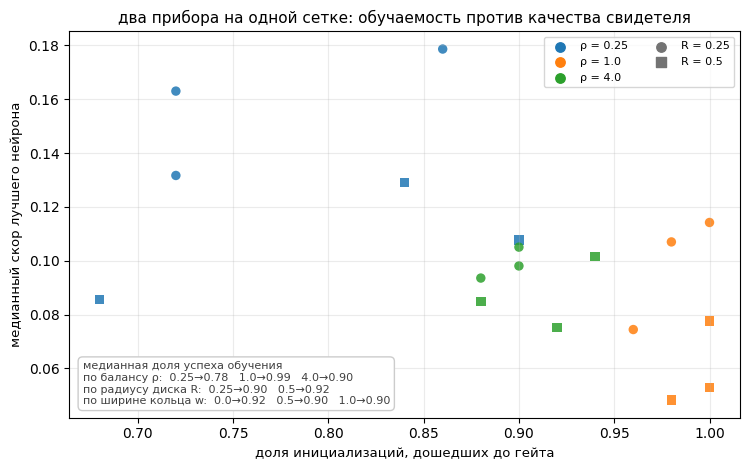

In [37]:
tr = dsw.trainability_table(cells)
merged = (EDGE[(EDGE.task == "relevant") & (EDGE.R < 1.0) & (EDGE["T"] == 1000)]
          .merge(tr[["cell", "доля успеха"]], on="cell"))
fig = dplt.plot_two_outcomes(merged,
    title="два прибора на одной сетке: обучаемость против качества свидетеля")
plt.show()

### Что видно

**Все 15 task-irrelevant ячеек обучились с первой попытки полностью — 50 из 50.** Все отказы без
исключения на task-relevant стороне, и худшая ячейка — `w = 1.0, R = 0.5, ρ = 0.25` — набрала 34 из 50.

**По балансу два прибора согласны, и обучаемость говорит даже чище.** Медианная доля успеха 0.99 при
`ρ = 1`, 0.90 при `ρ = 4` и 0.78 при `ρ = 0.25`; максимум приходится на равенство **в шести линиях из
шести** — там, где скор давал четыре из шести (§4.2). Асимметрия та же: обеднённое кольцо хуже
обеднённого диска.

**По ширине кольца оба прибора тоже согласны — не движется ничего.** Медианы 0.92 / 0.90 / 0.90, размах
внутри линии 0.02–0.22 без согласованного знака, ровно как у скора на неподвижном щупе (§4.1).

**А вот по радиусу диска приборы расходятся, и это надо назвать прямо.** Скор улучшался при большем
диске в девяти парах из девяти (§4.3); обучаемость — лишь в пяти из девяти, в трёх хуже и в одной
поровну, медианы 0.90 против 0.92. Обучаемость к этой оси попросту нечувствительна.

**Облако на графике упорядочено, и упорядочено оно по балансу.** Ячейки с плохой обучаемостью — те же,
у которых хуже скор, и разделяются они цветом, то есть балансом. Если бы один из приборов мерил шум,
порядка бы не было.

### Выводы

**Обучаемость — второй исход эксперимента, а не помеха.** По двум осям из трёх она отвечает теми же
переменными и в ту же сторону, что и скор нейронов, а по балансу — даже определённее.

**Расхождение по оси диска содержательно, а не досадно.** Обучаемость меряет, насколько трудно сети
дойти до идеального разделения; скор меряет, насколько точно линия уровня ложится на внутренний край.
Радиус диска двигает второе и не двигает первое — то есть он меняет не трудность задачи, а **место**,
где проходит граница. Это ровно то прочтение, к которому пришёл §4.3 через просвет, и здесь оно
получает независимую поддержку: будь эффект диска эффектом трудности, обучаемость обязана была бы
пойти за ним.

**Оговорка об отборе, которую надо держать при чтении всех предыдущих разделов.** Ансамбли везде
обусловлены прохождением гейта, и доля прохождения по ячейкам разная: «50 из 50» на одном краю сетки
против «50 примерно из 74» на другом. Добор до полного `N` эту обусловленность не убирает.
Направление смещения консервативно — отбираются модели, решившие задачу идеально, то есть смещение
работает **в пользу** появления свидетеля там, где он и так находится.

**Инженерное следствие уже внесено в код.** Цикл обучения теперь считает успехи, а не попытки: до
100 попыток с остановкой на нужном числе успехов, исчерпанный потолок печатается громко. Ячейка, не
набравшая ансамбль за 100 попыток, — утверждение о задаче, и её должен смотреть человек.